In [ ]:
#Base imports
import ee
import csv
import pandas as pd
from google.colab import drive

#Mount GDrive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%%capture
!pip install osmnx
!pip install rasterio geopandas contextily shapely pyproj fiona rtree h3 optuna

Waste site presence

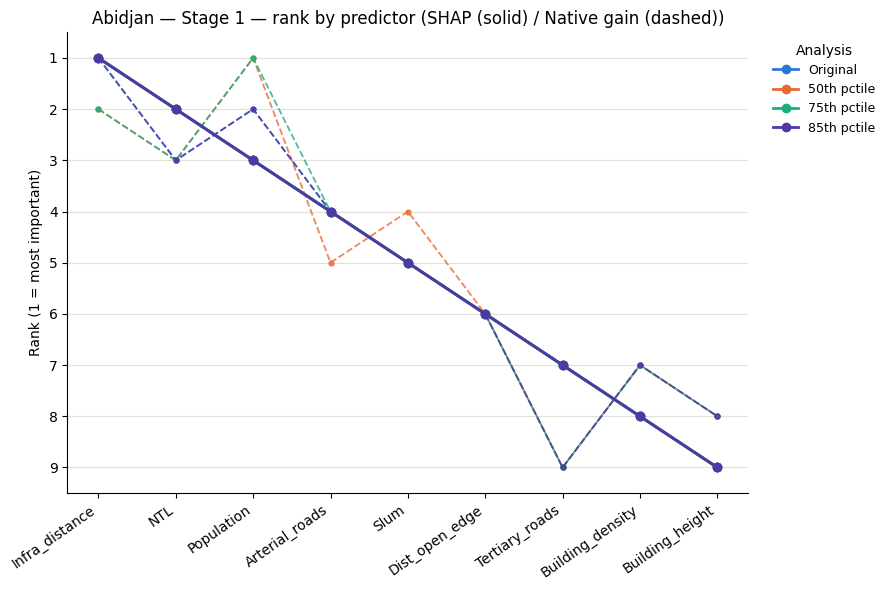

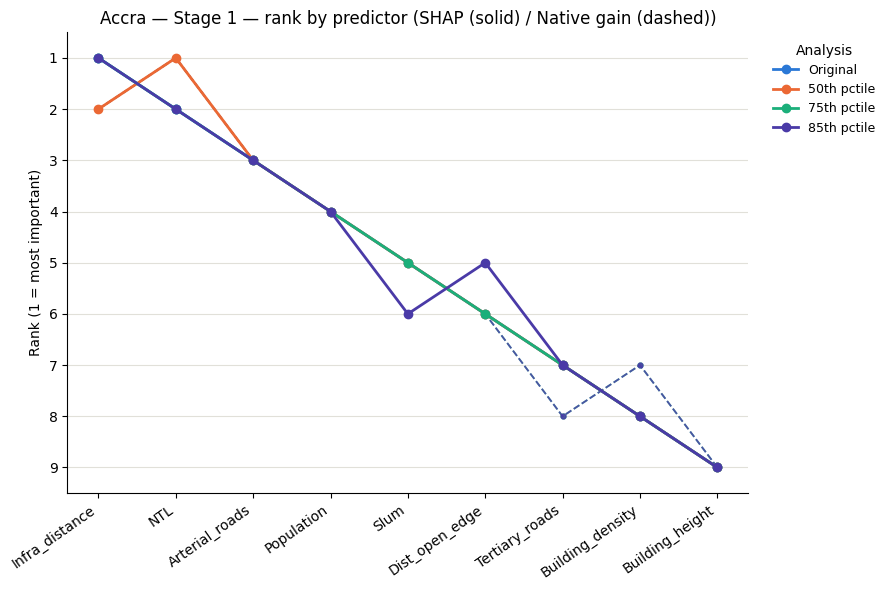

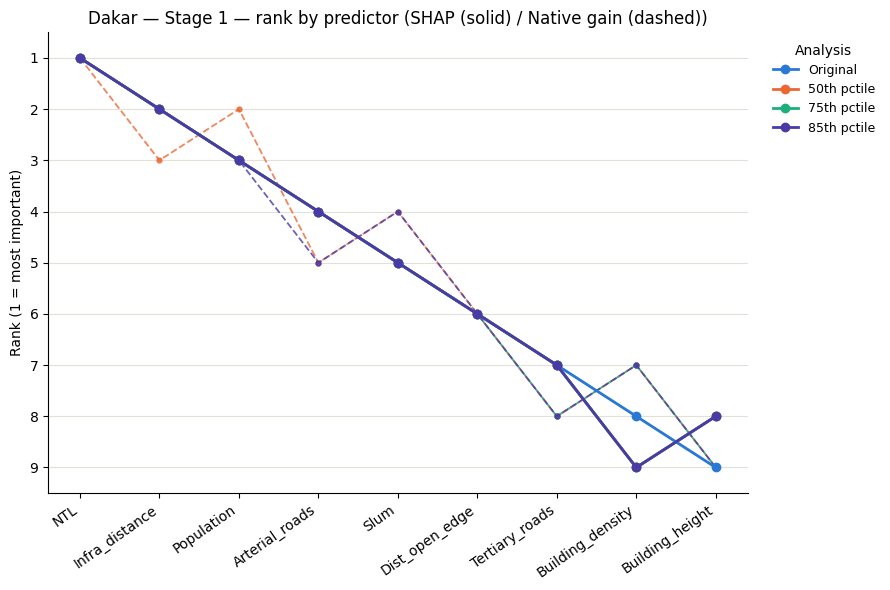

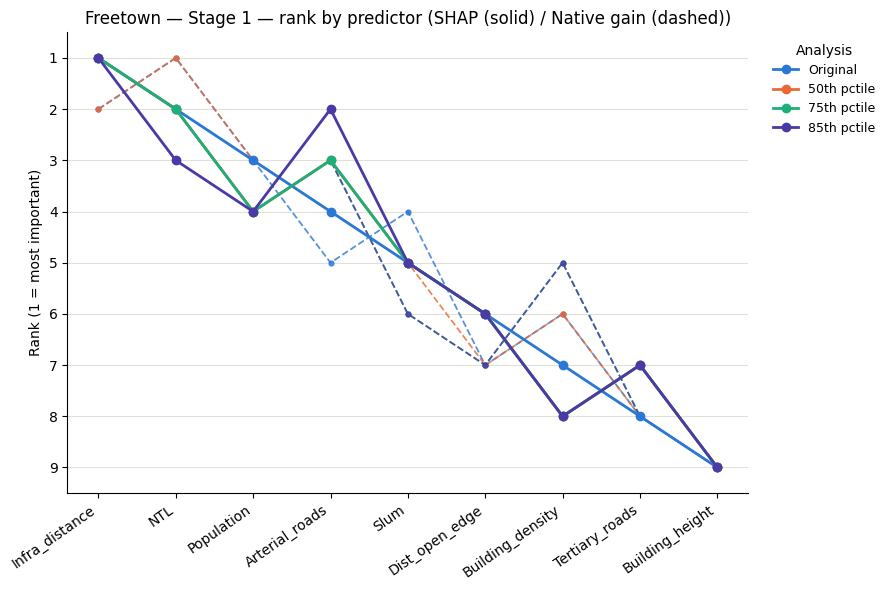

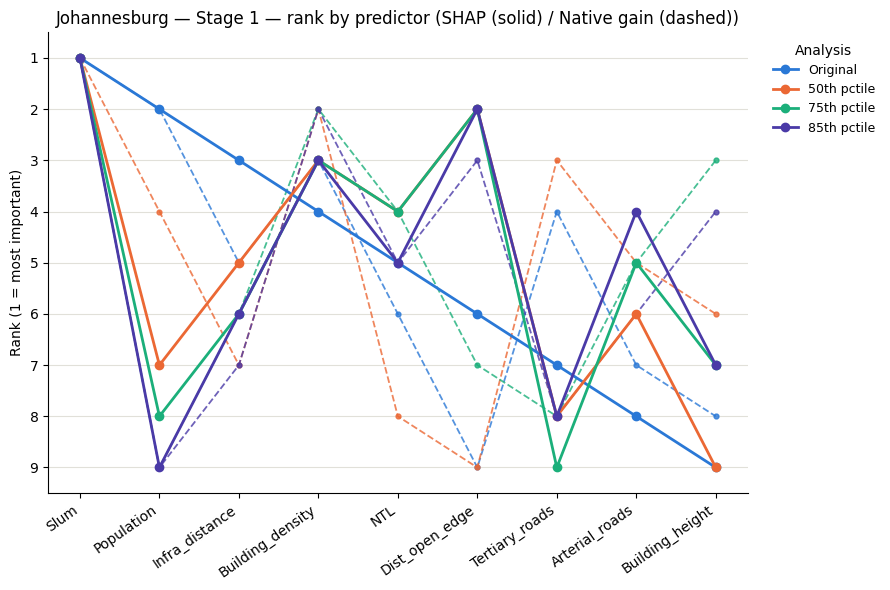

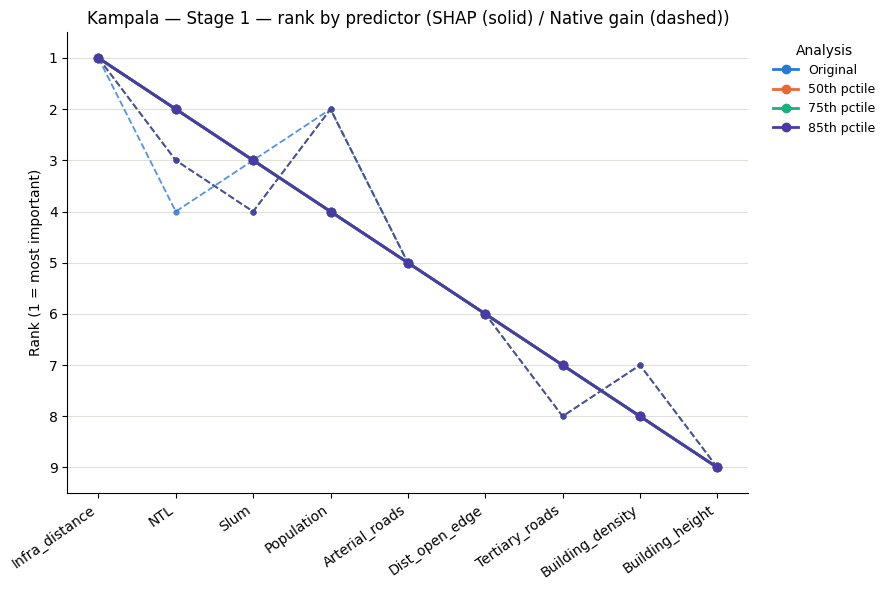

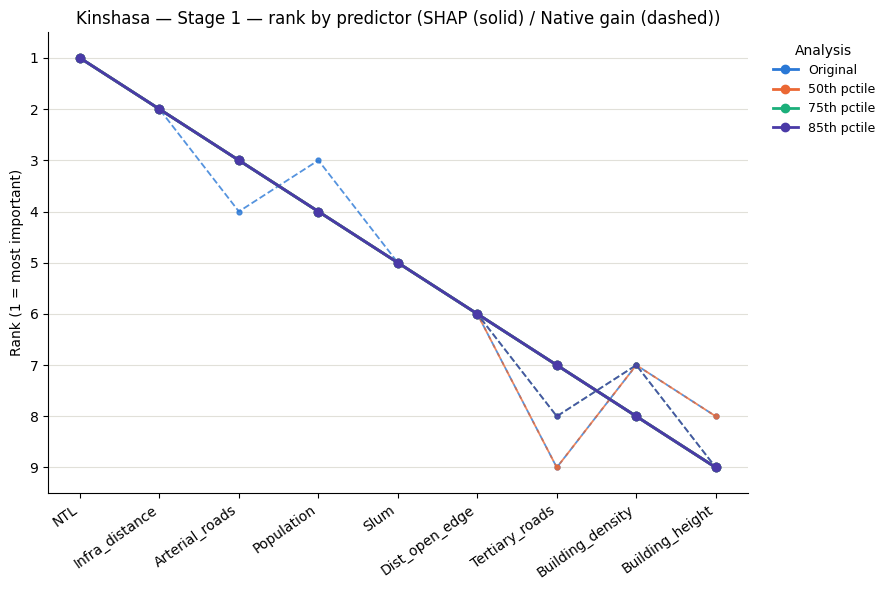

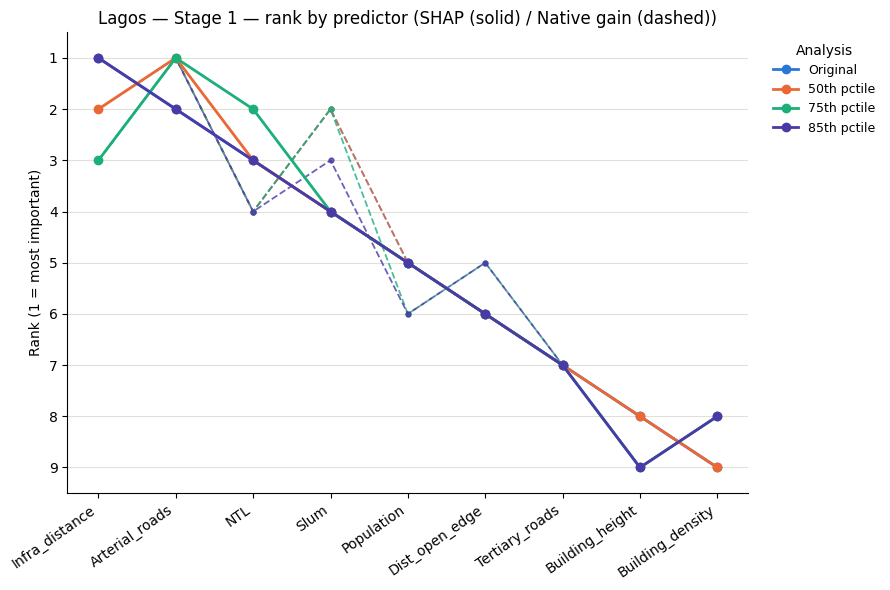

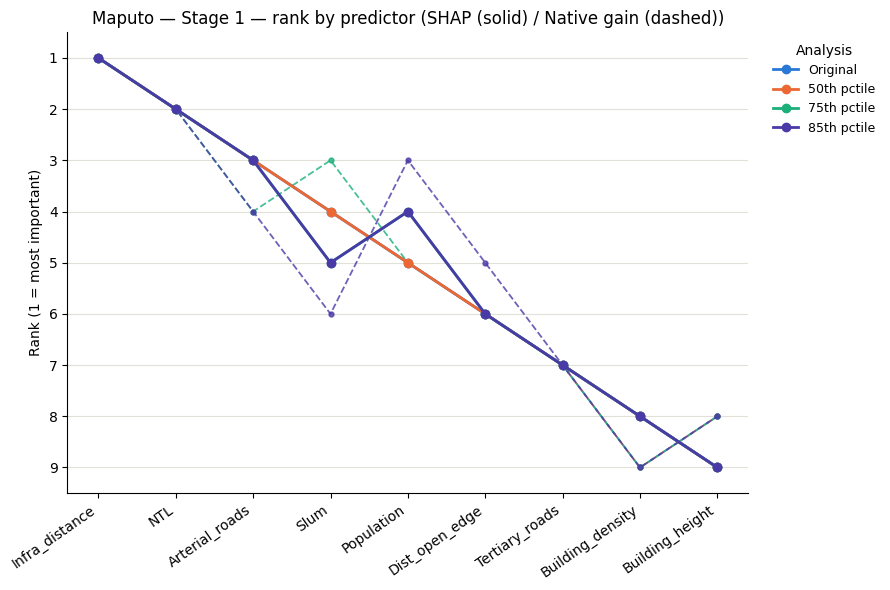

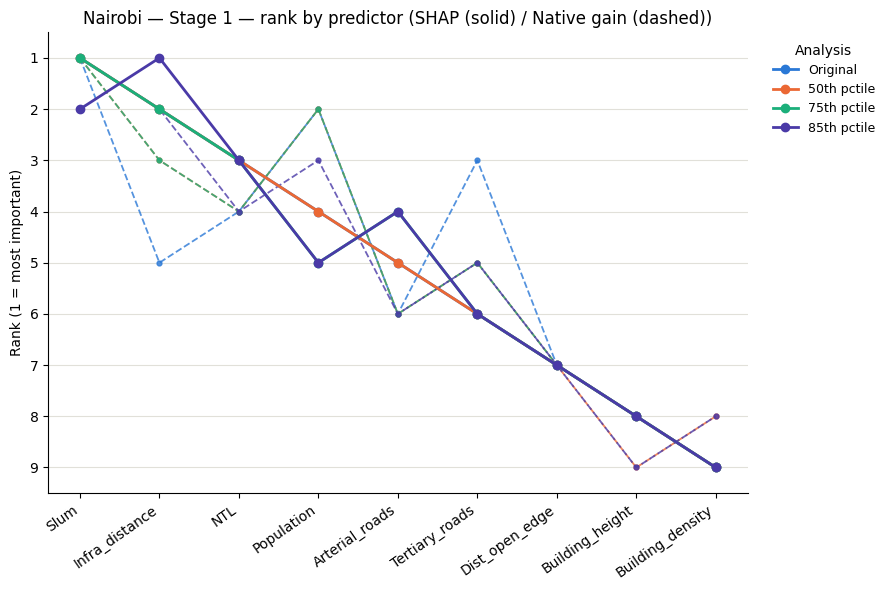


STAGE 1 — average SHAP rank per city (mean across Original/50/75/85th)
city              Abidjan  Accra  Dakar  Freetown  Johannesburg  Kampala  Kinshasa  Lagos  Maputo  Nairobi  avg    sd
predictor                                                                                                            
Infra_distance        1.0    1.2    2.0       1.0           5.0      1.0       2.0    1.8     1.0      1.8  1.8  1.21
NTL                   2.0    1.8    1.0       2.2           4.5      2.0       1.0    2.8     2.0      3.0  2.2  1.02
Arterial_roads        4.0    3.0    4.0       3.0           5.8      5.0       3.0    1.5     3.0      4.5  3.7  1.23
Slum                  5.0    5.2    5.0       5.0           1.0      3.0       5.0    4.0     4.5      1.2  3.9  1.61
Population            3.0    4.0    3.0       3.8           6.5      4.0       4.0    5.0     4.5      4.5  4.2  1.01
Dist_open_edge        6.0    5.8    6.0       6.0           3.0      6.0       6.0    6.0     6.0     

In [ ]:
"""
Rank stability chart: tracks each predictor's SHAP rank and native-gain rank
across the 4 analyses (Original, 50th pctile, 75th pctile, 85th pctile) for
a given city + stage.

Reads:
  Original:    /content/drive/MyDrive/Paper_3/Processing/DV/Combined/{City}/{c}_stage{N}_results.csv
  Sensitivity: /content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity/{City}/{c}_stage{N}_sensitivity_results.csv

Run in Colab after mounting Drive.
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

# Stage 1/2 use level predictors; Stage 3/4 use delta predictors.
# Adjust PREDICTORS per stage when running Stage 2-4.
PREDICTOR_BASE = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]

# Cove categorical palette (fixed order) + gray fallback for the 9th series
PALETTE = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
    "#008300", "#4a3aa7", "#e34948", "#767671",
]

LABELS = ["Original", "50th pctile", "75th pctile", "85th pctile"]


def load_ranks(city, stage, predictors=PREDICTOR_BASE):
    """Returns dict: predictor -> {'shap': [4 ranks], 'native': [4 ranks]}"""
    c = city.lower()

    orig = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_stage{stage}_results.csv").iloc[0]
    sens = pd.read_csv(f"{SENSITIVITY_DIR}/{city}/{c}_stage{stage}_sensitivity_results.csv")
    sens = sens.set_index("percentile")

    ranks = {}
    for p in predictors:
        shap_seq = [
            orig[f"{p}_shap_rank"],
            sens.loc[50, f"{p}_shap_rank"],
            sens.loc[75, f"{p}_shap_rank"],
            sens.loc[85, f"{p}_shap_rank"],
        ]
        native_seq = [
            orig[f"{p}_native_rank"],
            sens.loc[50, f"{p}_native_rank"],
            sens.loc[75, f"{p}_native_rank"],
            sens.loc[85, f"{p}_native_rank"],
        ]
        ranks[p] = {"shap": shap_seq, "native": native_seq}
    return ranks


def plot_rank_stability(city, stage, predictors=PREDICTOR_BASE, save_path=None):
    """Original orientation: predictors as separate lines, x-axis = the 4 analyses."""
    ranks = load_ranks(city, stage, predictors)
    n = len(predictors)

    fig, ax = plt.subplots(figsize=(9, 6.5))
    x = range(len(LABELS))

    for i, p in enumerate(predictors):
        color = PALETTE[i % len(PALETTE)]
        ax.plot(x, ranks[p]["shap"], color=color, linewidth=2,
                marker="o", markersize=6, label=p, zorder=3)
        ax.plot(x, ranks[p]["native"], color=color, linewidth=1.3,
                linestyle="--", marker="o", markersize=3.5, alpha=0.85, zorder=2)

    ax.set_xticks(list(x))
    ax.set_xticklabels(LABELS)
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    ax.set_title(f"{city} — Stage {stage} — SHAP vs native rank stability")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

    # Predictor legend (color)
    predictor_handles = [mlines.Line2D([], [], color=PALETTE[i % len(PALETTE)],
                                        linewidth=2, label=p)
                          for i, p in enumerate(predictors)]
    # Line-style legend (solid=SHAP, dashed=native)
    style_handles = [
        mlines.Line2D([], [], color="black", linewidth=2, label="SHAP rank"),
        mlines.Line2D([], [], color="black", linewidth=1.3, linestyle="--", label="Native gain rank"),
    ]

    leg1 = ax.legend(handles=predictor_handles, bbox_to_anchor=(1.02, 1), loc="upper left",
                      fontsize=9, title="Predictor", frameon=False)
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, bbox_to_anchor=(1.02, 0.25), loc="upper left",
               fontsize=9, frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


# Colors for the 4 analysis types (distinct from the predictor palette above)
ANALYSIS_COLORS = {
    "Original": "#2a78d6",
    "50th pctile": "#eb6834",
    "75th pctile": "#1baf7a",
    "85th pctile": "#4a3aa7",
}


def plot_rank_stability_by_predictor(city, stage, predictors=PREDICTOR_BASE,
                                      order_by="Original", metric="both", save_path=None):
    """
    Alternate orientation: x-axis = predictors, y-axis = rank, one line per
    analysis (Original/50th/75th/85th). Predictors are ordered along the
    x-axis by their SHAP rank in `order_by` (default: Original) so the line
    for that analysis reads as a clean descending staircase.

    metric: "shap", "native", or "both" (both = solid SHAP + dashed native,
    same color per analysis).
    """
    ranks = load_ranks(city, stage, predictors)
    n = len(predictors)

    # Order predictors by their SHAP rank under the reference analysis
    ref_idx = LABELS.index(order_by)
    ordered_predictors = sorted(predictors, key=lambda p: ranks[p]["shap"][ref_idx])

    fig, ax = plt.subplots(figsize=(9, 6))
    x = range(n)

    for li, label in enumerate(LABELS):
        color = ANALYSIS_COLORS[label]
        if metric in ("shap", "both"):
            y_shap = [ranks[p]["shap"][li] for p in ordered_predictors]
            ax.plot(x, y_shap, color=color, linewidth=2, marker="o",
                     markersize=6, label=label, zorder=3)
        if metric in ("native", "both"):
            y_native = [ranks[p]["native"][li] for p in ordered_predictors]
            ax.plot(x, y_native, color=color, linewidth=1.3, linestyle="--",
                     marker="o", markersize=3.5, alpha=0.8, zorder=2,
                     label=None if metric == "both" else label)

    ax.set_xticks(list(x))
    ax.set_xticklabels(ordered_predictors, rotation=35, ha="right")
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    metric_label = {"shap": "SHAP", "native": "Native gain", "both": "SHAP (solid) / Native gain (dashed)"}[metric]
    ax.set_title(f"{city} — Stage {stage} — rank by predictor ({metric_label})")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9,
              title="Analysis", frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def summary_table_all_cities(cities, stage, predictors=PREDICTOR_BASE):
    """
    Pretty-print summary: for each city, each predictor's average SHAP rank
    (mean across Original/50th/75th/85th), plus an overall average rank and
    SD across cities. Lower rank = more important.
    """
    all_rows = []
    for city in cities:
        ranks = load_ranks(city, stage, predictors)
        for p in predictors:
            seq = ranks[p]["shap"]
            all_rows.append({"city": city, "predictor": p, "avg_rank": sum(seq) / len(seq)})
    df = pd.DataFrame(all_rows)

    pivot = df.pivot(index="predictor", columns="city", values="avg_rank").round(1)
    pivot["avg"] = pivot[cities].mean(axis=1).round(1)
    pivot["sd"] = pivot[cities].std(axis=1).round(2)
    pivot = pivot.sort_values("avg")

    print("\n" + "=" * 70)
    print(f"STAGE {stage} — average SHAP rank per city (mean across Original/50/75/85th)")
    print("=" * 70)
    print(pivot.to_string())
    print("\nLower = more important. 'sd' = spread of each predictor's avg rank across cities.")

    return df, pivot


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    stage = 1
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    for city in cities:
        plot_rank_stability_by_predictor(city, stage)  # save_path=None -> not written to Drive

    long_df, summary_pivot = summary_table_all_cities(cities, stage)

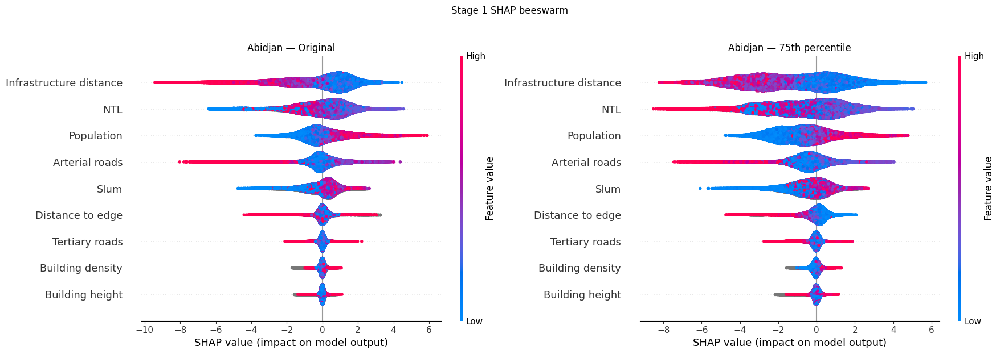

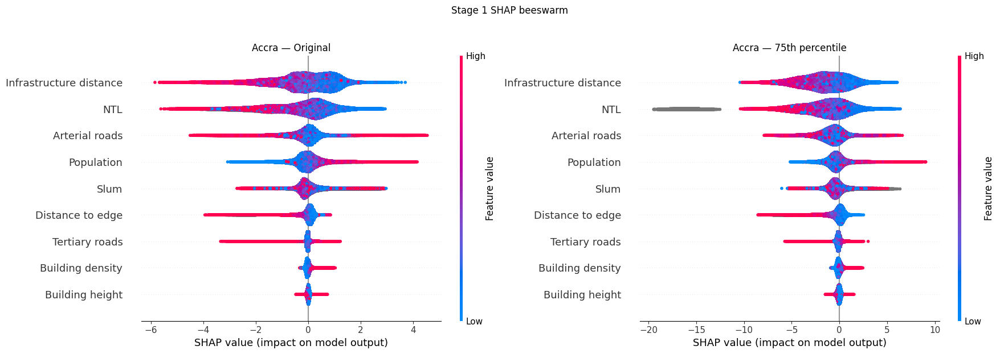

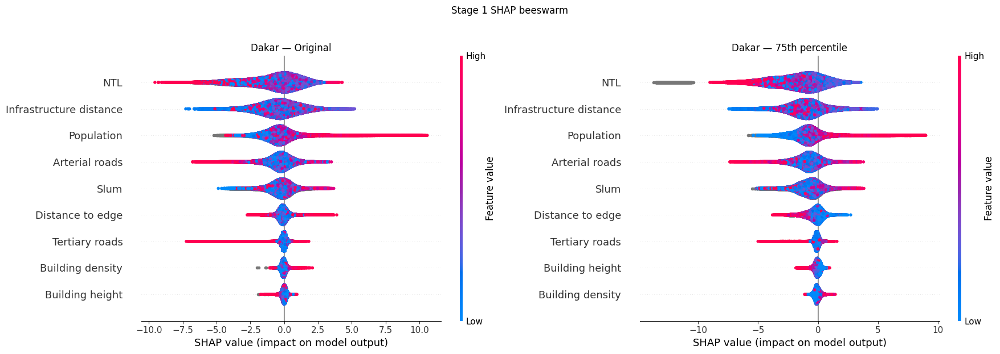

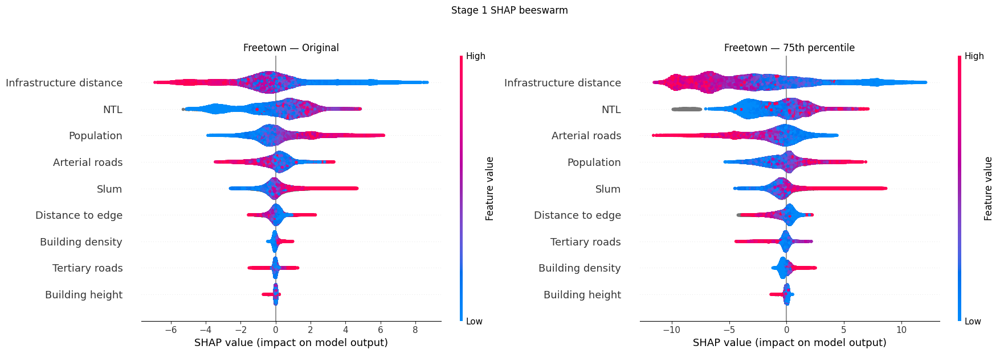

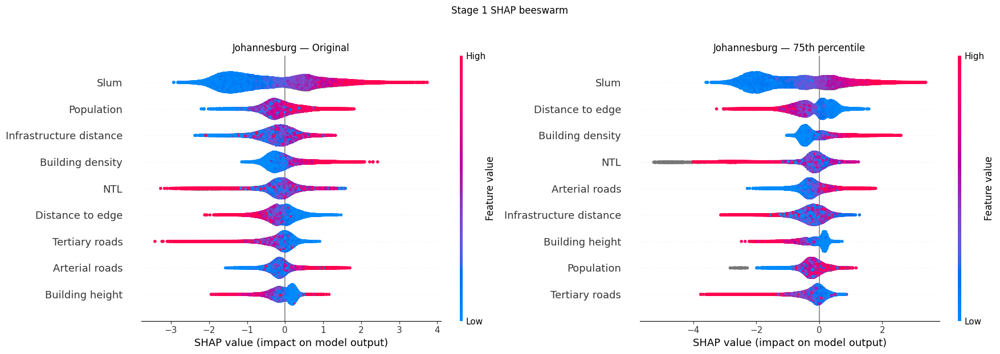

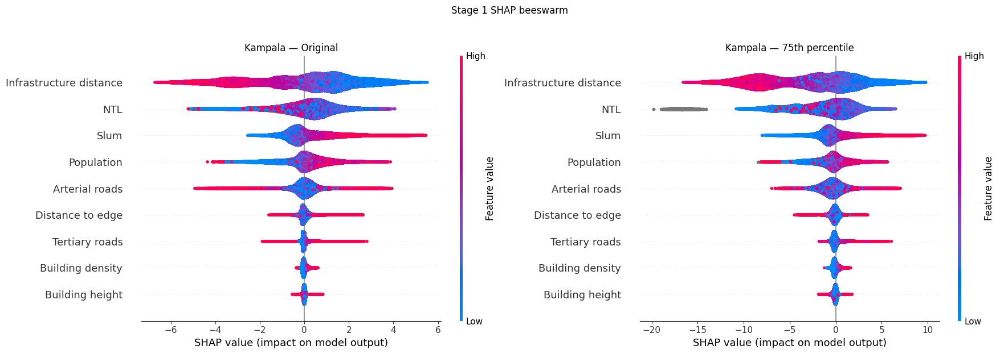

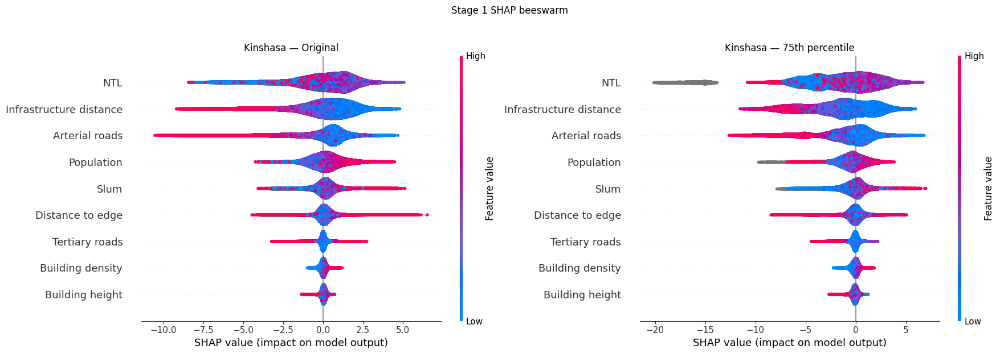

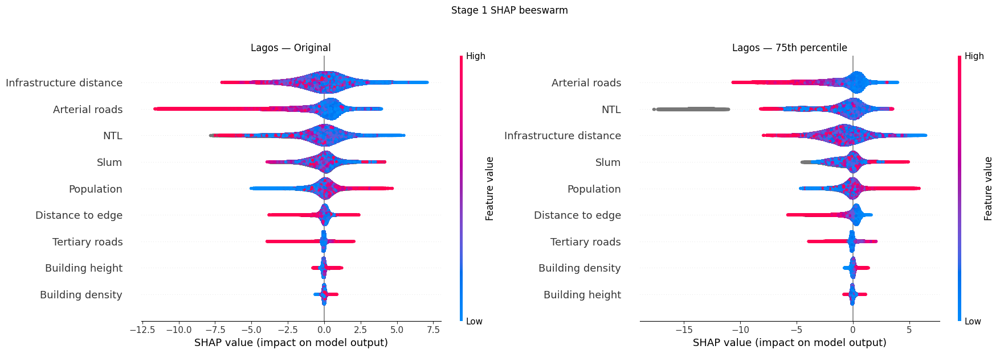

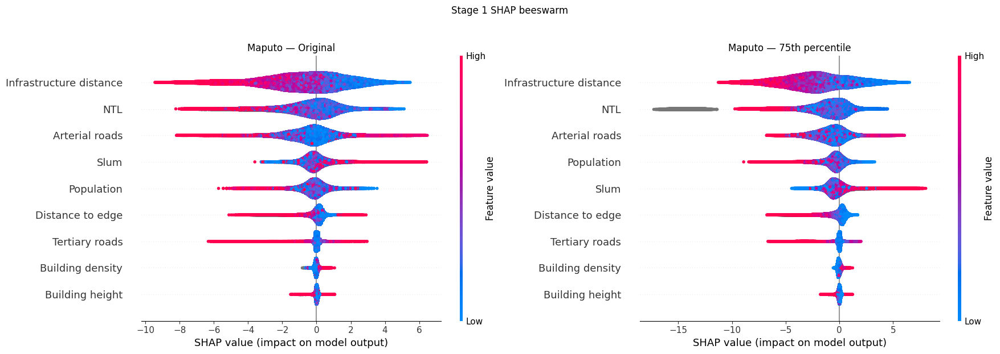

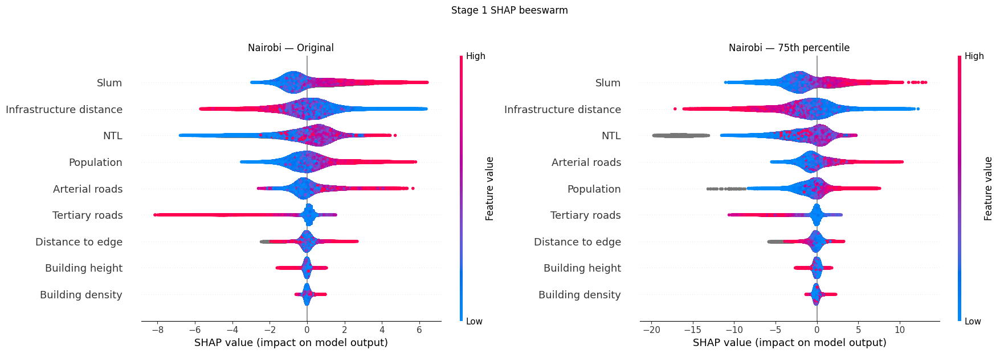

In [ ]:
"""
SHAP beeswarm plots, two columns per city: Original vs {percentile}th percentile.
Run in Colab after mounting Drive. Not saved to Drive — displays inline only.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

PREDICTOR_BASE = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]

# Display labels for plots (order must match PREDICTOR_BASE)
LABEL_MAP = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}
FEATURE_LABELS = [LABEL_MAP[p] for p in PREDICTOR_BASE]


def rebuild_stage1_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 1 SHAP values were computed, so it
    lines up row-for-row with the saved .npy array.

    percentile=None -> original full-data X.
    percentile=50/75/85 -> percentile-filtered X (Present rows >= cutoff,
                            concatenated with all Absent rows), matching the
                            sensitivity script's build_stage1_data().
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in PREDICTOR_BASE}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        return sub

    stacked = pd.concat(
        [build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")],
        ignore_index=True,
    )
    stacked["target"] = (stacked["DV"] > 0).astype(int)

    if percentile is None:
        return stacked[PREDICTOR_BASE]

    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = present_pool.quantile(percentile / 100)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[PREDICTOR_BASE]


def plot_shap_beeswarm_grid(cities, stage=1, percentile=75, max_display=9):
    """Two-column SHAP beeswarm figure per city: Original (left) vs {percentile}th (right)."""
    for city in cities:
        c = city.lower()

        shap_orig = np.load(f"{COMBINED_DIR}/{city}/{c}_stage{stage}_shap_values.npy")
        X_orig = rebuild_stage1_X(city, percentile=None)

        shap_pct = np.load(f"{SENSITIVITY_DIR}/{city}/{c}_stage{stage}_shap_values_pct{percentile}.npy")
        X_pct = rebuild_stage1_X(city, percentile=percentile)

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))

        plt.sca(axes[0])
        # plot_size=None stops shap from resizing the whole figure on each call
        shap.summary_plot(shap_orig, X_orig, feature_names=FEATURE_LABELS,
                           max_display=max_display, show=False, plot_size=None)
        axes[0].set_title(f"{city} — Original")

        plt.sca(axes[1])
        shap.summary_plot(shap_pct, X_pct, feature_names=FEATURE_LABELS,
                           max_display=max_display, show=False, plot_size=None)
        axes[1].set_title(f"{city} — {percentile}th percentile")

        fig.suptitle(f"Stage {stage} SHAP beeswarm", y=1.03)
        plt.tight_layout()
        plt.show()  # not saved to Drive


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    plot_shap_beeswarm_grid(cities, stage=1, percentile=75)

Persistence model analysis

STAGE 2 FILE VALIDATION — 10 cities checked
All clear — every city has both files with the expected structure.


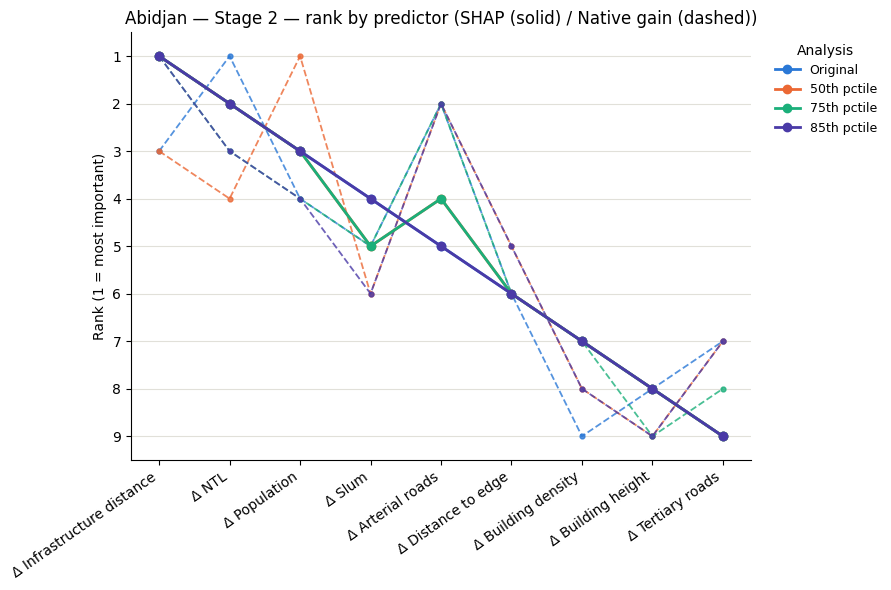

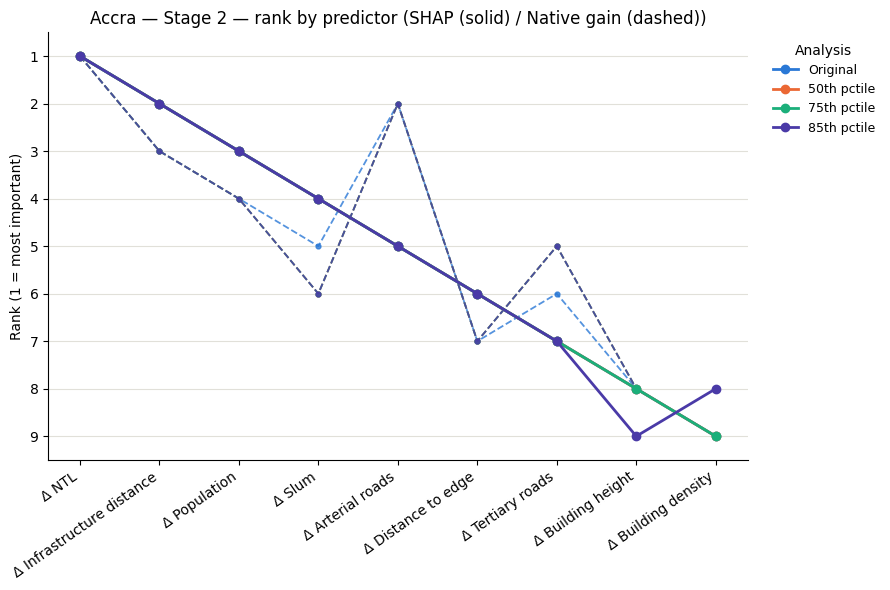

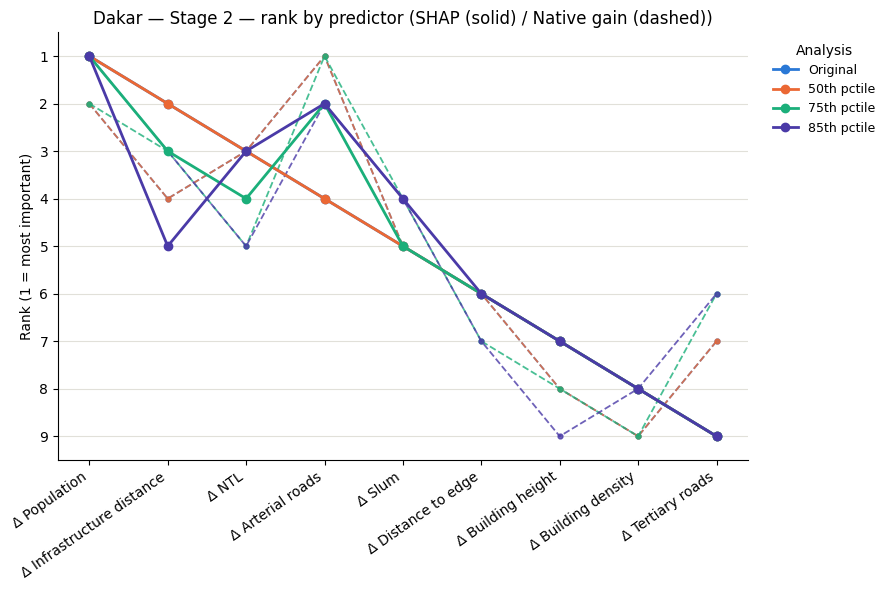

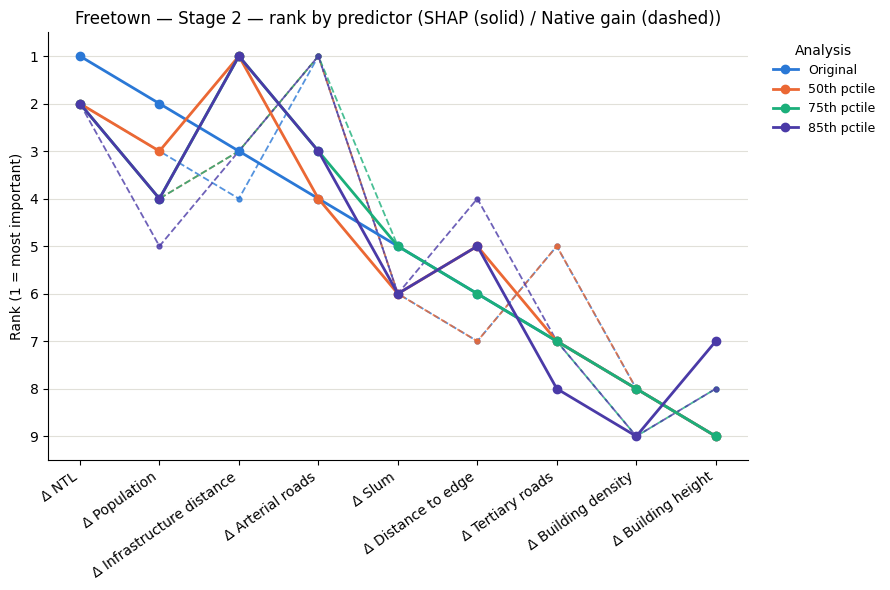

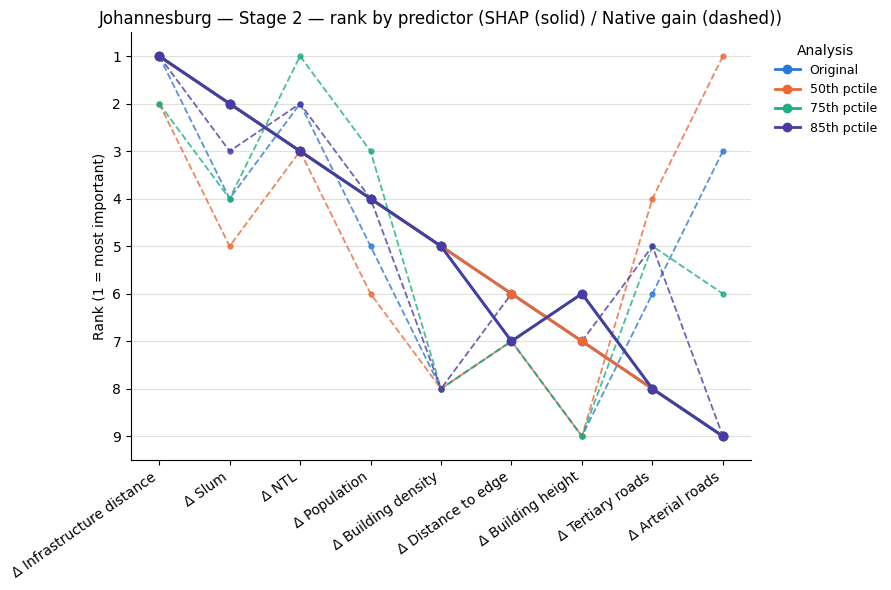

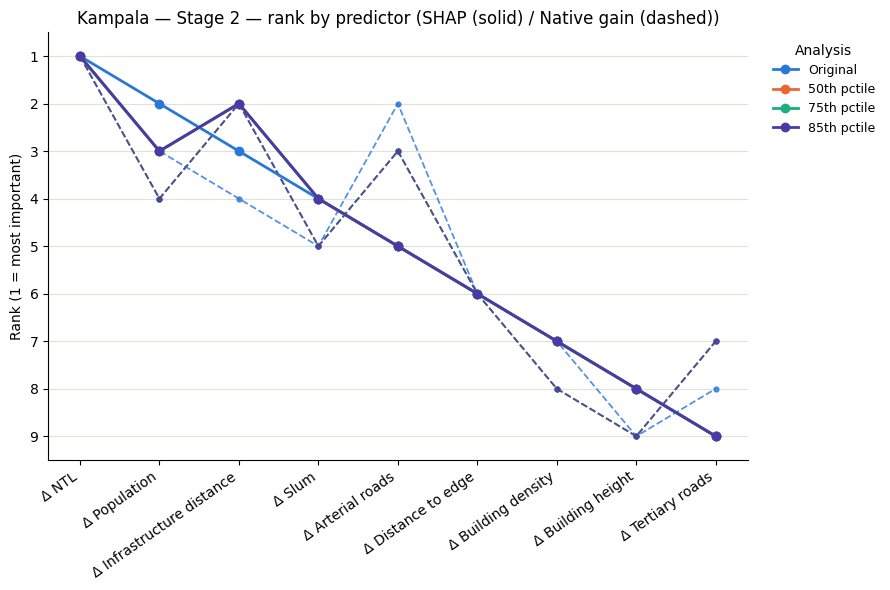

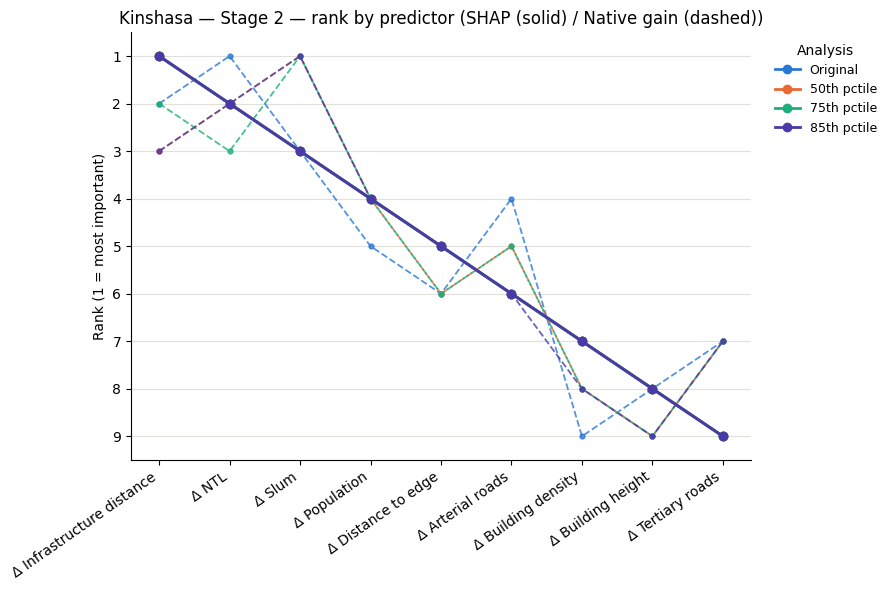

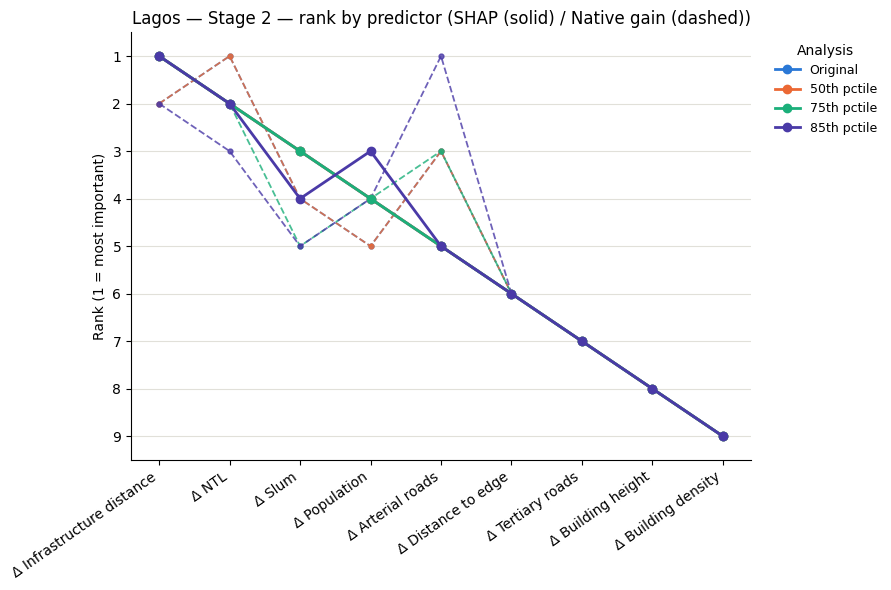

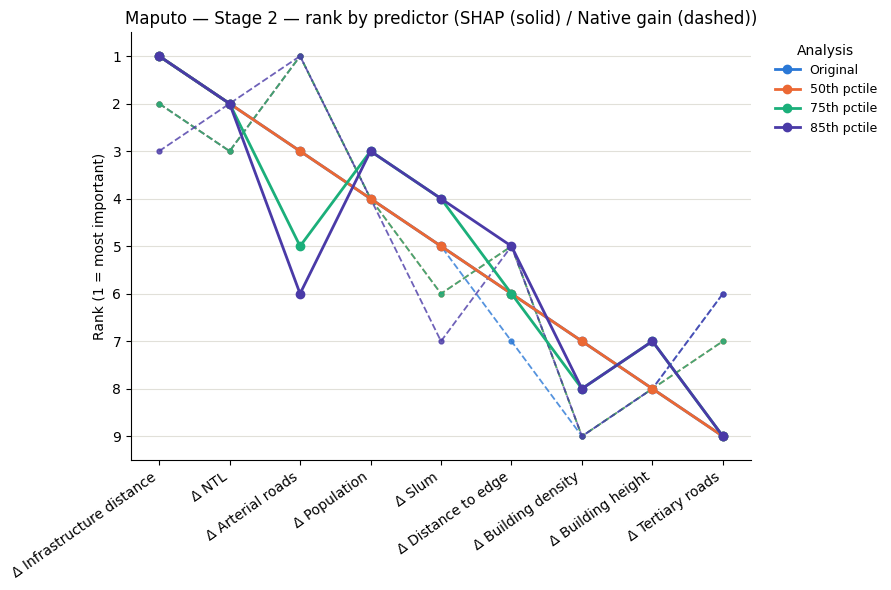

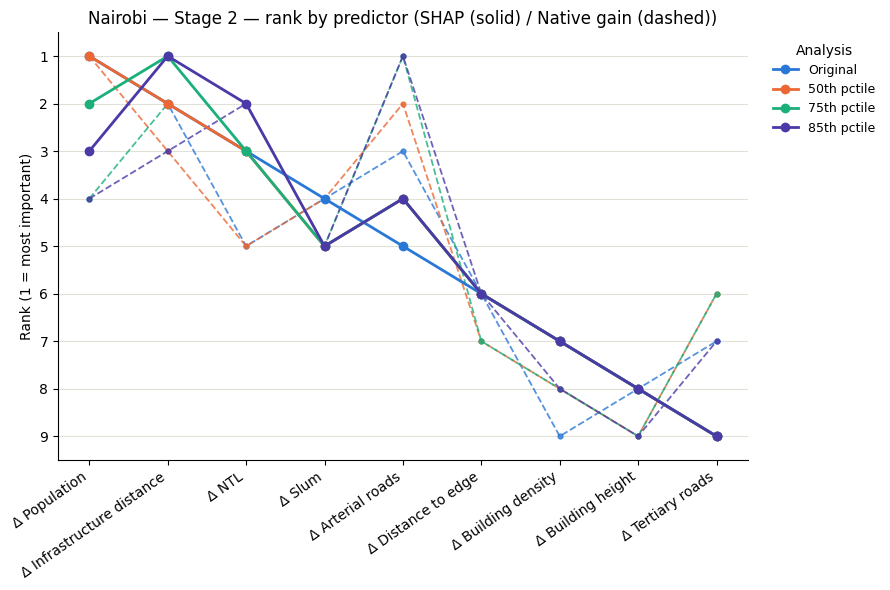


STAGE 2 — average SHAP rank per city (mean across Original/50/75/85th)
city                       Abidjan  Accra  Dakar  Freetown  Johannesburg  Kampala  Kinshasa  Lagos  Maputo  Nairobi  avg    sd
predictor                                                                                                                     
Δ Infrastructure distance      1.0    2.0    3.0       1.5           1.0      2.2       1.0    1.0     1.0      1.5  1.5  0.69
Δ NTL                          2.0    1.0    3.2       1.8           3.0      1.0       2.0    2.0     2.0      2.8  2.1  0.75
Δ Population                   3.0    3.0    1.0       3.2           4.0      2.8       4.0    3.8     3.5      1.8  3.0  0.97
Δ Slum                         4.5    4.0    4.8       5.5           2.0      4.0       3.0    3.2     4.5      4.8  4.0  1.04
Δ Arterial roads               4.5    5.0    3.0       3.5           9.0      5.0       6.0    5.0     4.2      4.2  4.9  1.66
Δ Distance to edge             6.0    6

In [ ]:
"""
Rank stability chart: tracks each predictor's SHAP rank and native-gain rank
across the 4 analyses (Original, 50th pctile, 75th pctile, 85th pctile) for
a given city + stage.

Run in Colab after mounting Drive. Figures are NOT saved to Drive by default
(save_path=None) — they only display inline.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

LABELS = ["Original", "50th pctile", "75th pctile", "85th pctile"]

# Cove categorical palette (fixed order) + gray fallback for the 9th series
PALETTE = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
    "#008300", "#4a3aa7", "#e34948", "#767671",
]

# Colors for the 4 analysis types (used in the by-predictor orientation)
ANALYSIS_COLORS = {
    "Original": "#2a78d6",
    "50th pctile": "#eb6834",
    "75th pctile": "#1baf7a",
    "85th pctile": "#4a3aa7",
}

# =====================================================================
# Stage config: predictors, file naming, and display labels differ by stage.
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_sensitivity_results.csv",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_sensitivity_results.csv",
    },
    # Stage 3/4 (Growth/Decline) can be added here once file naming is confirmed.
}


def load_ranks(city, stage):
    """Returns dict: predictor -> {'shap': [4 ranks], 'native': [4 ranks]}"""
    cfg = STAGE_CONFIG[stage]
    c = city.lower()

    orig = pd.read_csv(cfg["orig_path"](city, c)).iloc[0]
    sens = pd.read_csv(cfg["sens_path"](city, c)).set_index("percentile")

    ranks = {}
    for p in cfg["predictors"]:
        shap_seq = [
            orig[f"{p}_shap_rank"],
            sens.loc[50, f"{p}_shap_rank"],
            sens.loc[75, f"{p}_shap_rank"],
            sens.loc[85, f"{p}_shap_rank"],
        ]
        native_seq = [
            orig[f"{p}_native_rank"],
            sens.loc[50, f"{p}_native_rank"],
            sens.loc[75, f"{p}_native_rank"],
            sens.loc[85, f"{p}_native_rank"],
        ]
        ranks[p] = {"shap": shap_seq, "native": native_seq}
    return ranks


def plot_rank_stability(city, stage, save_path=None):
    """Predictors as separate lines, x-axis = the 4 analyses."""
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    fig, ax = plt.subplots(figsize=(9, 6.5))
    x = range(len(LABELS))

    for i, p in enumerate(predictors):
        color = PALETTE[i % len(PALETTE)]
        ax.plot(x, ranks[p]["shap"], color=color, linewidth=2,
                marker="o", markersize=6, label=label_map[p], zorder=3)
        ax.plot(x, ranks[p]["native"], color=color, linewidth=1.3,
                linestyle="--", marker="o", markersize=3.5, alpha=0.85, zorder=2)

    ax.set_xticks(list(x))
    ax.set_xticklabels(LABELS)
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 SHAP vs native rank stability")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

    predictor_handles = [mlines.Line2D([], [], color=PALETTE[i % len(PALETTE)],
                                        linewidth=2, label=label_map[p])
                          for i, p in enumerate(predictors)]
    style_handles = [
        mlines.Line2D([], [], color="black", linewidth=2, label="SHAP rank"),
        mlines.Line2D([], [], color="black", linewidth=1.3, linestyle="--", label="Native gain rank"),
    ]

    leg1 = ax.legend(handles=predictor_handles, bbox_to_anchor=(1.02, 1), loc="upper left",
                      fontsize=9, title="Predictor", frameon=False)
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, bbox_to_anchor=(1.02, 0.25), loc="upper left",
               fontsize=9, frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def plot_rank_stability_by_predictor(city, stage, order_by="Original", metric="both", save_path=None):
    """
    Alternate orientation: x-axis = predictors, y-axis = rank, one line per
    analysis (Original/50th/75th/85th). Predictors are ordered along the
    x-axis by their SHAP rank in `order_by` (default: Original).

    metric: "shap", "native", or "both" (both = solid SHAP + dashed native,
    same color per analysis).
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    ref_idx = LABELS.index(order_by)
    ordered_predictors = sorted(predictors, key=lambda p: ranks[p]["shap"][ref_idx])
    ordered_display = [label_map[p] for p in ordered_predictors]

    fig, ax = plt.subplots(figsize=(9, 6))
    x = range(n)

    for li, label in enumerate(LABELS):
        color = ANALYSIS_COLORS[label]
        if metric in ("shap", "both"):
            y_shap = [ranks[p]["shap"][li] for p in ordered_predictors]
            ax.plot(x, y_shap, color=color, linewidth=2, marker="o",
                     markersize=6, label=label, zorder=3)
        if metric in ("native", "both"):
            y_native = [ranks[p]["native"][li] for p in ordered_predictors]
            ax.plot(x, y_native, color=color, linewidth=1.3, linestyle="--",
                     marker="o", markersize=3.5, alpha=0.8, zorder=2,
                     label=None if metric == "both" else label)

    ax.set_xticks(list(x))
    ax.set_xticklabels(ordered_display, rotation=35, ha="right")
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    metric_label = {"shap": "SHAP", "native": "Native gain", "both": "SHAP (solid) / Native gain (dashed)"}[metric]
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 rank by predictor ({metric_label})")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9,
              title="Analysis", frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def summary_table_all_cities(cities, stage):
    """
    Pretty-print summary: for each city, each predictor's average SHAP rank
    (mean across Original/50th/75th/85th), plus an overall average rank and
    SD across cities. Lower rank = more important.
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]

    all_rows = []
    for city in cities:
        ranks = load_ranks(city, stage)
        for p in predictors:
            seq = ranks[p]["shap"]
            all_rows.append({"city": city, "predictor": label_map[p], "avg_rank": sum(seq) / len(seq)})
    df = pd.DataFrame(all_rows)

    pivot = df.pivot(index="predictor", columns="city", values="avg_rank").round(1)
    pivot["avg"] = pivot[cities].mean(axis=1).round(1)
    pivot["sd"] = pivot[cities].std(axis=1).round(2)
    pivot = pivot.sort_values("avg")

    print("\n" + "=" * 70)
    print(f"STAGE {stage} \u2014 average SHAP rank per city (mean across Original/50/75/85th)")
    print("=" * 70)
    print(pivot.to_string())
    print("\nLower = more important. 'sd' = spread of each predictor's avg rank across cities.")

    return df, pivot


def validate_stage_files(cities, stage):
    """
    Quick structural check before running the full analysis: confirms each
    city's original + sensitivity CSVs exist, have the expected predictor
    rank/importance columns, and that the sensitivity file has all 3
    percentile rows. Prints a pass/fail summary; does not plot anything.
    """
    cfg = STAGE_CONFIG[stage]
    predictors = cfg["predictors"]
    expected_cols = set()
    for p in predictors:
        expected_cols.update([f"{p}_native_gain", f"{p}_native_rank",
                               f"{p}_shap_importance", f"{p}_shap_rank"])

    problems = []
    for city in cities:
        c = city.lower()

        orig_path = cfg["orig_path"](city, c)
        sens_path = cfg["sens_path"](city, c)

        try:
            orig = pd.read_csv(orig_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING original file -> {orig_path}")
            continue

        try:
            sens = pd.read_csv(sens_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING sensitivity file -> {sens_path}")
            continue

        missing_orig = expected_cols - set(orig.columns)
        if missing_orig:
            problems.append(f"{city}: original file missing columns: {sorted(missing_orig)}")

        missing_sens = expected_cols - set(sens.columns)
        if missing_sens:
            problems.append(f"{city}: sensitivity file missing columns: {sorted(missing_sens)}")

        if "percentile" not in sens.columns:
            problems.append(f"{city}: sensitivity file missing 'percentile' column")
        else:
            found_pcts = set(sens["percentile"].tolist())
            if found_pcts != {50, 75, 85}:
                problems.append(f"{city}: sensitivity file has percentiles {sorted(found_pcts)}, expected [50, 75, 85]")

        if len(orig) != 1:
            problems.append(f"{city}: original file has {len(orig)} rows, expected 1")

    print("=" * 70)
    print(f"STAGE {stage} FILE VALIDATION — {len(cities)} cities checked")
    print("=" * 70)
    if not problems:
        print("All clear — every city has both files with the expected structure.")
    else:
        for p in problems:
            print(f"  \u2717 {p}")
        print(f"\n{len(problems)} issue(s) found across {len(cities)} cities.")
    return problems


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    stage = 2  # Persistence
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    validate_stage_files(cities, stage)  # run this first

    for city in cities:
        plot_rank_stability_by_predictor(city, stage)  # save_path=None -> not written to Drive

    long_df, summary_pivot = summary_table_all_cities(cities, stage)

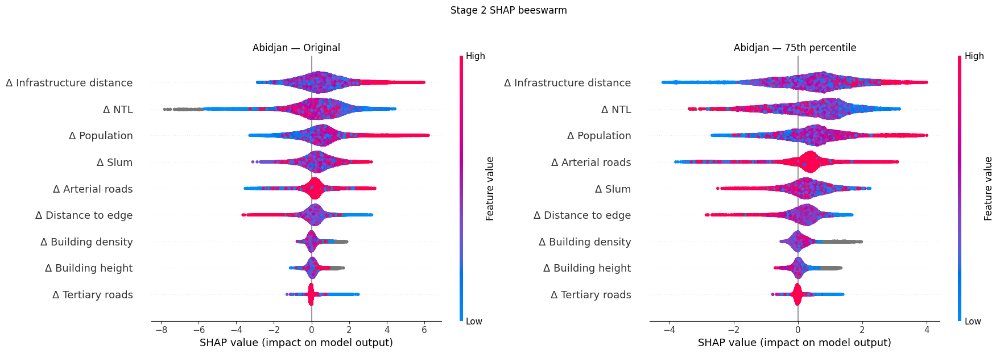

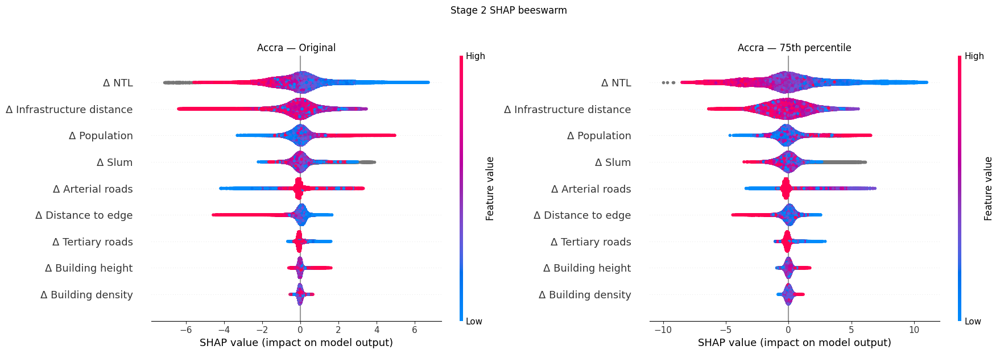

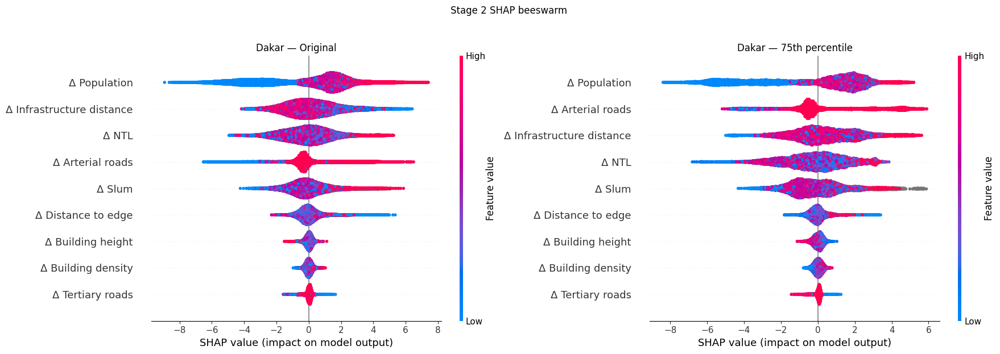

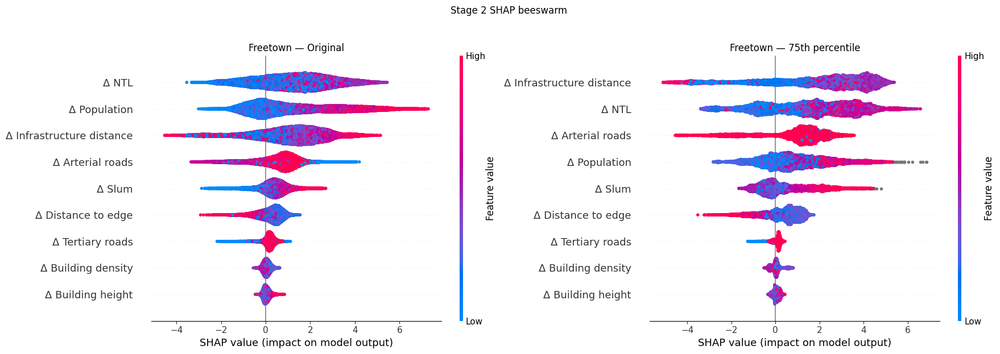

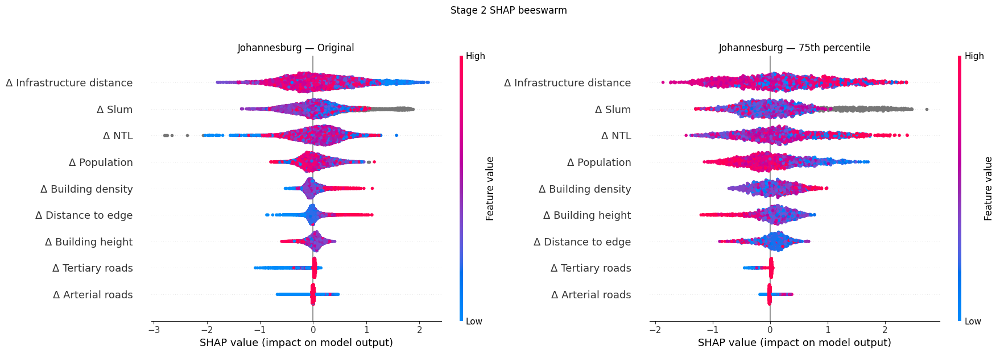

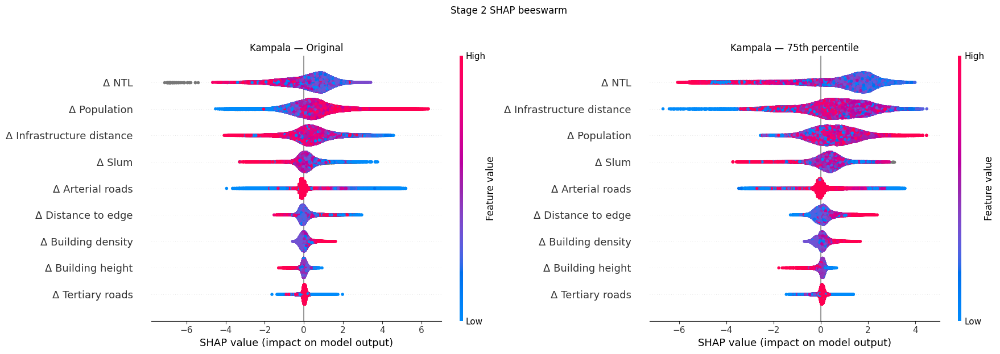

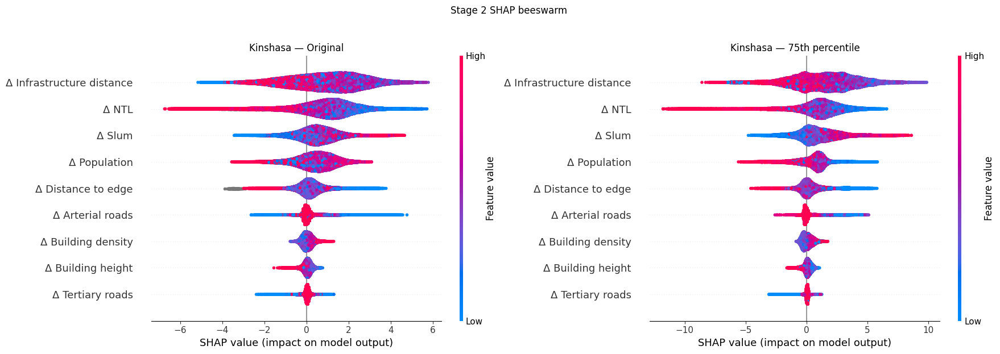

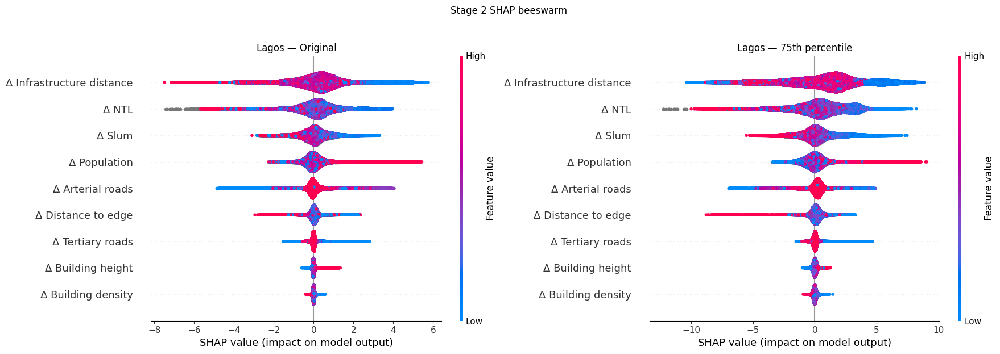

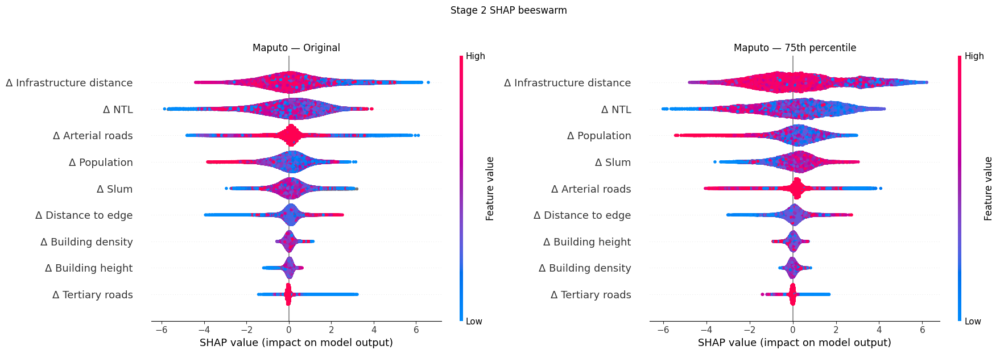

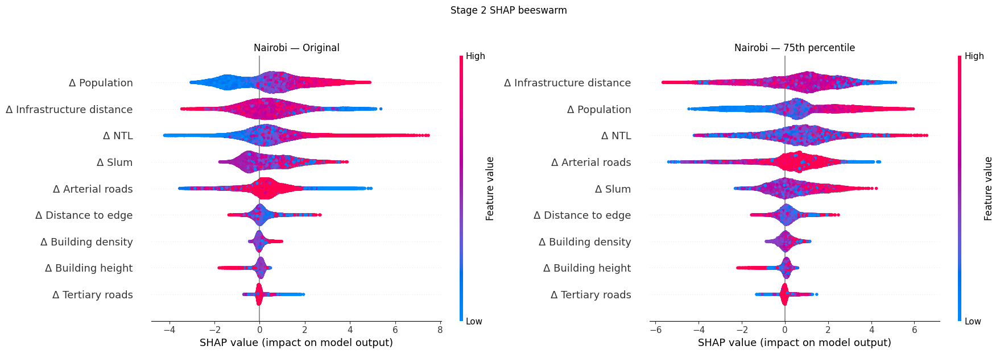

In [ ]:
"""
SHAP beeswarm plots, two columns per city: Original vs {percentile}th percentile.
Run in Colab after mounting Drive. Not saved to Drive — displays inline only.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

# =====================================================================
# Stage 1 — Stable-absent
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}


def build_stage1_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 1 SHAP values were computed
    (stacked 2016+2024 rows, filtered by DV percentile if given).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in STAGE1_PREDICTORS}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        return sub

    stacked = pd.concat(
        [build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")],
        ignore_index=True,
    )
    stacked["target"] = (stacked["DV"] > 0).astype(int)

    if percentile is None:
        return stacked[STAGE1_PREDICTORS]

    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = present_pool.quantile(percentile / 100)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[STAGE1_PREDICTORS]


# =====================================================================
# Stage 2 — Persistence
# =====================================================================

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}


def build_stage2_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 2 (Persistence) SHAP values were
    computed: Persistent (DV2016>0 & DV2024>0) + Cleared (DV2016>0 & DV2024=0),
    filtered by their respective DV percentile if given, concatenated
    Persistent-then-Cleared (matches build_stage2_data in your script).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    persist_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0)].copy()
    persist_all["Avg_DV"] = (persist_all["DV_2016"] + persist_all["DV_2024"]) / 2
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()

    if percentile is None:
        persist_f, clear_f = persist_all, clear_all
    else:
        p_cut = persist_all["Avg_DV"].quantile(percentile / 100)
        c_cut = clear_all["DV_2016"].quantile(percentile / 100)
        persist_f = persist_all[persist_all["Avg_DV"] >= p_cut]
        clear_f = clear_all[clear_all["DV_2016"] >= c_cut]

    persist_f = persist_f.copy(); persist_f["target"] = 1
    clear_f = clear_f.copy(); clear_f["target"] = 0
    data = pd.concat([persist_f, clear_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]


# =====================================================================
# Stage config: predictors, X-builder, .npy paths, and display labels.
# NOTE: Stage 2's ORIGINAL (non-percentile) .npy path below is inferred by
# analogy to Stage 1's naming (not yet confirmed against your original
# Stage 2 script) — double-check the filename on Drive before trusting it.
# =====================================================================

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "build_X": build_stage1_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_shap_values.npy",
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_shap_values_pct{pct}.npy",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "build_X": build_stage2_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_shap_values.npy",  # unconfirmed
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_shap_values_pct{pct}.npy",
    },
}


def plot_shap_beeswarm_grid(cities, stage=1, percentile=75, max_display=9):
    """Two-column SHAP beeswarm figure per city: Original (left) vs {percentile}th (right)."""
    cfg = STAGE_CONFIG[stage]
    feature_labels = [cfg["labels"][p] for p in cfg["predictors"]]

    for city in cities:
        c = city.lower()

        shap_orig = np.load(cfg["orig_shap_path"](city, c))
        X_orig = cfg["build_X"](city, percentile=None)

        shap_pct = np.load(cfg["sens_shap_path"](city, c, percentile))
        X_pct = cfg["build_X"](city, percentile=percentile)

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))

        plt.sca(axes[0])
        # plot_size=None stops shap from resizing the whole figure on each call
        shap.summary_plot(shap_orig, X_orig, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[0].set_title(f"{city} \u2014 Original")

        plt.sca(axes[1])
        shap.summary_plot(shap_pct, X_pct, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[1].set_title(f"{city} \u2014 {percentile}th percentile")

        fig.suptitle(f"Stage {stage} SHAP beeswarm", y=1.03)
        plt.tight_layout()
        plt.show()  # not saved to Drive


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    plot_shap_beeswarm_grid(cities, stage=2, percentile=75)

Growth model analysis

STAGE 3 FILE VALIDATION — 10 cities checked
All clear — every city has both files with the expected structure.


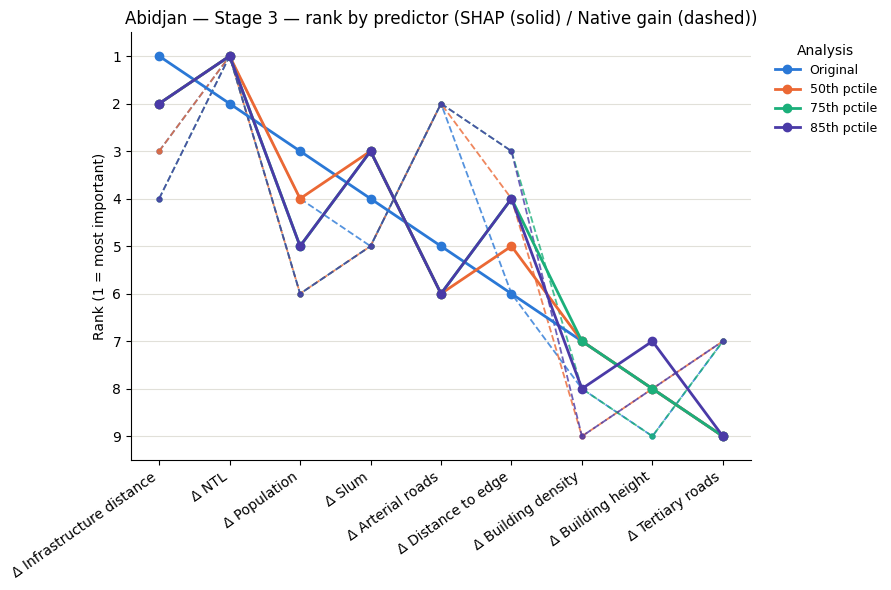

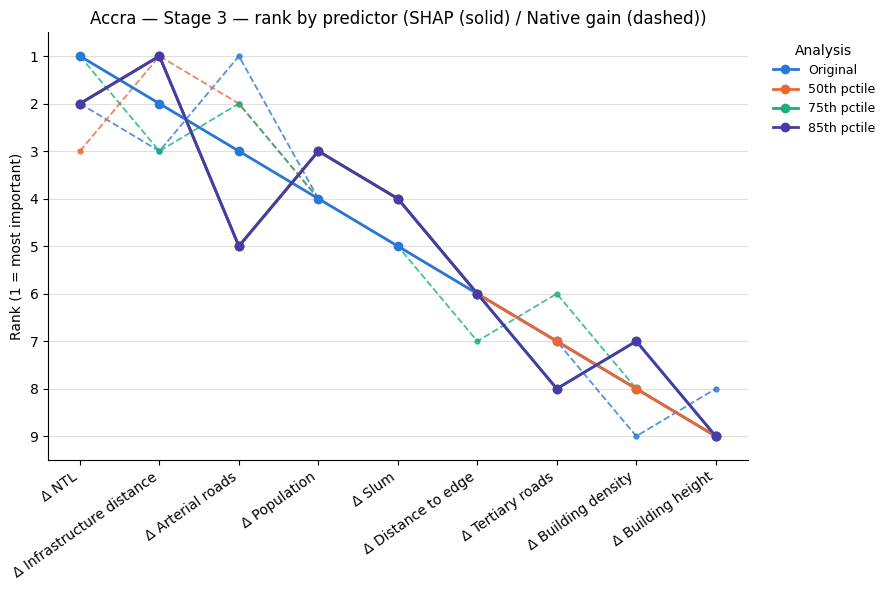

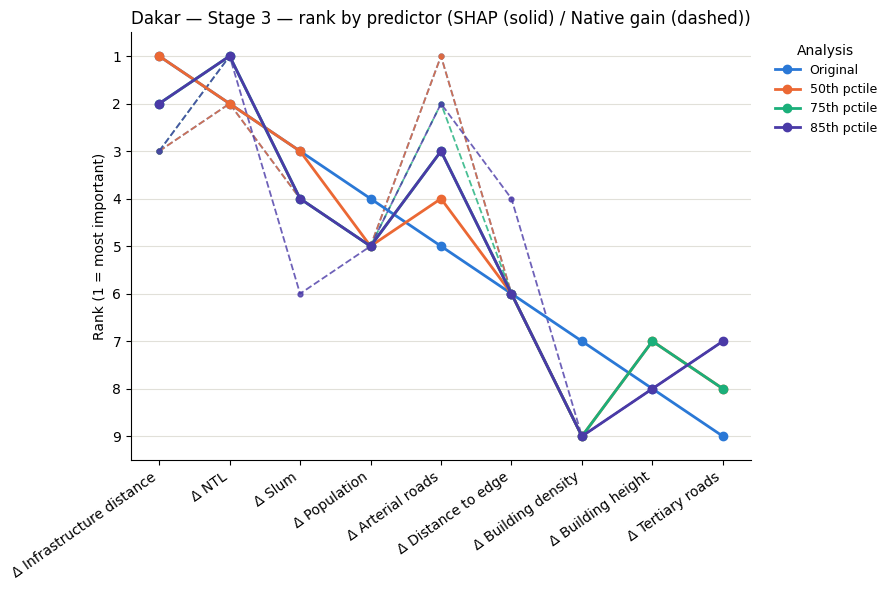

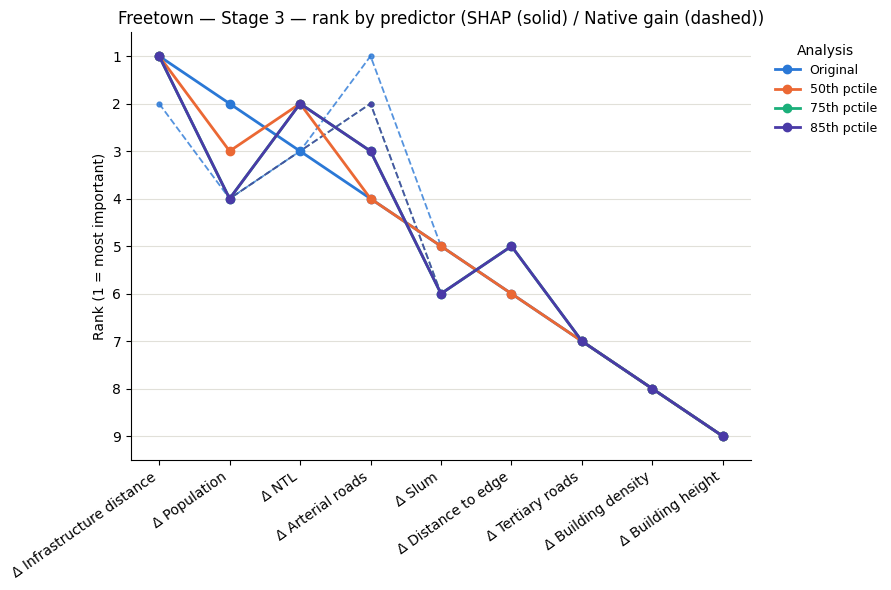

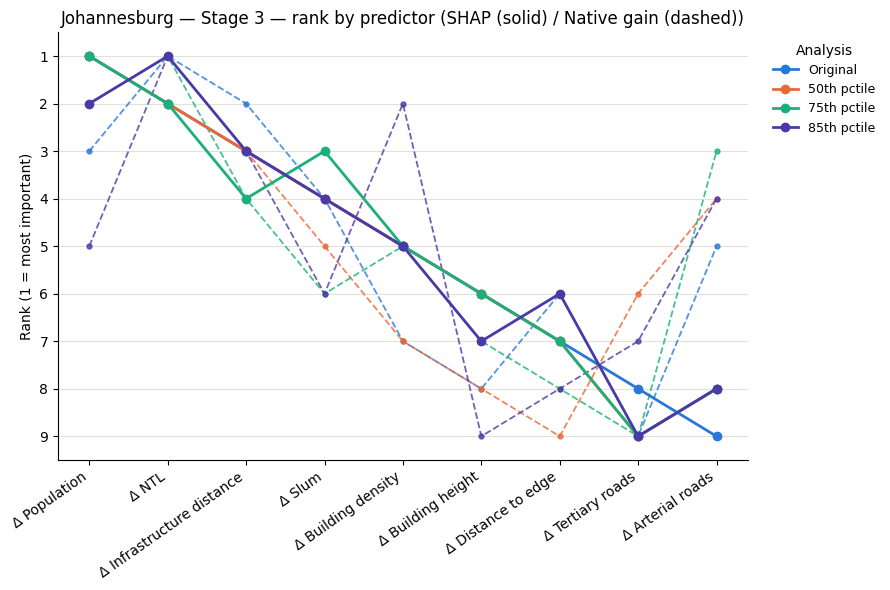

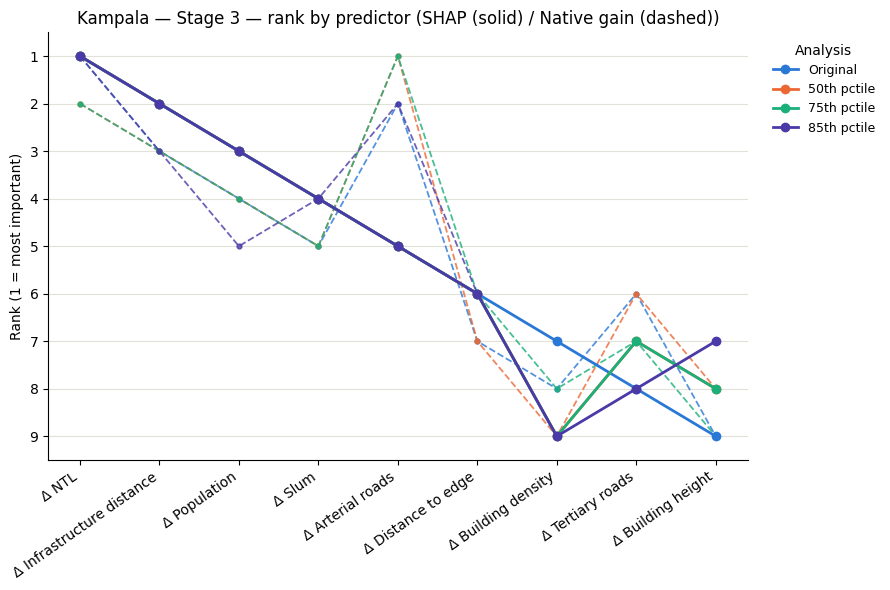

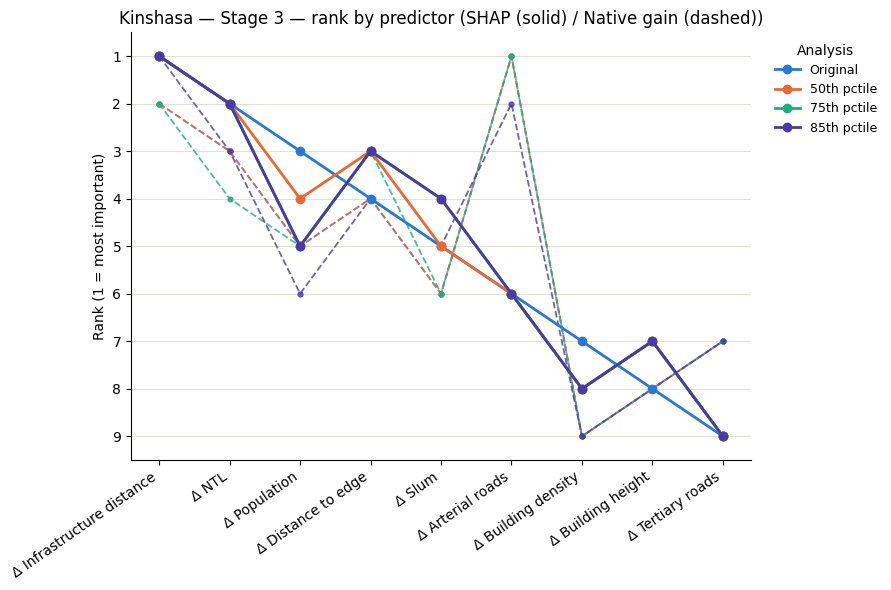

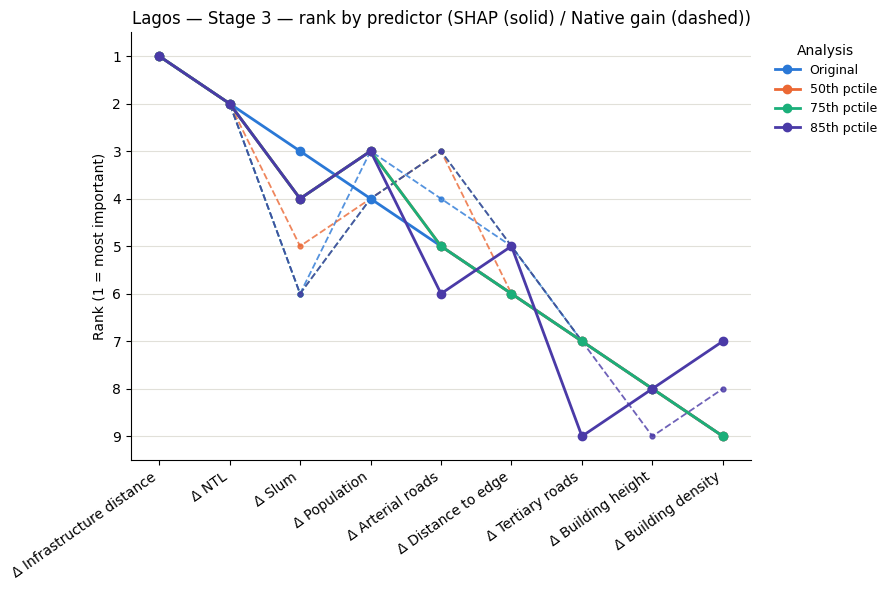

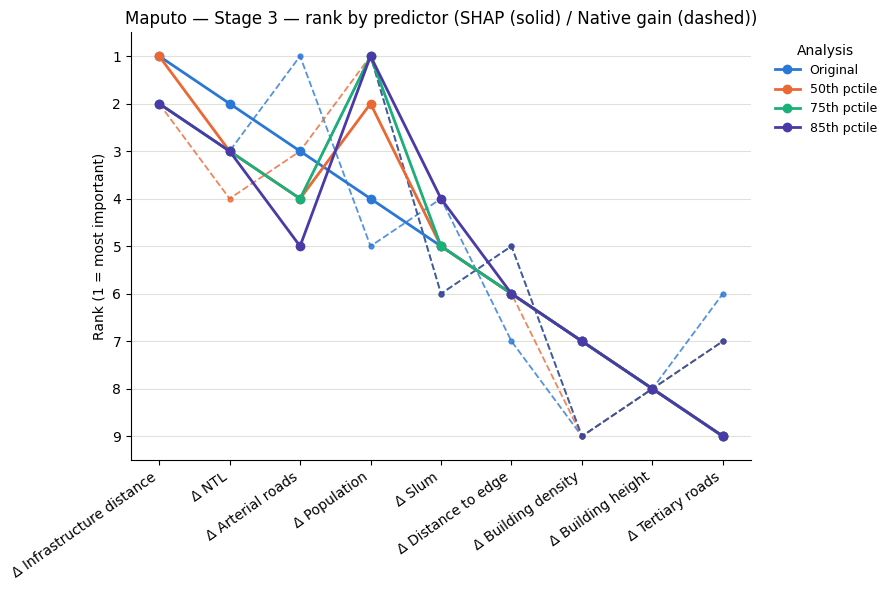

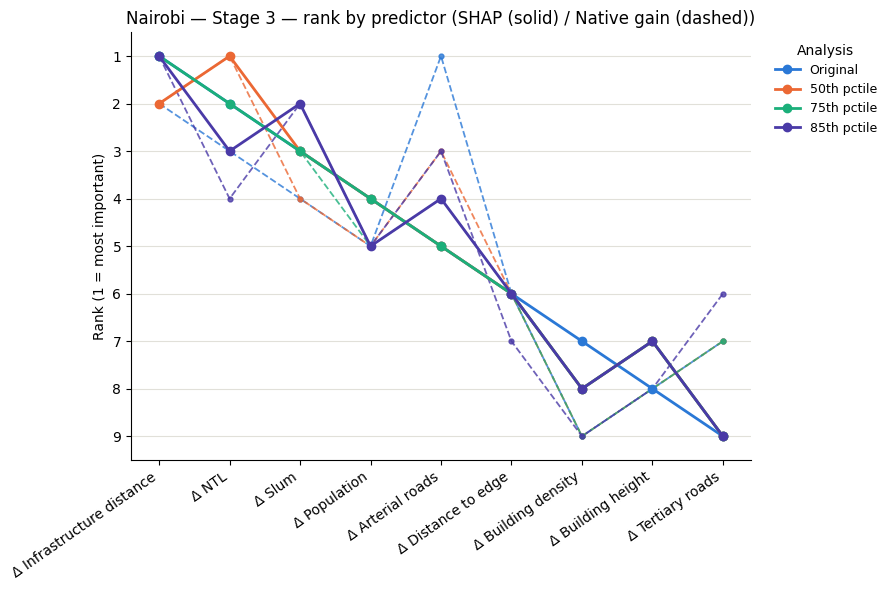


STAGE 3 — average SHAP rank per city (mean across Original/50/75/85th)
city                       Abidjan  Accra  Dakar  Freetown  Johannesburg  Kampala  Kinshasa  Lagos  Maputo  Nairobi  avg    sd
predictor                                                                                                                     
Δ Infrastructure distance      1.8    1.2    1.5       1.0           3.2      2.0       1.0    1.0     1.5      1.2  1.5  0.68
Δ NTL                          1.2    1.8    1.5       2.2           1.8      1.0       2.0    2.0     2.8      2.0  1.8  0.51
Δ Population                   4.2    3.2    4.8       3.2           1.2      3.0       4.2    3.2     2.0      4.2  3.3  1.10
Δ Slum                         3.2    4.2    3.5       5.5           3.8      4.0       4.5    3.8     4.8      2.8  4.0  0.79
Δ Arterial roads               5.8    4.5    3.8       3.5           8.2      5.0       6.0    5.2     4.0      4.8  5.1  1.37
Δ Distance to edge             4.8    6

In [ ]:
"""
Rank stability chart: tracks each predictor's SHAP rank and native-gain rank
across the 4 analyses (Original, 50th pctile, 75th pctile, 85th pctile) for
a given city + stage.

Run in Colab after mounting Drive. Figures are NOT saved to Drive by default
(save_path=None) — they only display inline.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

LABELS = ["Original", "50th pctile", "75th pctile", "85th pctile"]

# Cove categorical palette (fixed order) + gray fallback for the 9th series
PALETTE = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
    "#008300", "#4a3aa7", "#e34948", "#767671",
]

# Colors for the 4 analysis types (used in the by-predictor orientation)
ANALYSIS_COLORS = {
    "Original": "#2a78d6",
    "50th pctile": "#eb6834",
    "75th pctile": "#1baf7a",
    "85th pctile": "#4a3aa7",
}

# =====================================================================
# Stage config: predictors, file naming, and display labels differ by stage.
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_sensitivity_results.csv",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_sensitivity_results.csv",
    },
    3: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set as Stage 2
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage3_growth_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage3_growth_sensitivity_results.csv",
    },
    # Stage 4 (Decline) can be added here once file naming is confirmed.
}


def load_ranks(city, stage):
    """Returns dict: predictor -> {'shap': [4 ranks], 'native': [4 ranks]}"""
    cfg = STAGE_CONFIG[stage]
    c = city.lower()

    orig = pd.read_csv(cfg["orig_path"](city, c)).iloc[0]
    sens = pd.read_csv(cfg["sens_path"](city, c)).set_index("percentile")

    ranks = {}
    for p in cfg["predictors"]:
        shap_seq = [
            orig[f"{p}_shap_rank"],
            sens.loc[50, f"{p}_shap_rank"],
            sens.loc[75, f"{p}_shap_rank"],
            sens.loc[85, f"{p}_shap_rank"],
        ]
        native_seq = [
            orig[f"{p}_native_rank"],
            sens.loc[50, f"{p}_native_rank"],
            sens.loc[75, f"{p}_native_rank"],
            sens.loc[85, f"{p}_native_rank"],
        ]
        ranks[p] = {"shap": shap_seq, "native": native_seq}
    return ranks


def plot_rank_stability(city, stage, save_path=None):
    """Predictors as separate lines, x-axis = the 4 analyses."""
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    fig, ax = plt.subplots(figsize=(9, 6.5))
    x = range(len(LABELS))

    for i, p in enumerate(predictors):
        color = PALETTE[i % len(PALETTE)]
        ax.plot(x, ranks[p]["shap"], color=color, linewidth=2,
                marker="o", markersize=6, label=label_map[p], zorder=3)
        ax.plot(x, ranks[p]["native"], color=color, linewidth=1.3,
                linestyle="--", marker="o", markersize=3.5, alpha=0.85, zorder=2)

    ax.set_xticks(list(x))
    ax.set_xticklabels(LABELS)
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 SHAP vs native rank stability")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

    predictor_handles = [mlines.Line2D([], [], color=PALETTE[i % len(PALETTE)],
                                        linewidth=2, label=label_map[p])
                          for i, p in enumerate(predictors)]
    style_handles = [
        mlines.Line2D([], [], color="black", linewidth=2, label="SHAP rank"),
        mlines.Line2D([], [], color="black", linewidth=1.3, linestyle="--", label="Native gain rank"),
    ]

    leg1 = ax.legend(handles=predictor_handles, bbox_to_anchor=(1.02, 1), loc="upper left",
                      fontsize=9, title="Predictor", frameon=False)
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, bbox_to_anchor=(1.02, 0.25), loc="upper left",
               fontsize=9, frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def plot_rank_stability_by_predictor(city, stage, order_by="Original", metric="both", save_path=None):
    """
    Alternate orientation: x-axis = predictors, y-axis = rank, one line per
    analysis (Original/50th/75th/85th). Predictors are ordered along the
    x-axis by their SHAP rank in `order_by` (default: Original).

    metric: "shap", "native", or "both" (both = solid SHAP + dashed native,
    same color per analysis).
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    ref_idx = LABELS.index(order_by)
    ordered_predictors = sorted(predictors, key=lambda p: ranks[p]["shap"][ref_idx])
    ordered_display = [label_map[p] for p in ordered_predictors]

    fig, ax = plt.subplots(figsize=(9, 6))
    x = range(n)

    for li, label in enumerate(LABELS):
        color = ANALYSIS_COLORS[label]
        if metric in ("shap", "both"):
            y_shap = [ranks[p]["shap"][li] for p in ordered_predictors]
            ax.plot(x, y_shap, color=color, linewidth=2, marker="o",
                     markersize=6, label=label, zorder=3)
        if metric in ("native", "both"):
            y_native = [ranks[p]["native"][li] for p in ordered_predictors]
            ax.plot(x, y_native, color=color, linewidth=1.3, linestyle="--",
                     marker="o", markersize=3.5, alpha=0.8, zorder=2,
                     label=None if metric == "both" else label)

    ax.set_xticks(list(x))
    ax.set_xticklabels(ordered_display, rotation=35, ha="right")
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    metric_label = {"shap": "SHAP", "native": "Native gain", "both": "SHAP (solid) / Native gain (dashed)"}[metric]
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 rank by predictor ({metric_label})")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9,
              title="Analysis", frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def summary_table_all_cities(cities, stage):
    """
    Pretty-print summary: for each city, each predictor's average SHAP rank
    (mean across Original/50th/75th/85th), plus an overall average rank and
    SD across cities. Lower rank = more important.
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]

    all_rows = []
    for city in cities:
        ranks = load_ranks(city, stage)
        for p in predictors:
            seq = ranks[p]["shap"]
            all_rows.append({"city": city, "predictor": label_map[p], "avg_rank": sum(seq) / len(seq)})
    df = pd.DataFrame(all_rows)

    pivot = df.pivot(index="predictor", columns="city", values="avg_rank").round(1)
    pivot["avg"] = pivot[cities].mean(axis=1).round(1)
    pivot["sd"] = pivot[cities].std(axis=1).round(2)
    pivot = pivot.sort_values("avg")

    print("\n" + "=" * 70)
    print(f"STAGE {stage} \u2014 average SHAP rank per city (mean across Original/50/75/85th)")
    print("=" * 70)
    print(pivot.to_string())
    print("\nLower = more important. 'sd' = spread of each predictor's avg rank across cities.")

    return df, pivot


def validate_stage_files(cities, stage):
    """
    Quick structural check before running the full analysis: confirms each
    city's original + sensitivity CSVs exist, have the expected predictor
    rank/importance columns, and that the sensitivity file has all 3
    percentile rows. Prints a pass/fail summary; does not plot anything.
    """
    cfg = STAGE_CONFIG[stage]
    predictors = cfg["predictors"]
    expected_cols = set()
    for p in predictors:
        expected_cols.update([f"{p}_native_gain", f"{p}_native_rank",
                               f"{p}_shap_importance", f"{p}_shap_rank"])

    problems = []
    for city in cities:
        c = city.lower()

        orig_path = cfg["orig_path"](city, c)
        sens_path = cfg["sens_path"](city, c)

        try:
            orig = pd.read_csv(orig_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING original file -> {orig_path}")
            continue

        try:
            sens = pd.read_csv(sens_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING sensitivity file -> {sens_path}")
            continue

        missing_orig = expected_cols - set(orig.columns)
        if missing_orig:
            problems.append(f"{city}: original file missing columns: {sorted(missing_orig)}")

        missing_sens = expected_cols - set(sens.columns)
        if missing_sens:
            problems.append(f"{city}: sensitivity file missing columns: {sorted(missing_sens)}")

        if "percentile" not in sens.columns:
            problems.append(f"{city}: sensitivity file missing 'percentile' column")
        else:
            found_pcts = set(sens["percentile"].tolist())
            if found_pcts != {50, 75, 85}:
                problems.append(f"{city}: sensitivity file has percentiles {sorted(found_pcts)}, expected [50, 75, 85]")

        if len(orig) != 1:
            problems.append(f"{city}: original file has {len(orig)} rows, expected 1")

    print("=" * 70)
    print(f"STAGE {stage} FILE VALIDATION — {len(cities)} cities checked")
    print("=" * 70)
    if not problems:
        print("All clear — every city has both files with the expected structure.")
    else:
        for p in problems:
            print(f"  \u2717 {p}")
        print(f"\n{len(problems)} issue(s) found across {len(cities)} cities.")
    return problems


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    stage = 3  # Growth
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    validate_stage_files(cities, stage)  # run this first

    for city in cities:
        plot_rank_stability_by_predictor(city, stage)  # save_path=None -> not written to Drive

    long_df, summary_pivot = summary_table_all_cities(cities, stage)

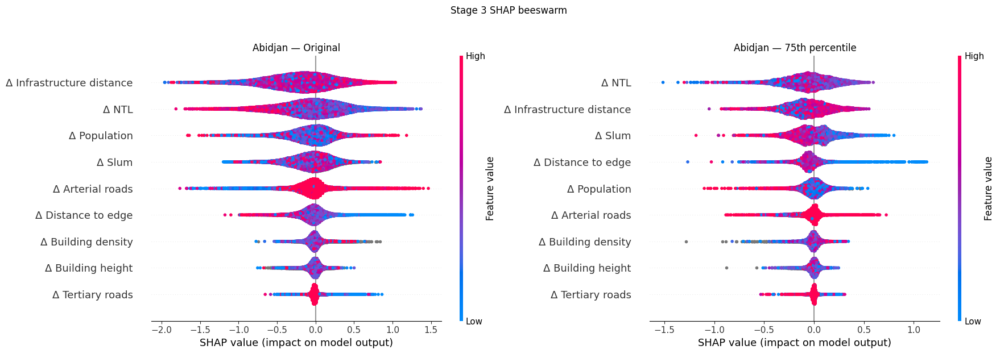

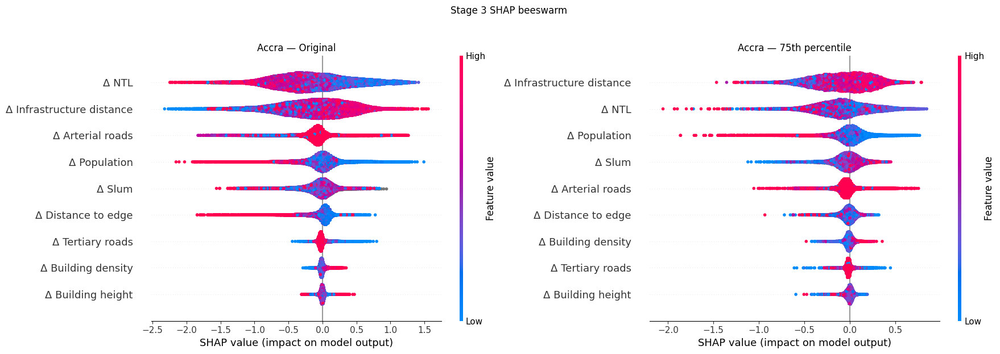

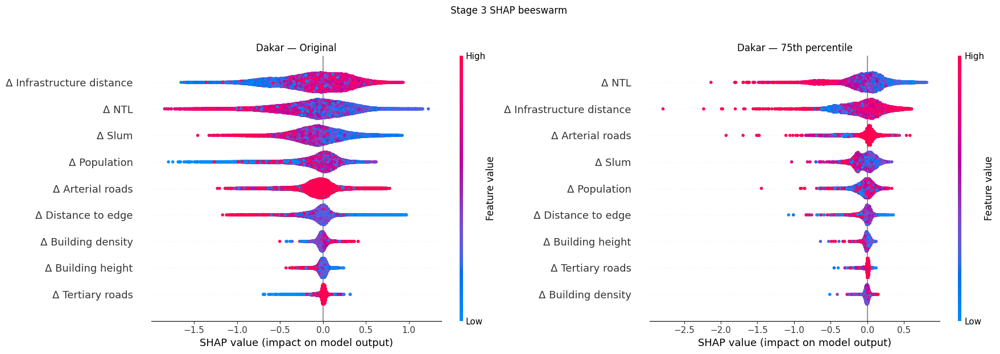

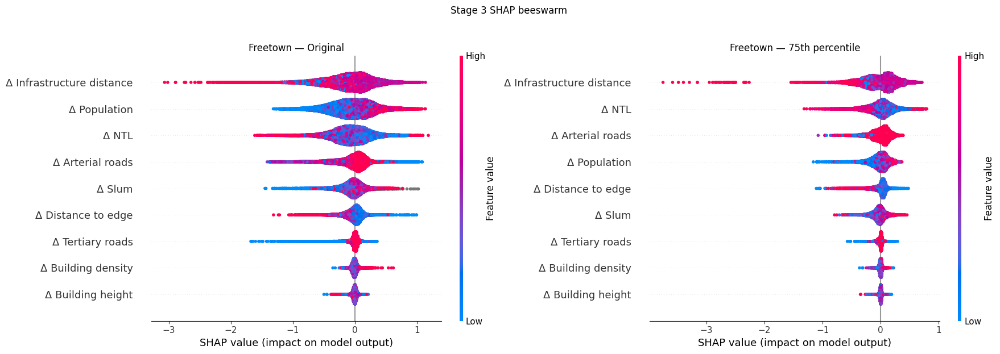

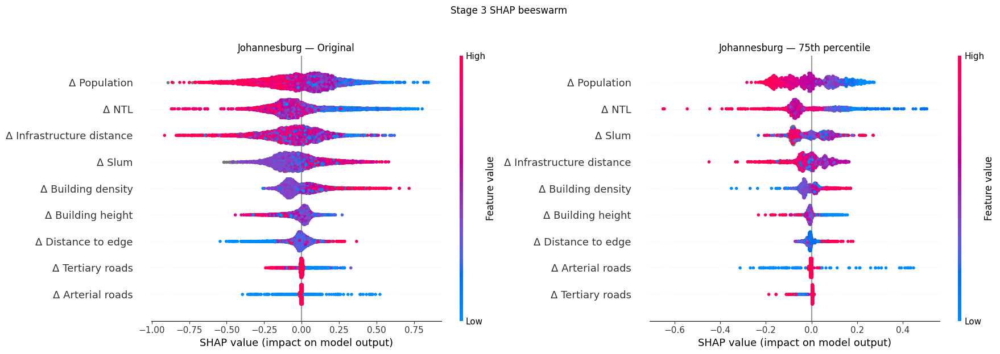

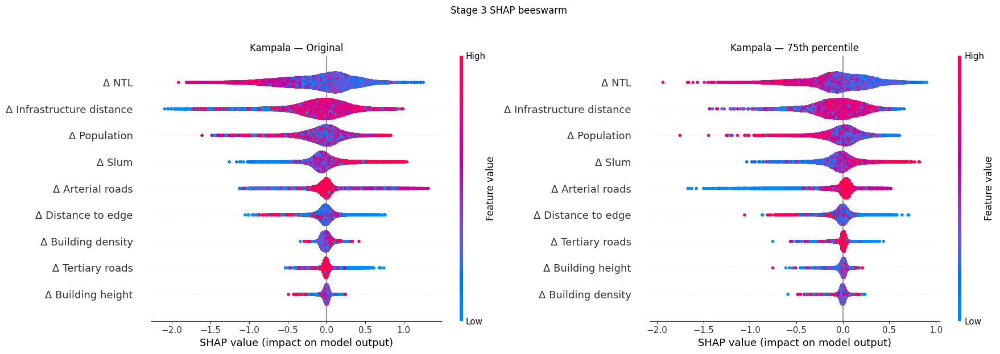

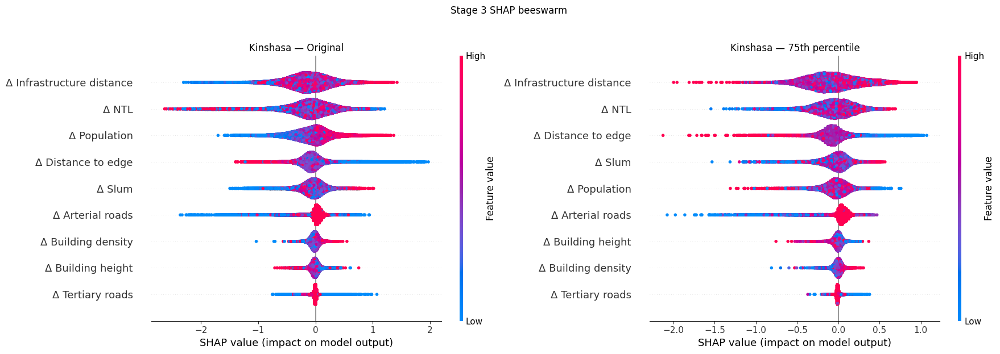

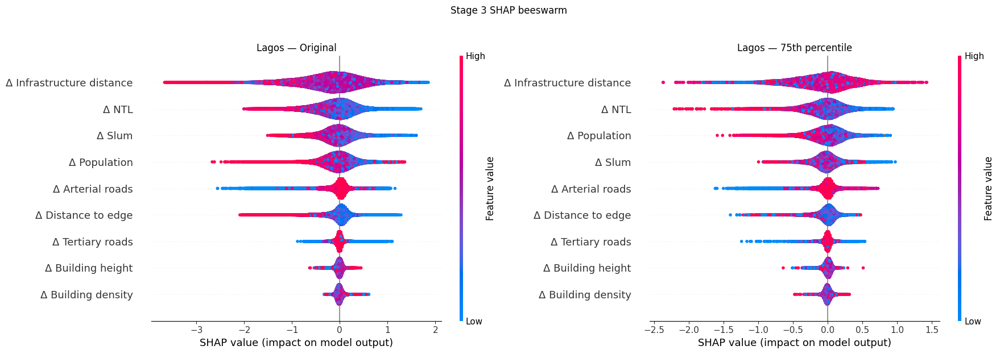

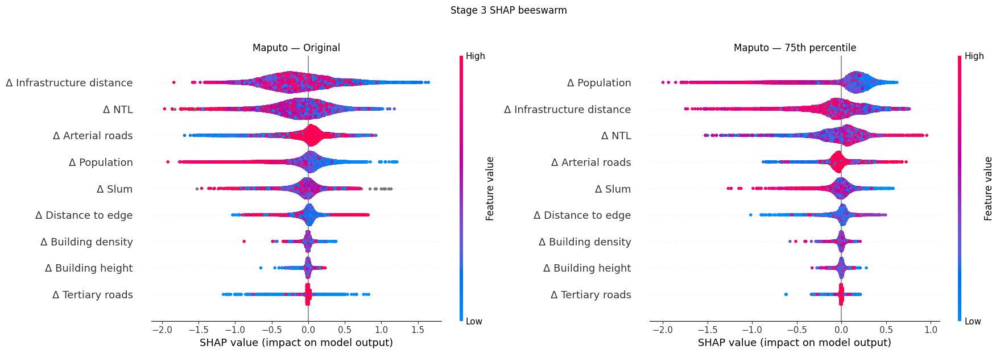

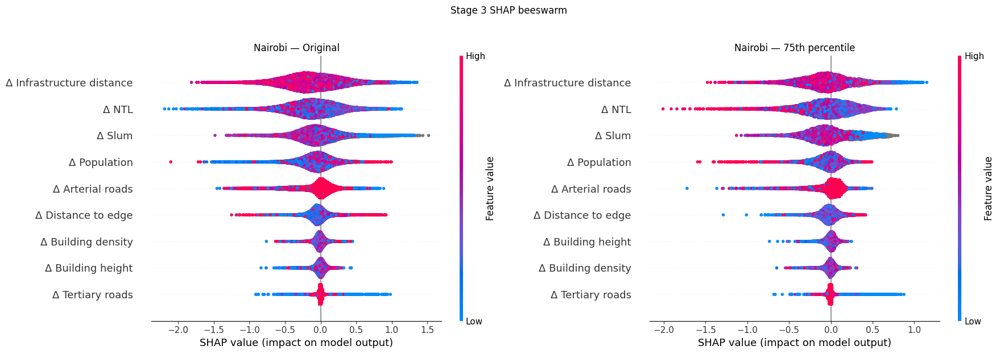

In [ ]:
"""
SHAP beeswarm plots, two columns per city: Original vs {percentile}th percentile.
Run in Colab after mounting Drive. Not saved to Drive — displays inline only.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

# =====================================================================
# Stage 1 — Stable-absent
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}


def build_stage1_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 1 SHAP values were computed
    (stacked 2016+2024 rows, filtered by DV percentile if given).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in STAGE1_PREDICTORS}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        return sub

    stacked = pd.concat(
        [build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")],
        ignore_index=True,
    )
    stacked["target"] = (stacked["DV"] > 0).astype(int)

    if percentile is None:
        return stacked[STAGE1_PREDICTORS]

    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = present_pool.quantile(percentile / 100)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[STAGE1_PREDICTORS]


# =====================================================================
# Stage 2 — Persistence
# =====================================================================

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}


def build_stage2_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 2 (Persistence) SHAP values were
    computed: Persistent (DV2016>0 & DV2024>0) + Cleared (DV2016>0 & DV2024=0),
    filtered by their respective DV percentile if given, concatenated
    Persistent-then-Cleared (matches build_stage2_data in your script).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    persist_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0)].copy()
    persist_all["Avg_DV"] = (persist_all["DV_2016"] + persist_all["DV_2024"]) / 2
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()

    if percentile is None:
        persist_f, clear_f = persist_all, clear_all
    else:
        p_cut = persist_all["Avg_DV"].quantile(percentile / 100)
        c_cut = clear_all["DV_2016"].quantile(percentile / 100)
        persist_f = persist_all[persist_all["Avg_DV"] >= p_cut]
        clear_f = clear_all[clear_all["DV_2016"] >= c_cut]

    persist_f = persist_f.copy(); persist_f["target"] = 1
    clear_f = clear_f.copy(); clear_f["target"] = 0
    data = pd.concat([persist_f, clear_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]


# =====================================================================
# Stage 3 — Growth (Emergent + Increase)
# =====================================================================

def build_stage3_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 3 (Growth) SHAP values were computed:
    Emergent (DV2024>0 & DV2016=0) + Increase (DV2016>0 & DV2024>0 &
    DV2024>DV2016), both filtered on DV_2024 percentile if given, concatenated
    Emergent-then-Increase (matches build_stage3_data in your script).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()

    if percentile is None:
        em_f, inc_f = emergent_all, increase_all
    else:
        e_cut = emergent_all["DV_2024"].quantile(percentile / 100)
        i_cut = increase_all["DV_2024"].quantile(percentile / 100)
        em_f = emergent_all[emergent_all["DV_2024"] >= e_cut]
        inc_f = increase_all[increase_all["DV_2024"] >= i_cut]

    data = pd.concat([em_f, inc_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]  # same delta_* predictor set as Stage 2


# =====================================================================
# Stage config: predictors, X-builder, .npy paths, and display labels.
# NOTE: Stage 2's ORIGINAL (non-percentile) .npy path below is inferred by
# analogy to Stage 1's naming (not yet confirmed against your original
# Stage 2 script) — double-check the filename on Drive before trusting it.
# =====================================================================

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "build_X": build_stage1_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_shap_values.npy",
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_shap_values_pct{pct}.npy",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "build_X": build_stage2_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_shap_values.npy",  # unconfirmed
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_shap_values_pct{pct}.npy",
    },
    3: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set
        "labels": STAGE2_LABELS,
        "build_X": build_stage3_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage3_growth_shap_values.npy",  # unconfirmed
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage3_growth_shap_values_pct{pct}.npy",
    },
}


def plot_shap_beeswarm_grid(cities, stage=1, percentile=75, max_display=9):
    """Two-column SHAP beeswarm figure per city: Original (left) vs {percentile}th (right)."""
    cfg = STAGE_CONFIG[stage]
    feature_labels = [cfg["labels"][p] for p in cfg["predictors"]]

    for city in cities:
        c = city.lower()

        shap_orig = np.load(cfg["orig_shap_path"](city, c))
        X_orig = cfg["build_X"](city, percentile=None)

        shap_pct = np.load(cfg["sens_shap_path"](city, c, percentile))
        X_pct = cfg["build_X"](city, percentile=percentile)

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))

        plt.sca(axes[0])
        # plot_size=None stops shap from resizing the whole figure on each call
        shap.summary_plot(shap_orig, X_orig, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[0].set_title(f"{city} \u2014 Original")

        plt.sca(axes[1])
        shap.summary_plot(shap_pct, X_pct, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[1].set_title(f"{city} \u2014 {percentile}th percentile")

        fig.suptitle(f"Stage {stage} SHAP beeswarm", y=1.03)
        plt.tight_layout()
        plt.show()  # not saved to Drive


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    plot_shap_beeswarm_grid(cities, stage=3, percentile=75)

Decline model analysis

STAGE 3 FILE VALIDATION — 10 cities checked
All clear — every city has both files with the expected structure.


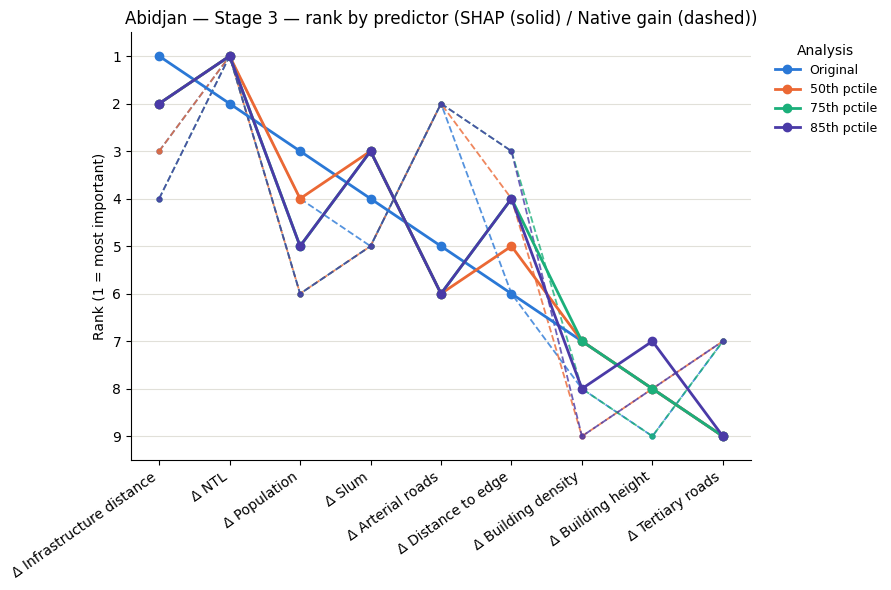

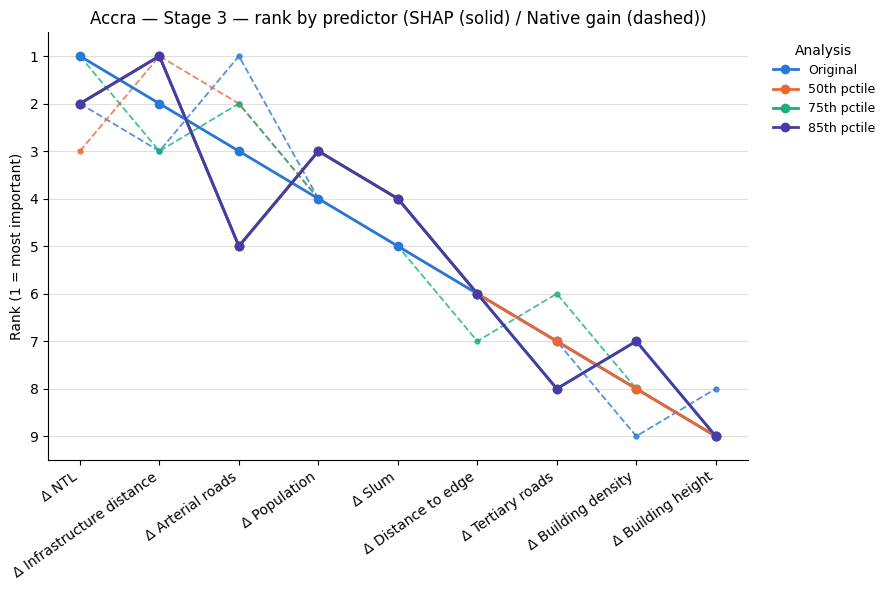

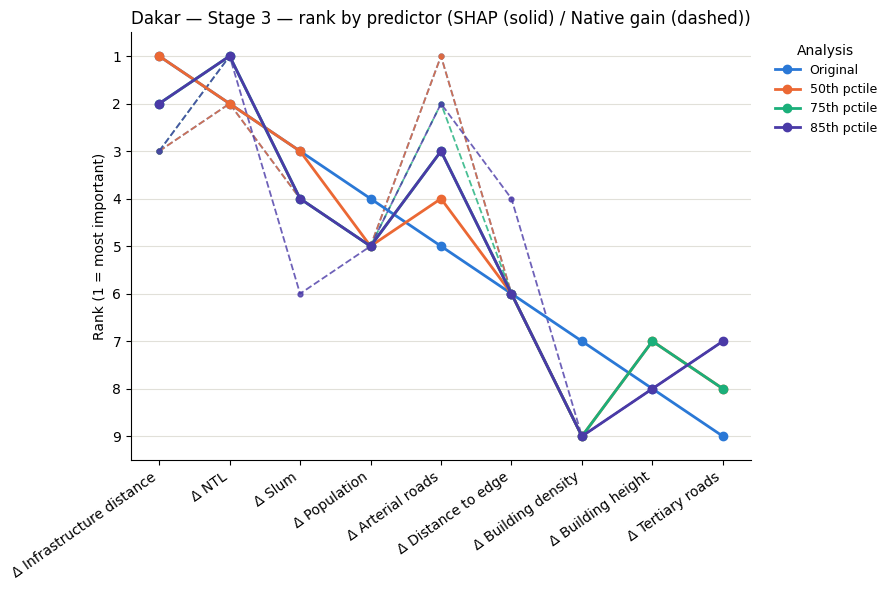

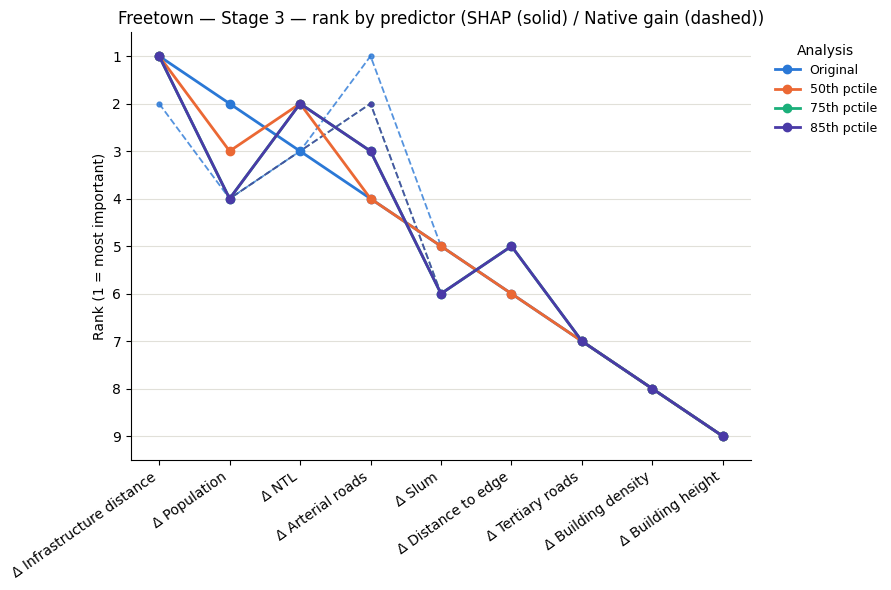

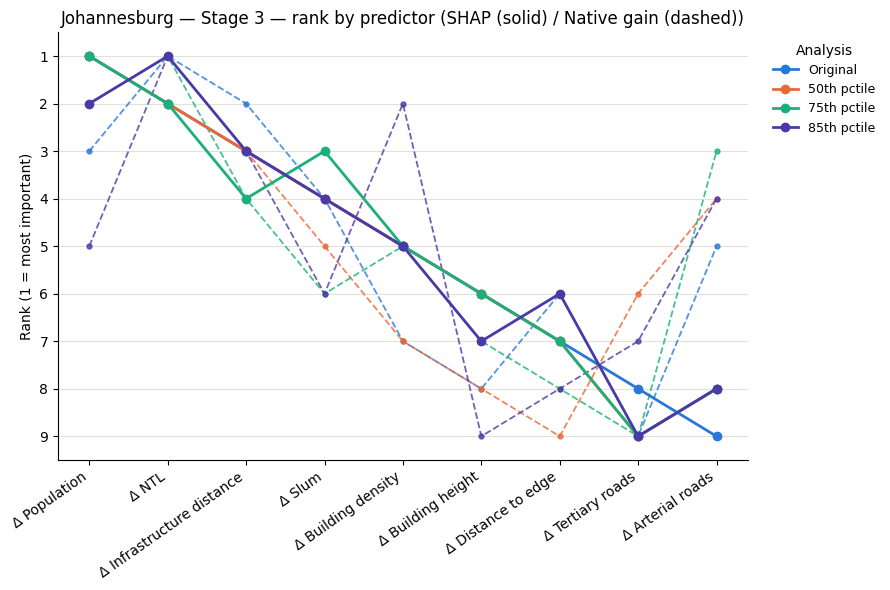

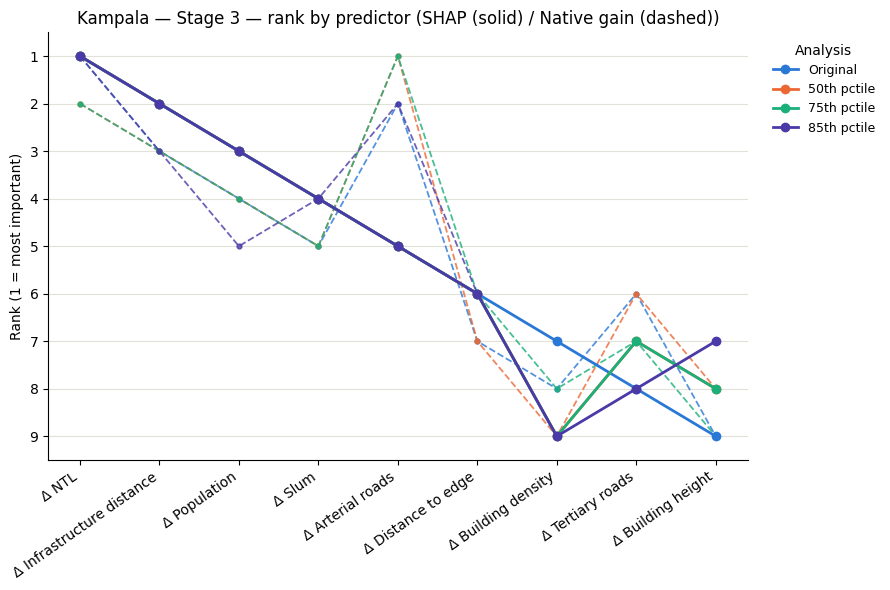

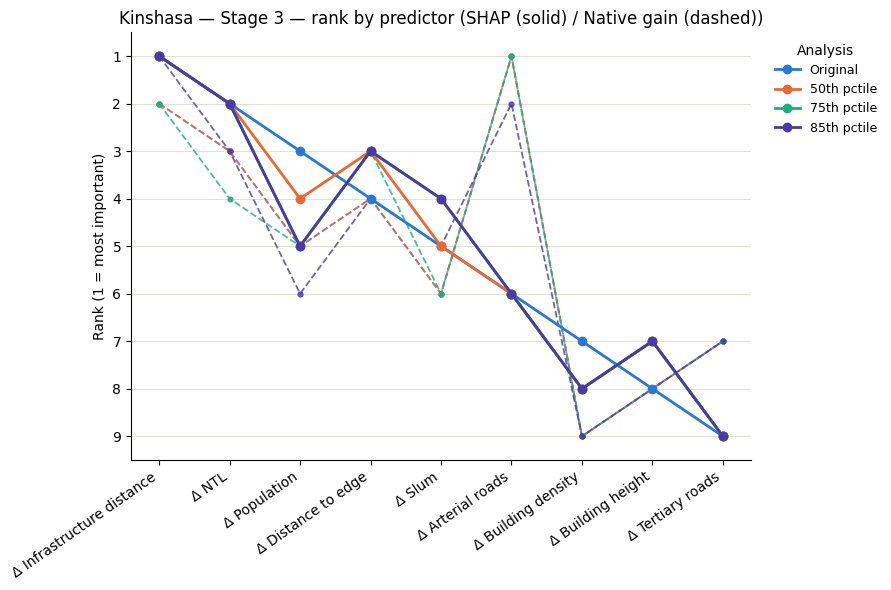

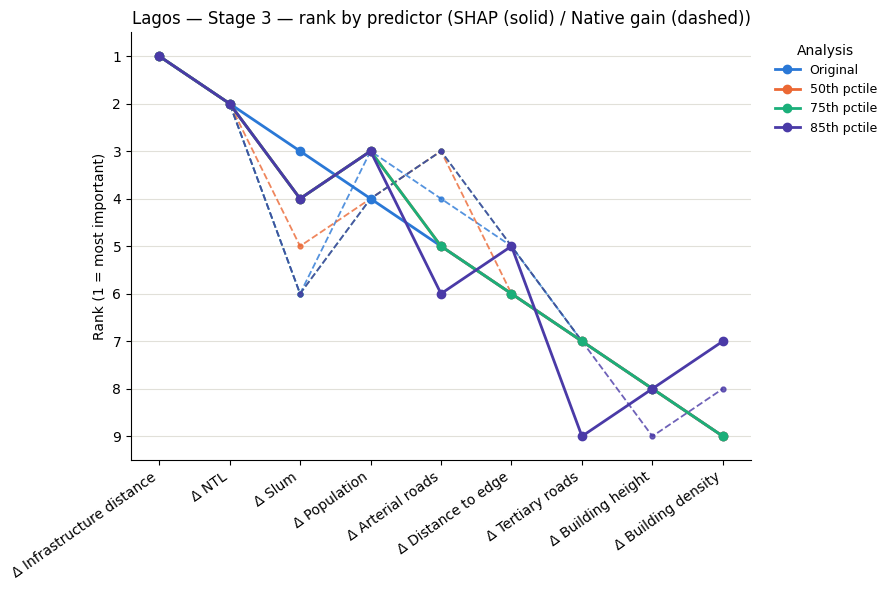

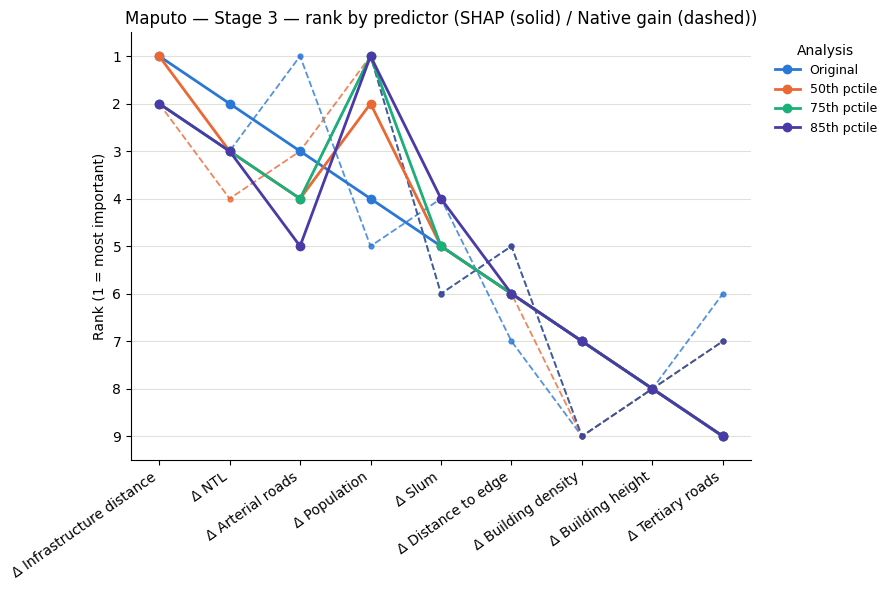

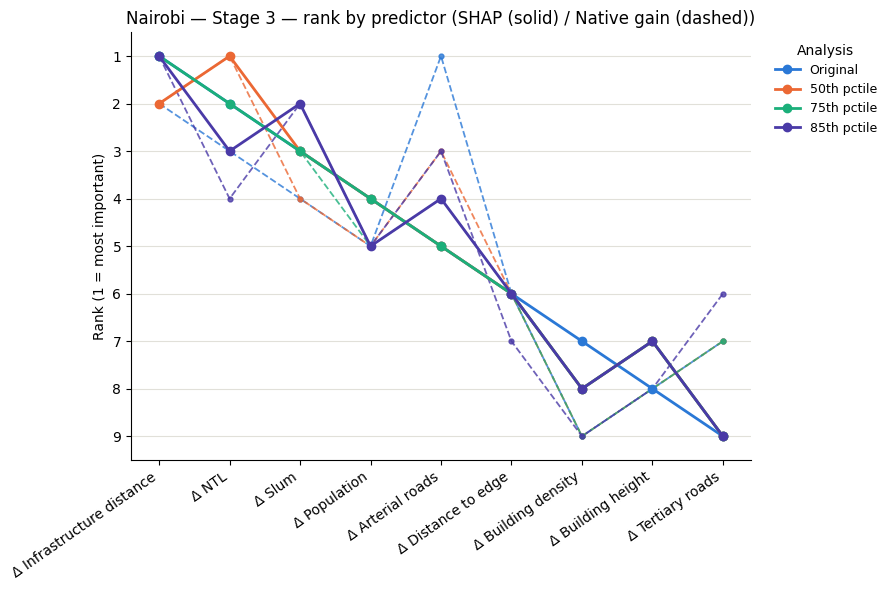


STAGE 3 — average SHAP rank per city (mean across Original/50/75/85th)
city                       Abidjan  Accra  Dakar  Freetown  Johannesburg  Kampala  Kinshasa  Lagos  Maputo  Nairobi  avg    sd
predictor                                                                                                                     
Δ Infrastructure distance      1.8    1.2    1.5       1.0           3.2      2.0       1.0    1.0     1.5      1.2  1.5  0.68
Δ NTL                          1.2    1.8    1.5       2.2           1.8      1.0       2.0    2.0     2.8      2.0  1.8  0.51
Δ Population                   4.2    3.2    4.8       3.2           1.2      3.0       4.2    3.2     2.0      4.2  3.3  1.10
Δ Slum                         3.2    4.2    3.5       5.5           3.8      4.0       4.5    3.8     4.8      2.8  4.0  0.79
Δ Arterial roads               5.8    4.5    3.8       3.5           8.2      5.0       6.0    5.2     4.0      4.8  5.1  1.37
Δ Distance to edge             4.8    6

In [ ]:
"""
Rank stability chart: tracks each predictor's SHAP rank and native-gain rank
across the 4 analyses (Original, 50th pctile, 75th pctile, 85th pctile) for
a given city + stage.

Run in Colab after mounting Drive. Figures are NOT saved to Drive by default
(save_path=None) — they only display inline.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

LABELS = ["Original", "50th pctile", "75th pctile", "85th pctile"]

# Cove categorical palette (fixed order) + gray fallback for the 9th series
PALETTE = [
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
    "#008300", "#4a3aa7", "#e34948", "#767671",
]

# Colors for the 4 analysis types (used in the by-predictor orientation)
ANALYSIS_COLORS = {
    "Original": "#2a78d6",
    "50th pctile": "#eb6834",
    "75th pctile": "#1baf7a",
    "85th pctile": "#4a3aa7",
}

# =====================================================================
# Stage config: predictors, file naming, and display labels differ by stage.
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_sensitivity_results.csv",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_sensitivity_results.csv",
    },
    3: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set as Stage 2
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage3_growth_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage3_growth_sensitivity_results.csv",
    },
    4: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set
        "labels": STAGE2_LABELS,
        "orig_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage4_decline_results.csv",
        "sens_path": lambda city, c: f"{SENSITIVITY_DIR}/{city}/{c}_stage4_decline_sensitivity_results.csv",  # unconfirmed
    },
}


def load_ranks(city, stage):
    """Returns dict: predictor -> {'shap': [4 ranks], 'native': [4 ranks]}"""
    cfg = STAGE_CONFIG[stage]
    c = city.lower()

    orig = pd.read_csv(cfg["orig_path"](city, c)).iloc[0]
    sens = pd.read_csv(cfg["sens_path"](city, c)).set_index("percentile")

    ranks = {}
    for p in cfg["predictors"]:
        shap_seq = [
            orig[f"{p}_shap_rank"],
            sens.loc[50, f"{p}_shap_rank"],
            sens.loc[75, f"{p}_shap_rank"],
            sens.loc[85, f"{p}_shap_rank"],
        ]
        native_seq = [
            orig[f"{p}_native_rank"],
            sens.loc[50, f"{p}_native_rank"],
            sens.loc[75, f"{p}_native_rank"],
            sens.loc[85, f"{p}_native_rank"],
        ]
        ranks[p] = {"shap": shap_seq, "native": native_seq}
    return ranks


def plot_rank_stability(city, stage, save_path=None):
    """Predictors as separate lines, x-axis = the 4 analyses."""
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    fig, ax = plt.subplots(figsize=(9, 6.5))
    x = range(len(LABELS))

    for i, p in enumerate(predictors):
        color = PALETTE[i % len(PALETTE)]
        ax.plot(x, ranks[p]["shap"], color=color, linewidth=2,
                marker="o", markersize=6, label=label_map[p], zorder=3)
        ax.plot(x, ranks[p]["native"], color=color, linewidth=1.3,
                linestyle="--", marker="o", markersize=3.5, alpha=0.85, zorder=2)

    ax.set_xticks(list(x))
    ax.set_xticklabels(LABELS)
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 SHAP vs native rank stability")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

    predictor_handles = [mlines.Line2D([], [], color=PALETTE[i % len(PALETTE)],
                                        linewidth=2, label=label_map[p])
                          for i, p in enumerate(predictors)]
    style_handles = [
        mlines.Line2D([], [], color="black", linewidth=2, label="SHAP rank"),
        mlines.Line2D([], [], color="black", linewidth=1.3, linestyle="--", label="Native gain rank"),
    ]

    leg1 = ax.legend(handles=predictor_handles, bbox_to_anchor=(1.02, 1), loc="upper left",
                      fontsize=9, title="Predictor", frameon=False)
    ax.add_artist(leg1)
    ax.legend(handles=style_handles, bbox_to_anchor=(1.02, 0.25), loc="upper left",
               fontsize=9, frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def plot_rank_stability_by_predictor(city, stage, order_by="Original", metric="both", save_path=None):
    """
    Alternate orientation: x-axis = predictors, y-axis = rank, one line per
    analysis (Original/50th/75th/85th). Predictors are ordered along the
    x-axis by their SHAP rank in `order_by` (default: Original).

    metric: "shap", "native", or "both" (both = solid SHAP + dashed native,
    same color per analysis).
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]
    ranks = load_ranks(city, stage)
    n = len(predictors)

    ref_idx = LABELS.index(order_by)
    ordered_predictors = sorted(predictors, key=lambda p: ranks[p]["shap"][ref_idx])
    ordered_display = [label_map[p] for p in ordered_predictors]

    fig, ax = plt.subplots(figsize=(9, 6))
    x = range(n)

    for li, label in enumerate(LABELS):
        color = ANALYSIS_COLORS[label]
        if metric in ("shap", "both"):
            y_shap = [ranks[p]["shap"][li] for p in ordered_predictors]
            ax.plot(x, y_shap, color=color, linewidth=2, marker="o",
                     markersize=6, label=label, zorder=3)
        if metric in ("native", "both"):
            y_native = [ranks[p]["native"][li] for p in ordered_predictors]
            ax.plot(x, y_native, color=color, linewidth=1.3, linestyle="--",
                     marker="o", markersize=3.5, alpha=0.8, zorder=2,
                     label=None if metric == "both" else label)

    ax.set_xticks(list(x))
    ax.set_xticklabels(ordered_display, rotation=35, ha="right")
    ax.set_ylim(n + 0.5, 0.5)  # inverted: rank 1 at top
    ax.set_yticks(range(1, n + 1))
    ax.set_ylabel("Rank (1 = most important)")
    metric_label = {"shap": "SHAP", "native": "Native gain", "both": "SHAP (solid) / Native gain (dashed)"}[metric]
    ax.set_title(f"{city} \u2014 Stage {stage} \u2014 rank by predictor ({metric_label})")
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9,
              title="Analysis", frameon=False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def summary_table_all_cities(cities, stage):
    """
    Pretty-print summary: for each city, each predictor's average SHAP rank
    (mean across Original/50th/75th/85th), plus an overall average rank and
    SD across cities. Lower rank = more important.
    """
    cfg = STAGE_CONFIG[stage]
    predictors, label_map = cfg["predictors"], cfg["labels"]

    all_rows = []
    for city in cities:
        ranks = load_ranks(city, stage)
        for p in predictors:
            seq = ranks[p]["shap"]
            all_rows.append({"city": city, "predictor": label_map[p], "avg_rank": sum(seq) / len(seq)})
    df = pd.DataFrame(all_rows)

    pivot = df.pivot(index="predictor", columns="city", values="avg_rank").round(1)
    pivot["avg"] = pivot[cities].mean(axis=1).round(1)
    pivot["sd"] = pivot[cities].std(axis=1).round(2)
    pivot = pivot.sort_values("avg")

    print("\n" + "=" * 70)
    print(f"STAGE {stage} \u2014 average SHAP rank per city (mean across Original/50/75/85th)")
    print("=" * 70)
    print(pivot.to_string())
    print("\nLower = more important. 'sd' = spread of each predictor's avg rank across cities.")

    return df, pivot


def validate_stage_files(cities, stage):
    """
    Quick structural check before running the full analysis: confirms each
    city's original + sensitivity CSVs exist, have the expected predictor
    rank/importance columns, and that the sensitivity file has all 3
    percentile rows. Prints a pass/fail summary; does not plot anything.
    """
    cfg = STAGE_CONFIG[stage]
    predictors = cfg["predictors"]
    expected_cols = set()
    for p in predictors:
        expected_cols.update([f"{p}_native_gain", f"{p}_native_rank",
                               f"{p}_shap_importance", f"{p}_shap_rank"])

    problems = []
    for city in cities:
        c = city.lower()

        orig_path = cfg["orig_path"](city, c)
        sens_path = cfg["sens_path"](city, c)

        try:
            orig = pd.read_csv(orig_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING original file -> {orig_path}")
            continue

        try:
            sens = pd.read_csv(sens_path)
        except FileNotFoundError:
            problems.append(f"{city}: MISSING sensitivity file -> {sens_path}")
            continue

        missing_orig = expected_cols - set(orig.columns)
        if missing_orig:
            problems.append(f"{city}: original file missing columns: {sorted(missing_orig)}")

        missing_sens = expected_cols - set(sens.columns)
        if missing_sens:
            problems.append(f"{city}: sensitivity file missing columns: {sorted(missing_sens)}")

        if "percentile" not in sens.columns:
            problems.append(f"{city}: sensitivity file missing 'percentile' column")
        else:
            found_pcts = set(sens["percentile"].tolist())
            if found_pcts != {50, 75, 85}:
                problems.append(f"{city}: sensitivity file has percentiles {sorted(found_pcts)}, expected [50, 75, 85]")

        if len(orig) != 1:
            problems.append(f"{city}: original file has {len(orig)} rows, expected 1")

    print("=" * 70)
    print(f"STAGE {stage} FILE VALIDATION — {len(cities)} cities checked")
    print("=" * 70)
    if not problems:
        print("All clear — every city has both files with the expected structure.")
    else:
        for p in problems:
            print(f"  \u2717 {p}")
        print(f"\n{len(problems)} issue(s) found across {len(cities)} cities.")
    return problems


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    stage = 3  # Growth
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    validate_stage_files(cities, stage)  # run this first

    for city in cities:
        plot_rank_stability_by_predictor(city, stage)  # save_path=None -> not written to Drive

    long_df, summary_pivot = summary_table_all_cities(cities, stage)

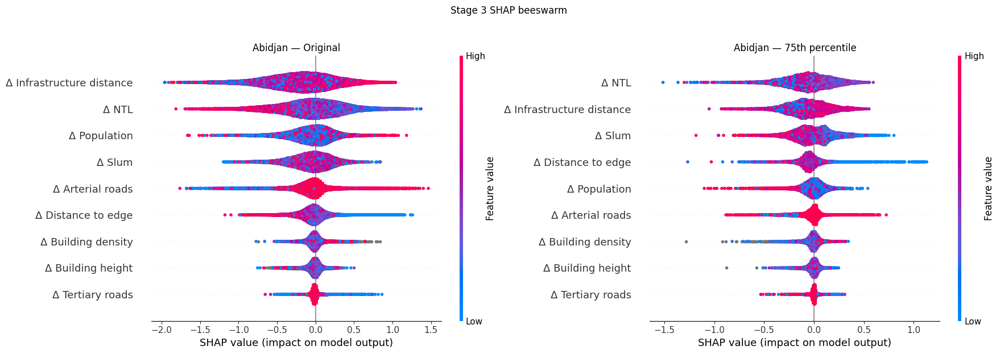

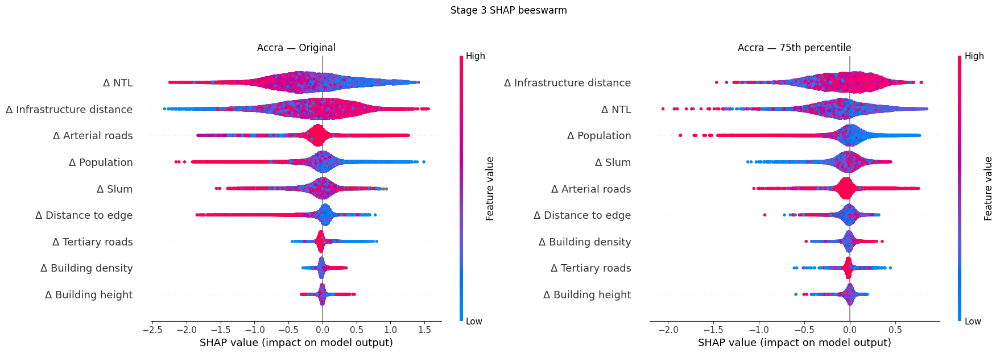

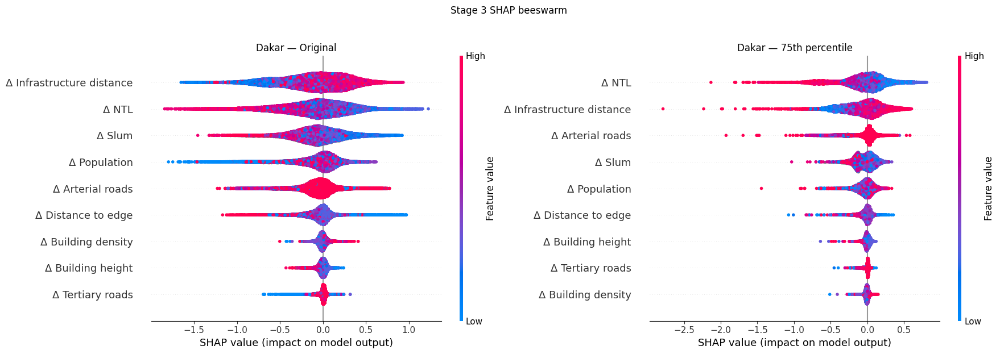

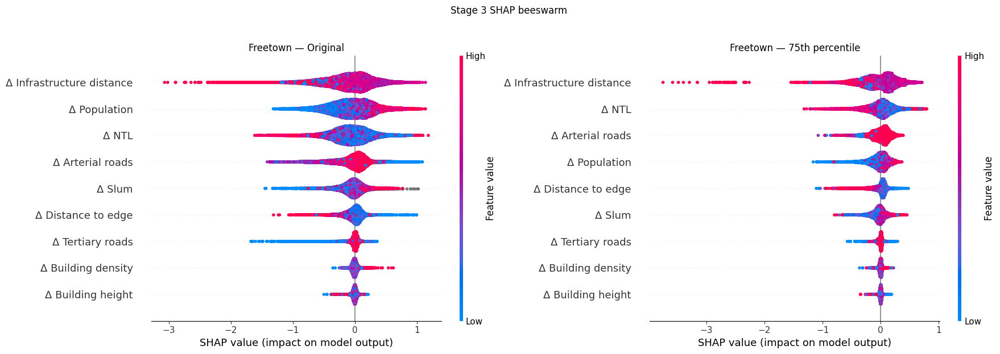

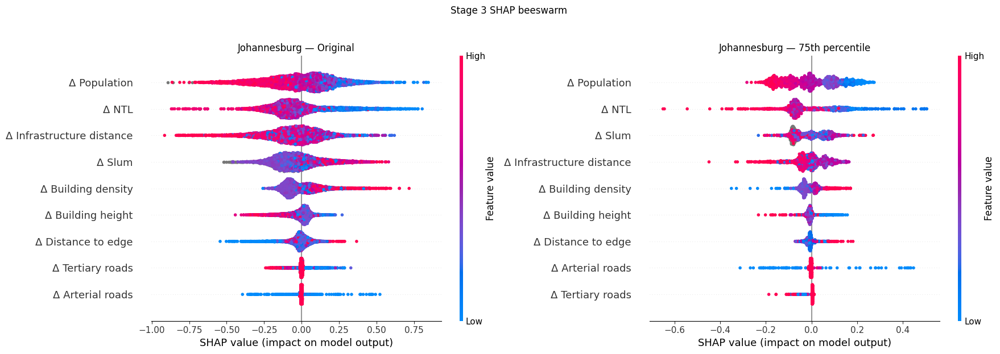

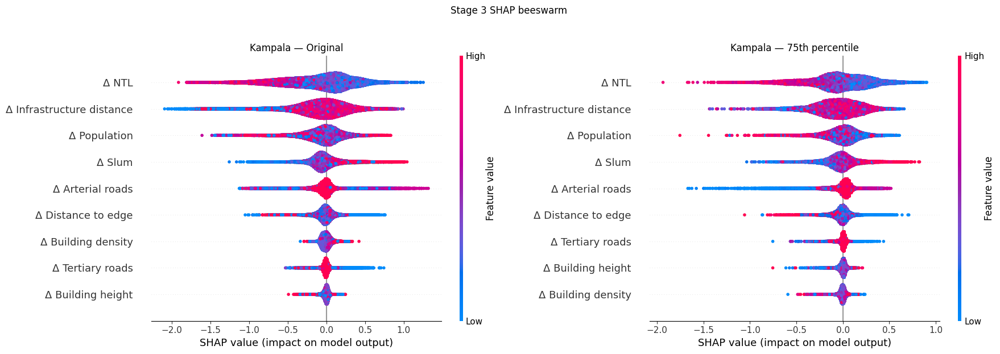

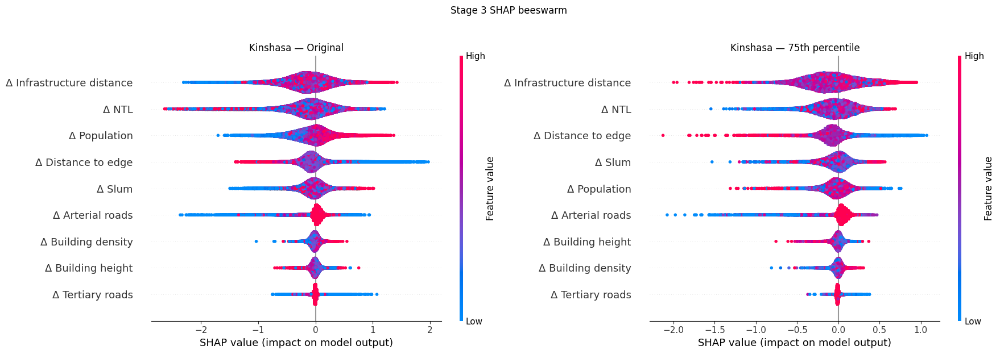

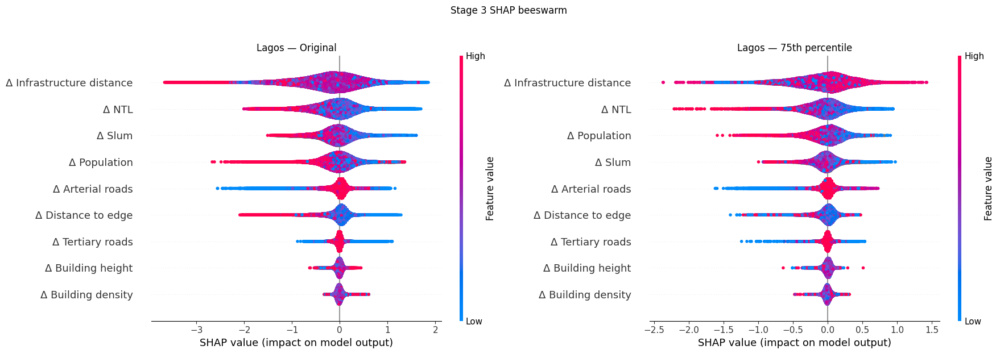

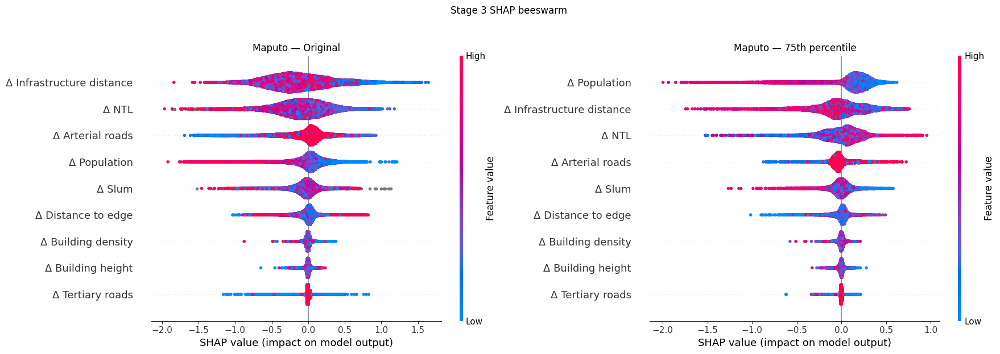

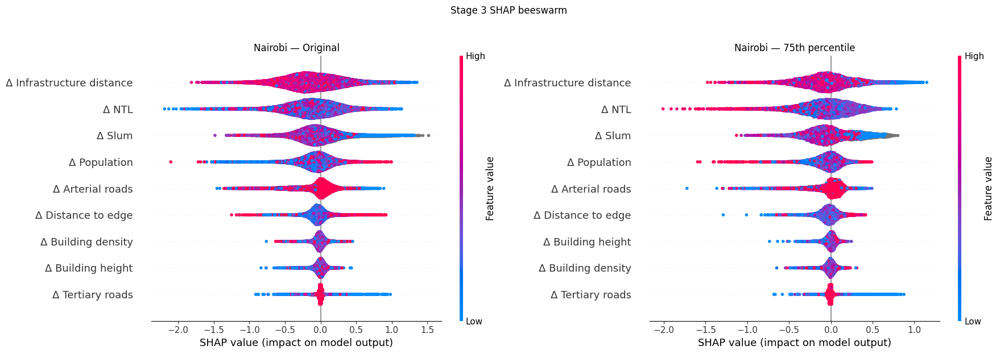

In [ ]:
"""
SHAP beeswarm plots, two columns per city: Original vs {percentile}th percentile.
Run in Colab after mounting Drive. Not saved to Drive — displays inline only.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
SENSITIVITY_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity"

# =====================================================================
# Stage 1 — Stable-absent
# =====================================================================

STAGE1_PREDICTORS = [
    "Population", "Slum", "NTL", "Dist_open_edge",
    "Building_density", "Building_height", "Infra_distance",
    "Arterial_roads", "Tertiary_roads",
]
STAGE1_LABELS = {
    "Population": "Population",
    "Slum": "Slum",
    "NTL": "NTL",
    "Dist_open_edge": "Distance to edge",
    "Building_density": "Building density",
    "Building_height": "Building height",
    "Infra_distance": "Infrastructure distance",
    "Arterial_roads": "Arterial roads",
    "Tertiary_roads": "Tertiary roads",
}


def build_stage1_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 1 SHAP values were computed
    (stacked 2016+2024 rows, filtered by DV percentile if given).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in STAGE1_PREDICTORS}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["year"] = year
        sub["DV"] = df[dv_col]
        return sub

    stacked = pd.concat(
        [build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")],
        ignore_index=True,
    )
    stacked["target"] = (stacked["DV"] > 0).astype(int)

    if percentile is None:
        return stacked[STAGE1_PREDICTORS]

    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = present_pool.quantile(percentile / 100)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[STAGE1_PREDICTORS]


# =====================================================================
# Stage 2 — Persistence
# =====================================================================

STAGE2_PREDICTORS = [
    "delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
    "delta_building_density", "delta_building_height", "delta_infra_distance",
    "delta_arterial_roads", "delta_tertiary_roads",
]
STAGE2_LABELS = {
    "delta_population": "\u0394 Population",
    "delta_slum": "\u0394 Slum",
    "delta_ntl": "\u0394 NTL",
    "delta_dist_open_edge": "\u0394 Distance to edge",
    "delta_building_density": "\u0394 Building density",
    "delta_building_height": "\u0394 Building height",
    "delta_infra_distance": "\u0394 Infrastructure distance",
    "delta_arterial_roads": "\u0394 Arterial roads",
    "delta_tertiary_roads": "\u0394 Tertiary roads",
}


def build_stage2_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 2 (Persistence) SHAP values were
    computed: Persistent (DV2016>0 & DV2024>0) + Cleared (DV2016>0 & DV2024=0),
    filtered by their respective DV percentile if given, concatenated
    Persistent-then-Cleared (matches build_stage2_data in your script).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    persist_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0)].copy()
    persist_all["Avg_DV"] = (persist_all["DV_2016"] + persist_all["DV_2024"]) / 2
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()

    if percentile is None:
        persist_f, clear_f = persist_all, clear_all
    else:
        p_cut = persist_all["Avg_DV"].quantile(percentile / 100)
        c_cut = clear_all["DV_2016"].quantile(percentile / 100)
        persist_f = persist_all[persist_all["Avg_DV"] >= p_cut]
        clear_f = clear_all[clear_all["DV_2016"] >= c_cut]

    persist_f = persist_f.copy(); persist_f["target"] = 1
    clear_f = clear_f.copy(); clear_f["target"] = 0
    data = pd.concat([persist_f, clear_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]


# =====================================================================
# Stage 3 — Growth (Emergent + Increase)
# =====================================================================

def build_stage3_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 3 (Growth) SHAP values were computed:
    Emergent (DV2024>0 & DV2016=0) + Increase (DV2016>0 & DV2024>0 &
    DV2024>DV2016), both filtered on DV_2024 percentile if given, concatenated
    Emergent-then-Increase (matches build_stage3_data in your script).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()

    if percentile is None:
        em_f, inc_f = emergent_all, increase_all
    else:
        e_cut = emergent_all["DV_2024"].quantile(percentile / 100)
        i_cut = increase_all["DV_2024"].quantile(percentile / 100)
        em_f = emergent_all[emergent_all["DV_2024"] >= e_cut]
        inc_f = increase_all[increase_all["DV_2024"] >= i_cut]

    data = pd.concat([em_f, inc_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]  # same delta_* predictor set as Stage 2


def build_stage4_X(city, percentile=None):
    """
    Rebuilds the exact X used when Stage 4 (Decline) SHAP values were computed:
    Cleared (DV2016>0 & DV2024=0) + Decrease (DV2016>0 & DV2024>0 &
    DV2016>DV2024), both filtered on DV_2016 percentile if given, concatenated
    Cleared-then-Decrease (matches your Stage 4 script's build order).
    """
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()

    if percentile is None:
        cl_f, dec_f = cleared_all, decrease_all
    else:
        cl_cut = cleared_all["DV_2016"].quantile(percentile / 100)
        dec_cut = decrease_all["DV_2016"].quantile(percentile / 100)
        cl_f = cleared_all[cleared_all["DV_2016"] >= cl_cut]
        dec_f = decrease_all[decrease_all["DV_2016"] >= dec_cut]

    data = pd.concat([cl_f, dec_f], ignore_index=True)
    return data[STAGE2_PREDICTORS]


# =====================================================================
# Stage config: predictors, X-builder, .npy paths, and display labels.
# NOTE: Stage 2's ORIGINAL (non-percentile) .npy path below is inferred by
# analogy to Stage 1's naming (not yet confirmed against your original
# Stage 2 script) — double-check the filename on Drive before trusting it.
# =====================================================================

STAGE_CONFIG = {
    1: {
        "predictors": STAGE1_PREDICTORS,
        "labels": STAGE1_LABELS,
        "build_X": build_stage1_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage1_shap_values.npy",
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage1_shap_values_pct{pct}.npy",
    },
    2: {
        "predictors": STAGE2_PREDICTORS,
        "labels": STAGE2_LABELS,
        "build_X": build_stage2_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage2_persistence_shap_values.npy",  # unconfirmed
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage2_persistence_shap_values_pct{pct}.npy",
    },
    3: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set
        "labels": STAGE2_LABELS,
        "build_X": build_stage3_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage3_growth_shap_values.npy",
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage3_growth_shap_values_pct{pct}.npy",
    },
    4: {
        "predictors": STAGE2_PREDICTORS,  # same delta_* set
        "labels": STAGE2_LABELS,
        "build_X": build_stage4_X,
        "orig_shap_path": lambda city, c: f"{COMBINED_DIR}/{city}/{c}_stage4_decline_shap_values.npy",
        "sens_shap_path": lambda city, c, pct: f"{SENSITIVITY_DIR}/{city}/{c}_stage4_decline_shap_values_pct{pct}.npy",  # unconfirmed
    },
}


def plot_shap_beeswarm_grid(cities, stage=1, percentile=75, max_display=9):
    """Two-column SHAP beeswarm figure per city: Original (left) vs {percentile}th (right)."""
    cfg = STAGE_CONFIG[stage]
    feature_labels = [cfg["labels"][p] for p in cfg["predictors"]]

    for city in cities:
        c = city.lower()

        shap_orig = np.load(cfg["orig_shap_path"](city, c))
        X_orig = cfg["build_X"](city, percentile=None)

        shap_pct = np.load(cfg["sens_shap_path"](city, c, percentile))
        X_pct = cfg["build_X"](city, percentile=percentile)

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))

        plt.sca(axes[0])
        # plot_size=None stops shap from resizing the whole figure on each call
        shap.summary_plot(shap_orig, X_orig, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[0].set_title(f"{city} \u2014 Original")

        plt.sca(axes[1])
        shap.summary_plot(shap_pct, X_pct, feature_names=feature_labels,
                           max_display=max_display, show=False, plot_size=None)
        axes[1].set_title(f"{city} \u2014 {percentile}th percentile")

        fig.suptitle(f"Stage {stage} SHAP beeswarm", y=1.03)
        plt.tight_layout()
        plt.show()  # not saved to Drive


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    plot_shap_beeswarm_grid(cities, stage=3, percentile=75)

Overall analysis

In [ ]:
cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

stage_names = {1: "Stable-absent", 2: "Persistence", 3: "Growth", 4: "Decline"}
all_summaries = {}

for stage in [1, 2, 3, 4]:
    print(f"\n{'='*70}\nSTAGE {stage} — {stage_names[stage]}\n{'='*70}")
    problems = validate_stage_files(cities, stage)
    if problems:
        print("Fix the above before proceeding to the summary table.")
        continue
    long_df, summary_pivot = summary_table_all_cities(cities, stage)
    all_summaries[stage] = summary_pivot


STAGE 1 — Stable-absent
STAGE 1 FILE VALIDATION — 10 cities checked
All clear — every city has both files with the expected structure.

STAGE 1 — average SHAP rank per city (mean across Original/50/75/85th)
city                     Abidjan  Accra  Dakar  Freetown  Johannesburg  Kampala  Kinshasa  Lagos  Maputo  Nairobi  avg    sd
predictor                                                                                                                   
Infrastructure distance      1.0    1.2    2.0       1.0           5.0      1.0       2.0    1.8     1.0      1.8  1.8  1.21
NTL                          2.0    1.8    1.0       2.2           4.5      2.0       1.0    2.8     2.0      3.0  2.2  1.02
Arterial roads               4.0    3.0    4.0       3.0           5.8      5.0       3.0    1.5     3.0      4.5  3.7  1.23
Slum                         5.0    5.2    5.0       5.0           1.0      3.0       5.0    4.0     4.5      1.2  3.9  1.61
Population                   3.0    4.0   

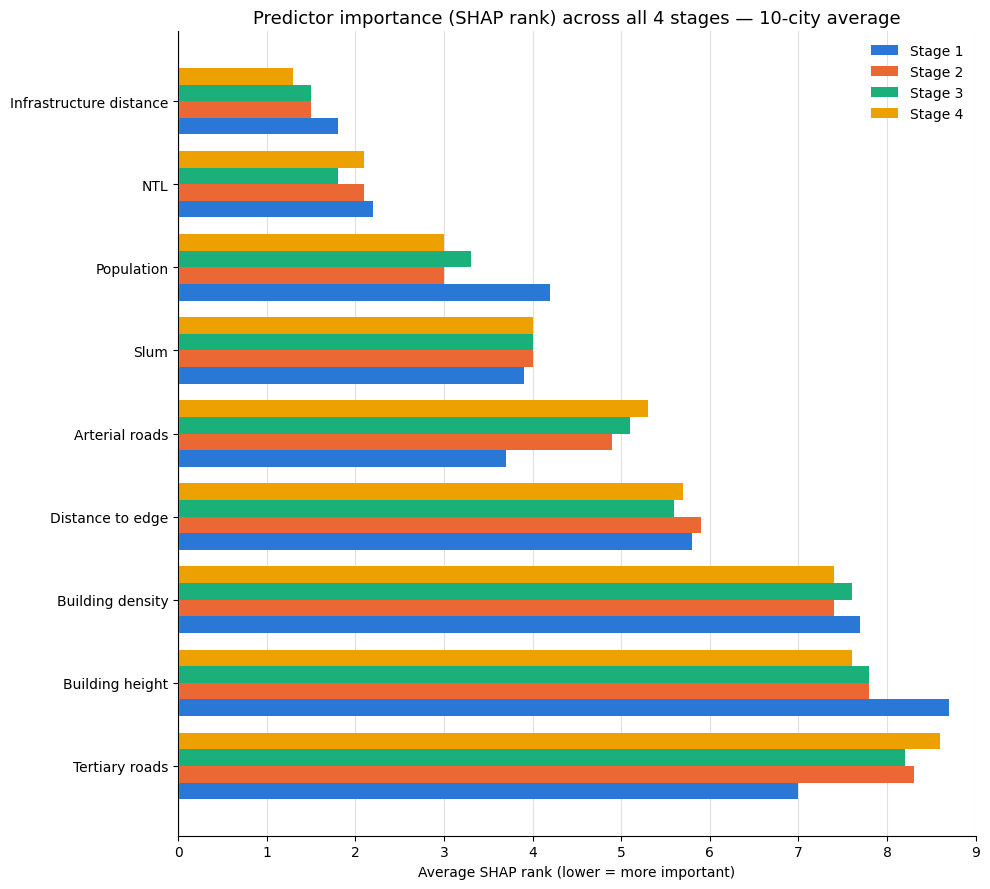

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

predictors = ['Infrastructure distance', 'NTL', 'Population', 'Slum', 'Arterial roads',
              'Distance to edge', 'Building density', 'Building height', 'Tertiary roads']

stage_data = {
    'Stage 1': [1.8, 2.2, 4.2, 3.9, 3.7, 5.8, 7.7, 8.7, 7.0],
    'Stage 2': [1.5, 2.1, 3.0, 4.0, 4.9, 5.9, 7.4, 7.8, 8.3],
    'Stage 3': [1.5, 1.8, 3.3, 4.0, 5.1, 5.6, 7.6, 7.8, 8.2],
    'Stage 4': [1.3, 2.1, 3.0, 4.0, 5.3, 5.7, 7.4, 7.6, 8.6],
}

colors = {'Stage 1': '#2a78d6', 'Stage 2': '#eb6834', 'Stage 3': '#1baf7a', 'Stage 4': '#eda100'}

n_predictors = len(predictors)
n_stages = len(stage_data)
bar_height = 0.8 / n_stages
y_base = np.arange(n_predictors)[::-1]  # reverse so first predictor plots at top

fig, ax = plt.subplots(figsize=(10, 9))

for i, (stage, values) in enumerate(stage_data.items()):
    offset = (i - (n_stages - 1) / 2) * bar_height
    ax.barh(y_base + offset, values, height=bar_height, color=colors[stage], label=stage)

ax.set_yticks(y_base)
ax.set_yticklabels(predictors)
ax.set_xlabel('Average SHAP rank (lower = more important)')
ax.set_xlim(0, 9)
ax.axvline(0, color='#c3c2b7', linewidth=1)
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

ax.legend(loc='upper right', frameon=False, fontsize=10)
ax.set_title('Predictor importance (SHAP rank) across all 4 stages — 10-city average', fontsize=13)

plt.tight_layout()
plt.show()

  Stage 1 — Abidjan: 50,000 / 170,225 points
  Stage 1 — Accra: 50,000 / 877,064 points
  Stage 1 — Dakar: 50,000 / 316,131 points
  Stage 1 — Freetown: 50,000 / 163,138 points
  Stage 1 — Johannesburg: 50,000 / 70,528 points
  Stage 1 — Kampala: 50,000 / 414,127 points
  Stage 1 — Kinshasa: 50,000 / 296,588 points
  Stage 1 — Lagos: 50,000 / 1,609,243 points
  Stage 1 — Maputo: 50,000 / 460,290 points
  Stage 1 — Nairobi: 50,000 / 227,360 points

Stage 1 combined: 500,000 points across 10 cities (75th percentile)



/tmp/ipykernel_669/1500551406.py:103: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_combined, X_combined, show=True)


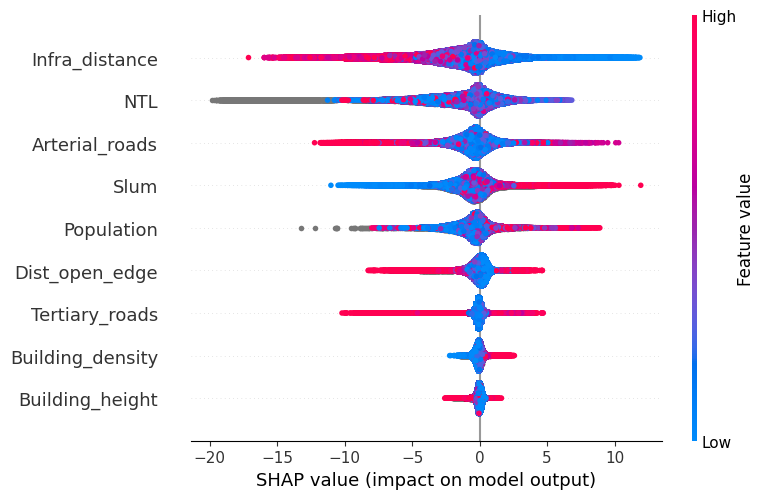

  Stage 2 — Abidjan: 17,229 / 17,229 points
  Stage 2 — Accra: 50,000 / 68,067 points
  Stage 2 — Dakar: 14,611 / 14,611 points
  Stage 2 — Freetown: 15,341 / 15,341 points
  Stage 2 — Johannesburg: 1,871 / 1,871 points
  Stage 2 — Kampala: 50,000 / 56,166 points
  Stage 2 — Kinshasa: 49,080 / 49,080 points
  Stage 2 — Lagos: 50,000 / 158,725 points
  Stage 2 — Maputo: 30,494 / 30,494 points
  Stage 2 — Nairobi: 27,862 / 27,862 points

Stage 2 combined: 306,488 points across 10 cities (75th percentile)



/tmp/ipykernel_669/1500551406.py:103: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_combined, X_combined, show=True)


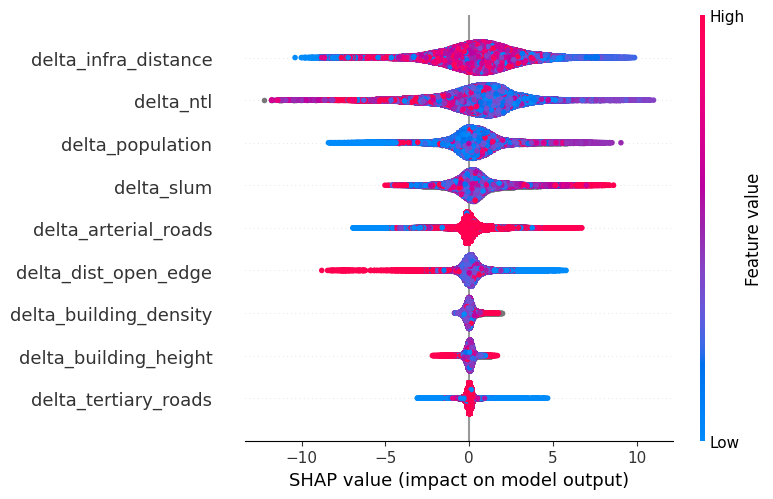

  Stage 3 — Abidjan: 14,737 / 14,737 points
  Stage 3 — Accra: 29,533 / 29,533 points
  Stage 3 — Dakar: 15,238 / 15,238 points
  Stage 3 — Freetown: 14,535 / 14,535 points
  Stage 3 — Johannesburg: 1,627 / 1,627 points
  Stage 3 — Kampala: 30,593 / 30,593 points
  Stage 3 — Kinshasa: 30,706 / 30,706 points
  Stage 3 — Lagos: 50,000 / 90,192 points
  Stage 3 — Maputo: 19,238 / 19,238 points
  Stage 3 — Nairobi: 15,147 / 15,147 points

Stage 3 combined: 221,354 points across 10 cities (75th percentile)



/tmp/ipykernel_669/1500551406.py:103: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_combined, X_combined, show=True)


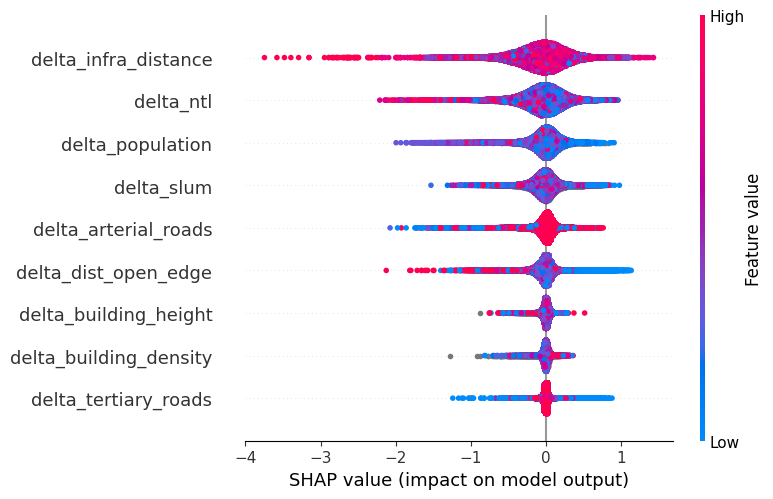

  Stage 4 — Abidjan: 10,653 / 10,653 points
  Stage 4 — Accra: 50,000 / 53,674 points
  Stage 4 — Dakar: 10,510 / 10,510 points
  Stage 4 — Freetown: 6,584 / 6,584 points
  Stage 4 — Johannesburg: 1,126 / 1,126 points
  Stage 4 — Kampala: 36,478 / 36,478 points
  Stage 4 — Kinshasa: 24,906 / 24,906 points
  Stage 4 — Lagos: 50,000 / 97,972 points
  Stage 4 — Maputo: 21,104 / 21,104 points
  Stage 4 — Nairobi: 18,007 / 18,007 points

Stage 4 combined: 229,368 points across 10 cities (75th percentile)



/tmp/ipykernel_669/1500551406.py:103: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_combined, X_combined, show=True)


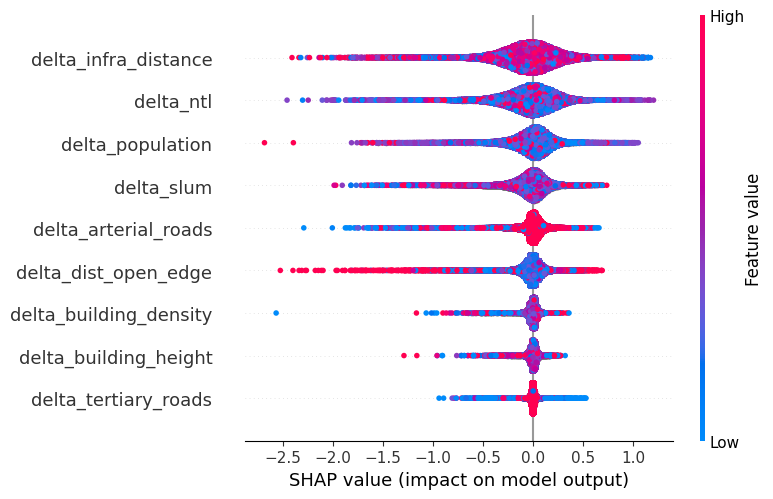

In [ ]:
import pandas as pd
import numpy as np
import shap

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

predictor_base = ["Population", "Slum", "NTL", "Dist_open_edge", "Building_density",
                   "Building_height", "Infra_distance", "Arterial_roads", "Tertiary_roads"]
delta_predictors = ["delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
                     "delta_building_density", "delta_building_height", "delta_infra_distance",
                     "delta_arterial_roads", "delta_tertiary_roads"]

PCT = 75
N_PER_CITY = 50000

# =====================================================================
# Per-stage dataset builders (mirrors each sensitivity script's logic)
# =====================================================================

def build_stage1_X(df, pct):
    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in predictor_base}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["DV"] = df[dv_col]
        return sub
    stacked = pd.concat([build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = np.percentile(present_pool, pct)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[predictor_base]

def build_stage2_X(df, pct):
    persist_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0)].copy()
    persist_all["Avg_DV"] = (persist_all["DV_2016"] + persist_all["DV_2024"]) / 2
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    p_cut = np.percentile(persist_all["Avg_DV"], pct)
    c_cut = np.percentile(clear_all["DV_2016"], pct)
    persist_f = persist_all[persist_all["Avg_DV"] >= p_cut]
    clear_f = clear_all[clear_all["DV_2016"] >= c_cut]
    data = pd.concat([persist_f, clear_f], ignore_index=True)
    return data[delta_predictors]

def build_stage3_X(df, pct):
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = np.percentile(emergent_all["DV_2024"], pct)
    i_cut = np.percentile(increase_all["DV_2024"], pct)
    em_f = emergent_all[emergent_all["DV_2024"] >= e_cut]
    inc_f = increase_all[increase_all["DV_2024"] >= i_cut]
    data = pd.concat([em_f, inc_f], ignore_index=True)
    return data[delta_predictors]

def build_stage4_X(df, pct):
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    c_cut = np.percentile(clear_all["DV_2016"], pct)
    d_cut = np.percentile(decrease_all["DV_2016"], pct)
    clear_f = clear_all[clear_all["DV_2016"] >= c_cut]
    dec_f = decrease_all[decrease_all["DV_2016"] >= d_cut]
    data = pd.concat([clear_f, dec_f], ignore_index=True)
    return data[delta_predictors]

STAGE_CONFIG = {
    1: {"name": "stage1", "build_X": build_stage1_X},
    2: {"name": "stage2_persistence", "build_X": build_stage2_X},
    3: {"name": "stage3_growth", "build_X": build_stage3_X},
    4: {"name": "stage4_decline", "build_X": build_stage4_X},
}

# =====================================================================
# Build combined X + SHAP per stage, plot
# =====================================================================

for stage in [1, 2, 3, 4]:
    cfg = STAGE_CONFIG[stage]
    X_all, shap_all = [], []

    for city in cities:
        c = city.lower()
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        sens_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity/{city}"

        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")
        X_city = cfg["build_X"](df, PCT)
        shap_city = np.load(f"{sens_dir}/{c}_{cfg['name']}_shap_values_pct{PCT}.npy")

        n = min(N_PER_CITY, len(X_city))
        np.random.seed(42)
        idx = np.random.choice(len(X_city), size=n, replace=False)

        X_all.append(X_city.iloc[idx])
        shap_all.append(shap_city[idx])
        print(f"  Stage {stage} — {city}: {n:,} / {len(X_city):,} points")

    X_combined = pd.concat(X_all, ignore_index=True)
    shap_combined = np.concatenate(shap_all, axis=0)

    print(f"\nStage {stage} combined: {len(X_combined):,} points across {len(cities)} cities (75th percentile)\n")
    shap.summary_plot(shap_combined, X_combined, show=True)

In [ ]:
import pandas as pd
import numpy as np

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

predictor_base = ["Population", "Slum", "NTL", "Dist_open_edge", "Building_density",
                   "Building_height", "Infra_distance", "Arterial_roads", "Tertiary_roads"]
delta_predictors = ["delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
                     "delta_building_density", "delta_building_height", "delta_infra_distance",
                     "delta_arterial_roads", "delta_tertiary_roads"]

PCT = 75

def build_stage1_X(df, pct):
    def build_year_slice(df, year, dv_col):
        cols_year = {f"{p}_{year}": p for p in predictor_base}
        sub = df[["grid_point"] + list(cols_year.keys()) + [dv_col]].rename(columns=cols_year)
        sub["DV"] = df[dv_col]
        return sub
    stacked = pd.concat([build_year_slice(df, 2016, "DV_2016"), build_year_slice(df, 2024, "DV_2024")], ignore_index=True)
    stacked["target"] = (stacked["DV"] > 0).astype(int)
    present_pool = stacked.loc[stacked["target"] == 1, "DV"]
    absent_all = stacked[stacked["target"] == 0]
    cutoff = np.percentile(present_pool, pct)
    present_f = stacked[(stacked["target"] == 1) & (stacked["DV"] >= cutoff)]
    data = pd.concat([present_f, absent_all], ignore_index=True)
    return data[predictor_base]

def build_stage2_X(df, pct):
    persist_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0)].copy()
    persist_all["Avg_DV"] = (persist_all["DV_2016"] + persist_all["DV_2024"]) / 2
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    p_cut = np.percentile(persist_all["Avg_DV"], pct)
    c_cut = np.percentile(clear_all["DV_2016"], pct)
    data = pd.concat([persist_all[persist_all["Avg_DV"] >= p_cut], clear_all[clear_all["DV_2016"] >= c_cut]], ignore_index=True)
    return data[delta_predictors]

def build_stage3_X(df, pct):
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = np.percentile(emergent_all["DV_2024"], pct)
    i_cut = np.percentile(increase_all["DV_2024"], pct)
    data = pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut], increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)
    return data[delta_predictors]

def build_stage4_X(df, pct):
    clear_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    c_cut = np.percentile(clear_all["DV_2016"], pct)
    d_cut = np.percentile(decrease_all["DV_2016"], pct)
    data = pd.concat([clear_all[clear_all["DV_2016"] >= c_cut], decrease_all[decrease_all["DV_2016"] >= d_cut]], ignore_index=True)
    return data[delta_predictors]

STAGE_CONFIG = {
    1: {"name": "stage1", "predictors": predictor_base, "build_X": build_stage1_X},
    2: {"name": "stage2_persistence", "predictors": delta_predictors, "build_X": build_stage2_X},
    3: {"name": "stage3_growth", "predictors": delta_predictors, "build_X": build_stage3_X},
    4: {"name": "stage4_decline", "predictors": delta_predictors, "build_X": build_stage4_X},
}

for stage in [1, 2, 3, 4]:
    cfg = STAGE_CONFIG[stage]
    rows = []
    n_dropped_rows = {}
    for city in cities:
        c = city.lower()
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        sens_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")
        X = cfg["build_X"](df, PCT)
        shap_vals = np.load(f"{sens_dir}/{c}_{cfg['name']}_shap_values_pct{PCT}.npy")
        shap_df = pd.DataFrame(shap_vals, columns=cfg["predictors"], index=X.index)

        row = {"city": city}
        for p in cfg["predictors"]:
            # NaN-safe: pandas .corr() drops NaN pairwise, not the whole column
            corr = X[p].corr(shap_df[p])
            row[p] = round(corr, 3) if pd.notna(corr) else np.nan
        rows.append(row)

    sign_df = pd.DataFrame(rows).set_index("city")

    def flag_sign(col):
      valid = col.dropna()
      n = len(valid)
      if n == 0:
        return "NO DATA"
      n_pos = (valid > 0).sum()
      n_neg = (valid < 0).sum()
      if n_pos >= n_neg:
        return f"+ ({n_pos}/{n})"
      else:
        return f"- ({n_neg}/{n})"

    sign_flags = sign_df.apply(flag_sign)

    print(f"\n{'='*70}\nSTAGE {stage} — direction (NaN-safe correlation) by city\n{'='*70}")
    print(sign_df.to_string())
    print(f"\nOverall sign per predictor (MIXED = inconsistent, NO DATA = all-NaN city coverage):")
    print(sign_flags.to_string())


STAGE 1 — direction (NaN-safe correlation) by city
              Population   Slum    NTL  Dist_open_edge  Building_density  Building_height  Infra_distance  Arterial_roads  Tertiary_roads
city                                                                                                                                     
Abidjan            0.796  0.494 -0.348          -0.317             0.394           -0.166          -0.706          -0.406          -0.610
Accra              0.594 -0.120 -0.612          -0.910             0.714           -0.353          -0.660          -0.269          -0.572
Dakar              0.705  0.107 -0.450          -0.691             0.493           -0.647           0.028          -0.215          -0.694
Freetown           0.632  0.730  0.572          -0.670             0.849           -0.669          -0.808          -0.821          -0.542
Johannesburg       0.499  0.872 -0.612          -0.894             0.899           -0.695          -0.205           0.77

###Predictor analysis for Growth (Emergent+Increase) & Decline (Cleared+Decrease)

In [ ]:
"""
For the 5 headline predictors, computes 2016 vs 2024 mean/median and their
difference, within the pooled Growth (Emergent+Increase) and Decline
(Cleared+Decrease) subgroups, restricted to the 75th-percentile-and-above DV
cut used throughout the sensitivity analysis. One row per city x subgroup x
predictor, plus a cross-city consistency summary.

Run in Colab after mounting Drive. Nothing is saved to Drive — results are
returned as DataFrames / printed, not written to disk.
"""

import pandas as pd

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"

PREDICTORS_5 = ["Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
LABELS_5 = {
    "Infra_distance": "Infrastructure distance",
    "NTL": "NTL",
    "Population": "Population",
    "Slum": "Slum",
    "Arterial_roads": "Arterial roads",
}

PCT = 75  # matches the sensitivity analysis's tuning/reporting percentile


def build_growth_75(city, pct=PCT):
    """Pooled Emergent + Increase, each filtered on its own DV_2024 >= pct-th percentile."""
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()

    e_cut = emergent_all["DV_2024"].quantile(pct / 100)
    i_cut = increase_all["DV_2024"].quantile(pct / 100)
    em_f = emergent_all[emergent_all["DV_2024"] >= e_cut]
    inc_f = increase_all[increase_all["DV_2024"] >= i_cut]

    return pd.concat([em_f, inc_f], ignore_index=True)


def build_decline_75(city, pct=PCT):
    """Pooled Cleared + Decrease, each filtered on its own DV_2016 >= pct-th percentile."""
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")

    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()

    cl_cut = cleared_all["DV_2016"].quantile(pct / 100)
    dec_cut = decrease_all["DV_2016"].quantile(pct / 100)
    cl_f = cleared_all[cleared_all["DV_2016"] >= cl_cut]
    dec_f = decrease_all[decrease_all["DV_2016"] >= dec_cut]

    return pd.concat([cl_f, dec_f], ignore_index=True)


def compute_shift_table(cities, pct=PCT):
    """
    Returns a long DataFrame: one row per city x subgroup x predictor, with
    mean_2016/mean_2024/mean_diff (mean_diff = mean of per-cell diffs = diff
    of means, mathematically identical, one column), and both median variants
    (median_of_diff != diff_of_medians in general, kept separate).
    """
    rows = []
    for city in cities:
        growth = build_growth_75(city, pct)
        decline = build_decline_75(city, pct)

        for subgroup_name, data in [("Growth", growth), ("Decline", decline)]:
            for p in PREDICTORS_5:
                x16 = data[f"{p}_2016"]
                x24 = data[f"{p}_2024"]
                diff = x24 - x16

                rows.append({
                    "city": city,
                    "subgroup": subgroup_name,
                    "predictor": LABELS_5[p],
                    "n": len(data),
                    "mean_2016": x16.mean(),
                    "mean_2024": x24.mean(),
                    "mean_diff": diff.mean(),
                    "median_2016": x16.median(),
                    "median_2024": x24.median(),
                    "median_of_diff": diff.median(),
                    "diff_of_medians": x24.median() - x16.median(),
                })

    return pd.DataFrame(rows)


def _pretty_print_table(df, title):
    """Fixed-width box-style pretty printer (no extra dependencies)."""
    index_label = df.index.name or ""
    col_names = list(df.columns)

    idx_w = max([len(index_label)] + [len(str(i)) for i in df.index]) + 2
    col_widths = {c: max(len(str(c)), *(len(str(v)) for v in df[c])) + 2 for c in col_names}

    total_w = idx_w + sum(col_widths[c] for c in col_names)
    print("\n" + "=" * total_w)
    print(title)
    print("=" * total_w)
    print(index_label.ljust(idx_w) + "".join(str(c).rjust(col_widths[c]) for c in col_names))
    print("-" * total_w)
    for idx, row in df.iterrows():
        line = str(idx).ljust(idx_w)
        for c in col_names:
            line += str(row[c]).rjust(col_widths[c])
        print(line)
    print("=" * total_w)


def consistency_summary(shift_df, n_cities, sign_basis="mean_diff"):
    """
    Cross-city consistency: for each subgroup x predictor, how many of the
    n_cities show a positive vs negative shift (by `sign_basis`, default
    mean_diff). Prints predictor x subgroup tables of 'X/n_cities positive'.
    """
    summary_rows = []
    for (subgroup, predictor), g in shift_df.groupby(["subgroup", "predictor"]):
        n_pos = (g[sign_basis] > 0).sum()
        n_neg = (g[sign_basis] < 0).sum()
        n_zero = len(g) - n_pos - n_neg
        majority = "+" if n_pos > n_neg else ("-" if n_neg > n_pos else "tied")
        summary_rows.append({
            "predictor": predictor, "subgroup": subgroup,
            "n_positive": n_pos, "n_negative": n_neg, "n_zero": n_zero,
            "majority": majority,
        })
    summary_df = pd.DataFrame(summary_rows)

    pivot = summary_df.pivot(index="predictor", columns="subgroup",
                              values="n_positive").reindex(columns=["Growth", "Decline"])
    pivot = pivot.astype(str) + f"/{n_cities}"
    pivot.index.name = "Predictor"

    majority_pivot = summary_df.pivot(index="predictor", columns="subgroup",
                                       values="majority").reindex(columns=["Growth", "Decline"])
    majority_pivot.index.name = "Predictor"

    _pretty_print_table(pivot, f"CROSS-CITY CONSISTENCY \u2014 cities with positive {sign_basis} (out of {n_cities})")
    _pretty_print_table(majority_pivot, f"MAJORITY DIRECTION \u2014 based on {sign_basis}")

    return summary_df


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    shift_df = compute_shift_table(cities, pct=75)

    # Full per-city detail (one predictor at a time keeps it readable)
    for p in LABELS_5.values():
        sub = shift_df[shift_df["predictor"] == p].round(3)
        print(f"\n### {p} ###")
        print(sub.to_string(index=False))

    consistency_summary(shift_df, n_cities=len(cities), sign_basis="mean_diff")


### Infrastructure distance ###
        city subgroup               predictor     n  mean_2016  mean_2024  mean_diff  median_2016  median_2024  median_of_diff  diff_of_medians
     Abidjan   Growth Infrastructure distance 14737      0.161      0.151     -0.011        0.143        0.134          -0.002           -0.009
     Abidjan  Decline Infrastructure distance 10653      0.119      0.121      0.002        0.106        0.102           0.001           -0.003
       Accra   Growth Infrastructure distance 29533      0.255      0.214     -0.040        0.200        0.168          -0.027           -0.032
       Accra  Decline Infrastructure distance 53674      0.192      0.156     -0.035        0.167        0.131          -0.028           -0.036
       Dakar   Growth Infrastructure distance 15238      0.265      0.262     -0.004        0.241        0.230           0.004           -0.010
       Dakar  Decline Infrastructure distance 10510      0.158      0.165      0.007        0.156      

In [ ]:
"""
For each city: builds Growth/Decline boundary polygons (75th percentile,
DBSCAN eps=60/min_samples=3 + per-cluster convex hull, noise points get an
individual 15m buffer rather than being dropped), then clips the Arterial
(primary+secondary combined) and Tertiary road networks to each boundary and
sums length, for 2016 and 2024 separately, giving % change in road coverage
within growth/decline-affected areas.

Requires: geopandas, shapely>=2.0, scikit-learn.
  !pip install geopandas shapely scikit-learn -q   # run first if not installed

Run in Colab after mounting Drive. Nothing is saved to Drive.
"""

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import MultiPoint, Point
from shapely.ops import unary_union
from sklearn.cluster import DBSCAN

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
INFRA_DIR = "/content/drive/MyDrive/Paper_3/Data/Infrastructure"

PCT = 75
DBSCAN_EPS_M = 60
DBSCAN_MIN_SAMPLES = 3
BUFFER_DIST_M = 15  # half of 30m grid spacing; also used for noise-point / tiny-cluster fallback

# Arterial = primary + secondary combined; Tertiary = tertiary file alone
ROAD_CLASS_SUBFILES = {"Arterial": ["primary", "secondary"], "Tertiary": ["tertiary"]}


# =====================================================================
# Growth / Decline subgroup builders (75th percentile)
# =====================================================================

def build_growth_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = emergent_all["DV_2024"].quantile(pct / 100)
    i_cut = increase_all["DV_2024"].quantile(pct / 100)
    return pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut],
                       increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)


def build_decline_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    cl_cut = cleared_all["DV_2016"].quantile(pct / 100)
    dec_cut = decrease_all["DV_2016"].quantile(pct / 100)
    return pd.concat([cleared_all[cleared_all["DV_2016"] >= cl_cut],
                       decrease_all[decrease_all["DV_2016"] >= dec_cut]], ignore_index=True)


def get_city_utm_crs(city):
    """One UTM CRS per city, estimated from the FULL grid (not a subgroup) so
    Growth/Decline points and roads all share the same projection."""
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326")
    return gdf.estimate_utm_crs()


def to_projected_points(df, utm_crs):
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326")
    return gdf.to_crs(utm_crs)


# =====================================================================
# Boundary method: DBSCAN + per-cluster hull, noise points get an
# individual buffer instead of being dropped
# =====================================================================

def dbscan_hull_boundary(gdf, eps=DBSCAN_EPS_M, min_samples=DBSCAN_MIN_SAMPLES, buffer_dist=BUFFER_DIST_M):
    coords = np.array([[p.x, p.y] for p in gdf.geometry])
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(coords)

    hulls = []
    n_noise = 0
    for lbl in set(labels):
        cluster_pts = coords[labels == lbl]
        if lbl == -1:
            n_noise = len(cluster_pts)
            for p in cluster_pts:
                hulls.append(Point(p).buffer(buffer_dist))  # noise points: individual buffer, not dropped
            continue
        if len(cluster_pts) >= 3:
            hulls.append(MultiPoint([tuple(p) for p in cluster_pts]).convex_hull)
        else:
            hulls.append(MultiPoint([tuple(p) for p in cluster_pts]).buffer(buffer_dist))

    boundary = unary_union(hulls) if hulls else None
    return boundary, n_noise


# =====================================================================
# Road loading + clipped length
# =====================================================================

def road_path(city, year, road_subclass):
    return f"{INFRA_DIR}/{year}/{city}/{city}_{road_subclass}_{year}_proxy.geojson"


def load_roads(city, year, road_class, target_crs):
    """road_class: 'Arterial' or 'Tertiary'. Combines subfiles per ROAD_CLASS_SUBFILES."""
    subclasses = ROAD_CLASS_SUBFILES[road_class]
    gdfs = []
    for sub in subclasses:
        path = road_path(city, year, sub)
        try:
            gdf = gpd.read_file(path)
            gdfs.append(gdf)
        except Exception as e:
            print(f"  WARNING: could not read {path} ({e}) \u2014 treating as empty")
    if not gdfs:
        return gpd.GeoDataFrame(geometry=[], crs=target_crs)
    combined = pd.concat(gdfs, ignore_index=True)
    combined = gpd.GeoDataFrame(combined, geometry="geometry", crs=gdfs[0].crs)
    return combined.to_crs(target_crs)


def road_length_within_boundary(roads_gdf, boundary_geom):
    if boundary_geom is None or boundary_geom.is_empty or len(roads_gdf) == 0:
        return 0.0
    boundary_gdf = gpd.GeoDataFrame(geometry=[boundary_geom], crs=roads_gdf.crs)
    clipped = gpd.clip(roads_gdf, boundary_gdf)
    return clipped.geometry.length.sum()


# =====================================================================
# Full per-city computation
# =====================================================================

def compute_road_length_table(cities, pct=PCT):
    rows = []

    for city in cities:
        print(f"Processing {city}...")
        utm_crs = get_city_utm_crs(city)

        growth_pts = to_projected_points(build_growth_75(city, pct), utm_crs)
        decline_pts = to_projected_points(build_decline_75(city, pct), utm_crs)

        growth_boundary, growth_noise = dbscan_hull_boundary(growth_pts)
        decline_boundary, decline_noise = dbscan_hull_boundary(decline_pts)

        for subgroup_name, boundary, pts_gdf, n_noise in [
            ("Growth", growth_boundary, growth_pts, growth_noise),
            ("Decline", decline_boundary, decline_pts, decline_noise),
        ]:
            for road_class in ["Arterial", "Tertiary"]:
                roads_2016 = load_roads(city, 2016, road_class, utm_crs)
                roads_2024 = load_roads(city, 2024, road_class, utm_crs)

                len_2016 = road_length_within_boundary(roads_2016, boundary)
                len_2024 = road_length_within_boundary(roads_2024, boundary)
                pct_change = ((len_2024 - len_2016) / len_2016 * 100) if len_2016 > 0 else np.nan

                rows.append({
                    "city": city, "subgroup": subgroup_name, "road_class": road_class,
                    "n_points": len(pts_gdf), "n_noise_points": n_noise,
                    "length_2016_m": len_2016, "length_2024_m": len_2024,
                    "pct_change": pct_change,
                })

    return pd.DataFrame(rows)


def _pretty_print_table(df, title):
    index_label = df.index.name or ""
    col_names = list(df.columns)
    idx_w = max([len(index_label)] + [len(str(i)) for i in df.index]) + 2
    col_widths = {c: max(len(str(c)), *(len(str(v)) for v in df[c])) + 2 for c in col_names}
    total_w = idx_w + sum(col_widths[c] for c in col_names)
    print("\n" + "=" * total_w)
    print(title)
    print("=" * total_w)
    print(index_label.ljust(idx_w) + "".join(str(c).rjust(col_widths[c]) for c in col_names))
    print("-" * total_w)
    for idx, row in df.iterrows():
        line = str(idx).ljust(idx_w)
        for c in col_names:
            line += str(row[c]).rjust(col_widths[c])
        print(line)
    print("=" * total_w)


def consistency_summary(road_df, n_cities):
    summary_rows = []
    for (subgroup, road_class), g in road_df.groupby(["subgroup", "road_class"]):
        valid = g.dropna(subset=["pct_change"])
        n_pos = (valid["pct_change"] > 0).sum()
        n_neg = (valid["pct_change"] < 0).sum()
        majority = "+" if n_pos > n_neg else ("-" if n_neg > n_pos else "tied")
        summary_rows.append({"road_class": road_class, "subgroup": subgroup,
                              "n_positive": n_pos, "n_negative": n_neg, "majority": majority})
    summary_df = pd.DataFrame(summary_rows)

    pivot = summary_df.pivot(index="road_class", columns="subgroup", values="n_positive").reindex(columns=["Growth", "Decline"])
    pivot = pivot.astype(str) + f"/{n_cities}"
    pivot.index.name = "Road class"

    majority_pivot = summary_df.pivot(index="road_class", columns="subgroup", values="majority").reindex(columns=["Growth", "Decline"])
    majority_pivot.index.name = "Road class"

    _pretty_print_table(pivot, f"CROSS-CITY CONSISTENCY \u2014 cities with positive road-length % change (out of {n_cities})")
    _pretty_print_table(majority_pivot, "MAJORITY DIRECTION")
    return summary_df


# =====================================================================
# Example usage
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    road_df = compute_road_length_table(cities, pct=75)

    for rc in ["Arterial", "Tertiary"]:
        sub = road_df[road_df["road_class"] == rc].round(2)
        print(f"\n### {rc} ###")
        print(sub.to_string(index=False))

    consistency_summary(road_df, n_cities=len(cities))

Processing Abidjan...


/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)


Processing Accra...


/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result

Processing Dakar...


...

Processing Kampala...
Processing Kinshasa...


/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result

Processing Lagos...
Processing Maputo...
Processing Nairobi...


/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)
/tmp/ipykernel_2249/2556688665.py:122: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(gdfs, ignore_index=True)



### Arterial ###
        city subgroup road_class  n_points  n_noise_points  length_2016_m  length_2024_m  pct_change
     Abidjan   Growth   Arterial     14737            1271        4381.22        6364.11       45.26
     Abidjan  Decline   Arterial     10653             981        4419.72        6327.04       43.15
       Accra   Growth   Arterial     29533             791       20485.24       24610.05       20.14
       Accra  Decline   Arterial     53674             931       71145.40       72828.66        2.37
       Dakar   Growth   Arterial     15238              59        8214.01       13094.88       59.42
       Dakar  Decline   Arterial     10510              20       16464.49       24260.01       47.35
    Freetown   Growth   Arterial     14535              66       30080.48       38125.53       26.75
    Freetown  Decline   Arterial      6584              28        9051.71       11720.07       29.48
Johannesburg   Growth   Arterial      1627            1552         696.78

### Stage 3 (Growth) — top-5 predictor correlation matrix ###
              Infra distance    NTL  Population   Slum  Arterial roads
city                                                                  
Abidjan                0.281  0.021      -0.337 -0.617           0.376
Accra                  0.420 -0.235      -0.683  0.381           0.148
Dakar                  0.539 -0.744       0.173 -0.374           0.401
Freetown              -0.124 -0.363       0.518  0.474           0.336
Johannesburg          -0.447 -0.693      -0.949 -0.070          -0.274
Kampala                0.296 -0.468      -0.349  0.529           0.255
Kinshasa               0.183  0.215       0.004 -0.065           0.531
Lagos                  0.163 -0.434      -0.517 -0.247           0.533
Maputo                -0.381  0.322      -0.533 -0.362          -0.008
Nairobi               -0.261 -0.313      -0.130  0.022           0.267

### Stage 3 (Growth) — all-9 predictor correlation matrix ###
              Populatio

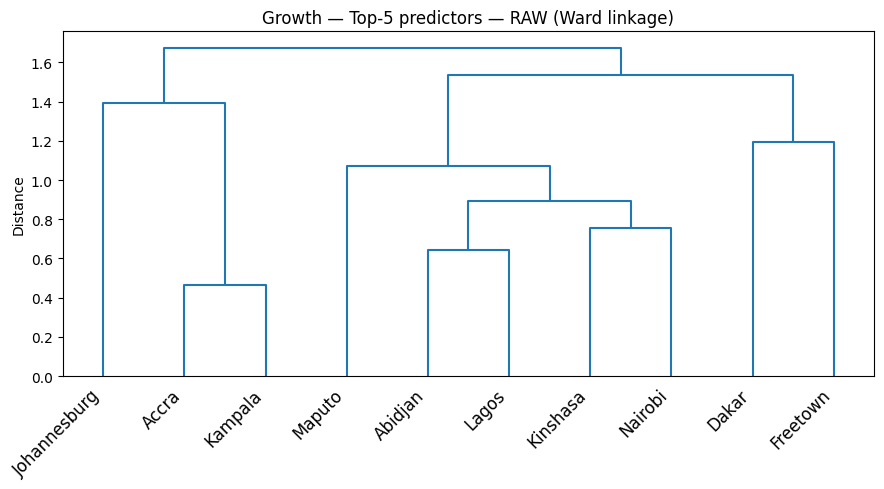

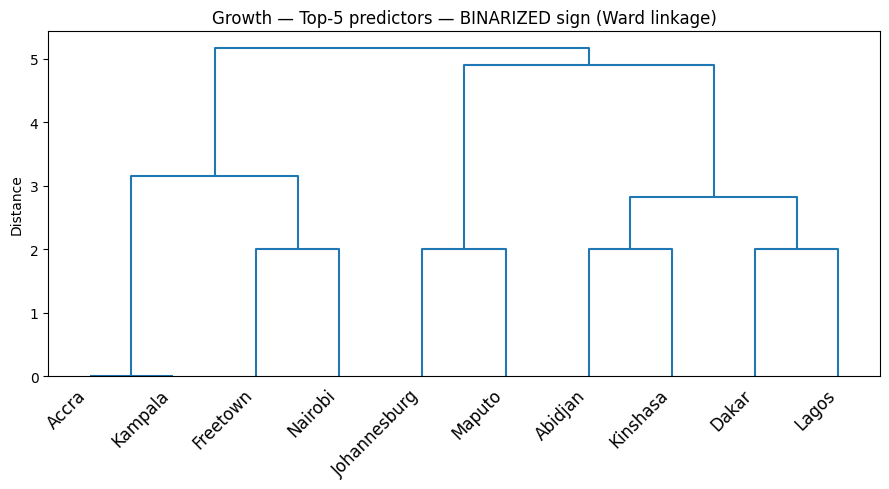


Top-5 predictors — cluster groups

Top-5 RAW (Ward) (k=2):
  Cluster 1: Accra, Johannesburg, Kampala
  Cluster 2: Abidjan, Dakar, Freetown, Kinshasa, Lagos, Maputo, Nairobi

Top-5 RAW (Ward) (k=3):
  Cluster 1: Accra, Johannesburg, Kampala
  Cluster 2: Abidjan, Kinshasa, Lagos, Maputo, Nairobi
  Cluster 3: Dakar, Freetown

Top-5 RAW (Ward) (k=4):
  Cluster 1: Accra, Kampala
  Cluster 2: Johannesburg
  Cluster 3: Abidjan, Kinshasa, Lagos, Maputo, Nairobi
  Cluster 4: Dakar, Freetown

Top-5 BINARIZED (Ward) (k=2):
  Cluster 1: Accra, Freetown, Kampala, Nairobi
  Cluster 2: Abidjan, Dakar, Johannesburg, Kinshasa, Lagos, Maputo

Top-5 BINARIZED (Ward) (k=3):
  Cluster 1: Accra, Freetown, Kampala, Nairobi
  Cluster 2: Johannesburg, Maputo
  Cluster 3: Abidjan, Dakar, Kinshasa, Lagos

Top-5 BINARIZED (Ward) (k=4):
  Cluster 1: Accra, Kampala
  Cluster 2: Freetown, Nairobi
  Cluster 3: Johannesburg, Maputo
  Cluster 4: Abidjan, Dakar, Kinshasa, Lagos


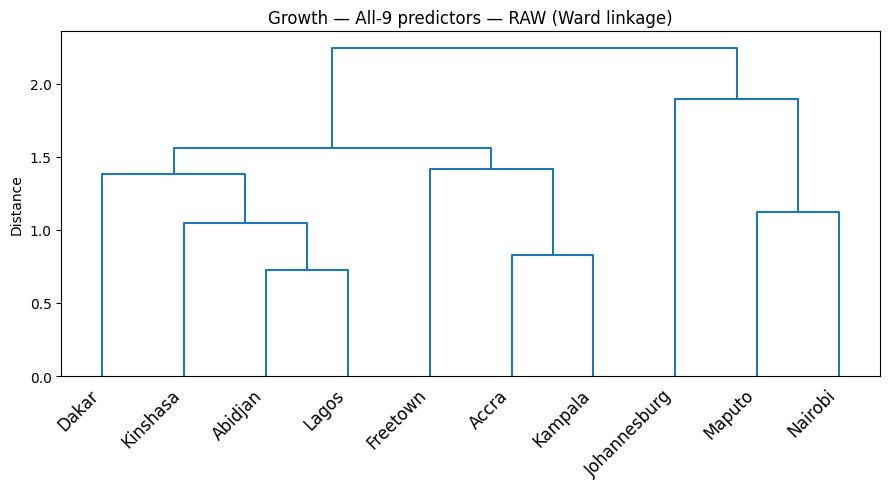

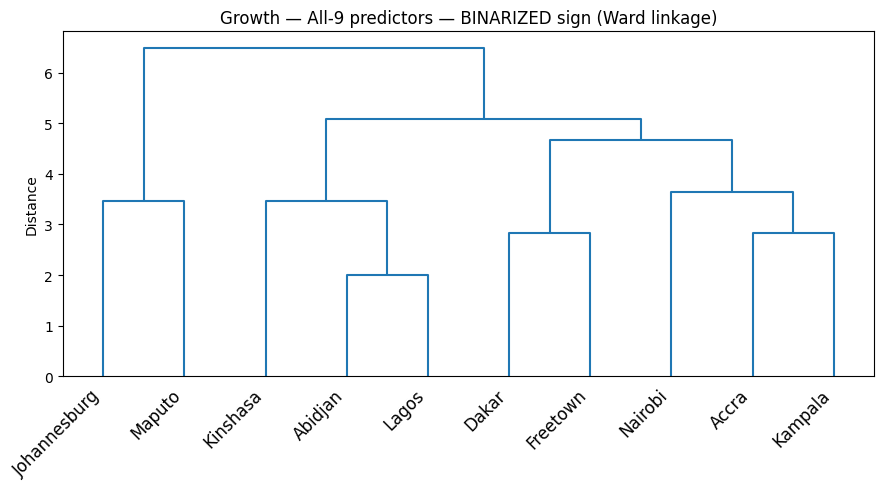


All-9 predictors — cluster groups

All-9 RAW (Ward) (k=2):
  Cluster 1: Abidjan, Accra, Dakar, Freetown, Kampala, Kinshasa, Lagos
  Cluster 2: Johannesburg, Maputo, Nairobi

All-9 RAW (Ward) (k=3):
  Cluster 1: Abidjan, Accra, Dakar, Freetown, Kampala, Kinshasa, Lagos
  Cluster 2: Maputo, Nairobi
  Cluster 3: Johannesburg

All-9 RAW (Ward) (k=4):
  Cluster 1: Abidjan, Dakar, Kinshasa, Lagos
  Cluster 2: Accra, Freetown, Kampala
  Cluster 3: Maputo, Nairobi
  Cluster 4: Johannesburg

All-9 BINARIZED (Ward) (k=2):
  Cluster 1: Johannesburg, Maputo
  Cluster 2: Abidjan, Accra, Dakar, Freetown, Kampala, Kinshasa, Lagos, Nairobi

All-9 BINARIZED (Ward) (k=3):
  Cluster 1: Johannesburg, Maputo
  Cluster 2: Abidjan, Kinshasa, Lagos
  Cluster 3: Accra, Dakar, Freetown, Kampala, Nairobi

All-9 BINARIZED (Ward) (k=4):
  Cluster 1: Johannesburg, Maputo
  Cluster 2: Abidjan, Kinshasa, Lagos
  Cluster 3: Dakar, Freetown
  Cluster 4: Accra, Kampala, Nairobi


In [ ]:
"""
Stage 3 (Growth) only. Builds city x predictor correlation matrices for both
the top-5 predictor set and the full 9-predictor set, then clusters each
using Ward linkage (chosen to avoid the cascading/pairs-at-most chaining
average linkage produced) on both the raw correlation values and the
binarized (sign-only) version — 4 dendrograms total, plus extracted cluster
membership lists at a few k values.

Uses the 75th-percentile Growth subgroup + matching sensitivity SHAP array,
same as the original pipeline. Run in Colab after mounting Drive.
Not saved to Drive.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

delta_predictors = ["delta_population", "delta_slum", "delta_ntl", "delta_dist_open_edge",
                     "delta_building_density", "delta_building_height", "delta_infra_distance",
                     "delta_arterial_roads", "delta_tertiary_roads"]

TOP5_DELTA = ["delta_infra_distance", "delta_ntl", "delta_population", "delta_slum", "delta_arterial_roads"]

DISPLAY_LABELS = {
    "delta_population": "Population", "delta_slum": "Slum", "delta_ntl": "NTL",
    "delta_dist_open_edge": "Dist open edge", "delta_building_density": "Building density",
    "delta_building_height": "Building height", "delta_infra_distance": "Infra distance",
    "delta_arterial_roads": "Arterial roads", "delta_tertiary_roads": "Tertiary roads",
}

PCT = 75


def build_stage3_X(df, pct):
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = np.percentile(emergent_all["DV_2024"], pct)
    i_cut = np.percentile(increase_all["DV_2024"], pct)
    return pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut],
                       increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)[delta_predictors]


def build_growth_corr_matrix(predictor_set):
    """City x predictor_set correlation matrix for Stage 3 (Growth), 75th percentile."""
    rows = []
    for city in cities:
        c = city.lower()
        combined_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Combined/{city}"
        sens_dir = f"/content/drive/MyDrive/Paper_3/Processing/DV/Sensitivity/{city}"
        df = pd.read_csv(f"{combined_dir}/{c}_grid30m_combined.csv")
        X = build_stage3_X(df, PCT)
        shap_vals = np.load(f"{sens_dir}/{c}_stage3_growth_shap_values_pct{PCT}.npy")
        shap_df = pd.DataFrame(shap_vals, columns=delta_predictors, index=X.index)

        row = {"city": city}
        for p in predictor_set:
            row[DISPLAY_LABELS[p]] = X[p].corr(shap_df[p])
        rows.append(row)

    matrix = pd.DataFrame(rows).set_index("city")
    return matrix.fillna(0)


def plot_dendrogram(matrix, title, method="ward", metric="euclidean"):
    Z = linkage(matrix.values, method=method, metric=metric)
    fig, ax = plt.subplots(figsize=(9, 5))
    dendrogram(Z, labels=matrix.index.tolist(), ax=ax, color_threshold=0)
    ax.set_title(title, fontsize=12)
    ax.set_ylabel("Distance")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    return Z


def print_cluster_groups(Z, city_labels, ks, title):
    for k in ks:
        cluster_ids = fcluster(Z, t=k, criterion="maxclust")
        groups = {}
        for city, cid in zip(city_labels, cluster_ids):
            groups.setdefault(cid, []).append(city)
        print(f"\n{title} (k={k}):")
        for cid, members in sorted(groups.items()):
            print(f"  Cluster {cid}: {', '.join(members)}")


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":
    corr_top5 = build_growth_corr_matrix(TOP5_DELTA)
    corr_all9 = build_growth_corr_matrix(delta_predictors)

    print("### Stage 3 (Growth) \u2014 top-5 predictor correlation matrix ###")
    print(corr_top5.round(3).to_string())
    print("\n### Stage 3 (Growth) \u2014 all-9 predictor correlation matrix ###")
    print(corr_all9.round(3).to_string())

    results = {}
    for label, matrix in [("Top-5", corr_top5), ("All-9", corr_all9)]:
        raw = matrix
        binary = np.sign(matrix)

        Z_raw = plot_dendrogram(raw, f"Growth \u2014 {label} predictors \u2014 RAW (Ward linkage)")
        Z_bin = plot_dendrogram(binary, f"Growth \u2014 {label} predictors \u2014 BINARIZED sign (Ward linkage)")

        results[f"{label}_raw"] = Z_raw
        results[f"{label}_binary"] = Z_bin

        print(f"\n{'='*60}\n{label} predictors \u2014 cluster groups\n{'='*60}")
        print_cluster_groups(Z_raw, cities, [2, 3, 4], f"{label} RAW (Ward)")
        print_cluster_groups(Z_bin, cities, [2, 3, 4], f"{label} BINARIZED (Ward)")

In [ ]:
"""
Building density: 2016 vs 2024 mean/median and % change, within pooled
Growth (Emergent+Increase) and Decline (Cleared+Decrease) at the 75th
percentile DV cut — same treatment already applied to Population, NTL,
Slum, and Infrastructure distance.

Run in Colab after mounting Drive. Nothing saved to Drive.
"""

import pandas as pd

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
PCT = 75


def build_growth_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = emergent_all["DV_2024"].quantile(pct / 100)
    i_cut = increase_all["DV_2024"].quantile(pct / 100)
    return pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut],
                       increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)


def build_decline_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    cl_cut = cleared_all["DV_2016"].quantile(pct / 100)
    dec_cut = decrease_all["DV_2016"].quantile(pct / 100)
    return pd.concat([cleared_all[cleared_all["DV_2016"] >= cl_cut],
                       decrease_all[decrease_all["DV_2016"] >= dec_cut]], ignore_index=True)


def compute_building_density_shift(cities, pct=PCT):
    rows = []
    for city in cities:
        growth = build_growth_75(city, pct)
        decline = build_decline_75(city, pct)

        for subgroup_name, data in [("Growth", growth), ("Decline", decline)]:
            x16 = data["Building_density_2016"]
            x24 = data["Building_density_2024"]
            diff = x24 - x16
            pct_change = (x24.mean() - x16.mean()) / x16.mean() * 100 if x16.mean() != 0 else float("nan")

            rows.append({
                "city": city, "subgroup": subgroup_name, "n": len(data),
                "mean_2016": x16.mean(), "mean_2024": x24.mean(), "mean_diff": diff.mean(),
                "pct_change": pct_change,
                "median_2016": x16.median(), "median_2024": x24.median(),
                "median_of_diff": diff.median(), "diff_of_medians": x24.median() - x16.median(),
            })
    return pd.DataFrame(rows)


def consistency_summary(shift_df, n_cities):
    for subgroup in ["Growth", "Decline"]:
        sub = shift_df[shift_df["subgroup"] == subgroup]
        n_pos = (sub["pct_change"] > 0).sum()
        n_neg = (sub["pct_change"] < 0).sum()
        print(f"{subgroup}: {n_pos}/{n_cities} cities positive, {n_neg}/{n_cities} negative "
              f"| mean of city %changes = {sub['pct_change'].mean():.1f}% "
              f"| median of city %changes = {sub['pct_change'].median():.1f}%")


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    shift_df = compute_building_density_shift(cities, pct=75)

    print("### Building density \u2014 Growth vs Decline, 2016 vs 2024 ###")
    print(shift_df.round(3).to_string(index=False))

    print("\n### Cross-city consistency (sign of mean pct_change) ###")
    consistency_summary(shift_df, n_cities=len(cities))

    print("\n### Growth vs Decline % change comparison, per city ###")
    pivot = shift_df.pivot(index="city", columns="subgroup", values="pct_change").round(1)
    pivot["Growth_larger"] = pivot["Growth"] > pivot["Decline"]
    print(pivot.to_string())

### Building density — Growth vs Decline, 2016 vs 2024 ###
        city subgroup     n  mean_2016  mean_2024  mean_diff  pct_change  median_2016  median_2024  median_of_diff  diff_of_medians
     Abidjan   Growth 14737      0.001      0.001        0.0      45.197        0.000        0.001             0.0            0.001
     Abidjan  Decline 10653      0.001      0.001        0.0      26.664        0.001        0.001             0.0            0.000
       Accra   Growth 29533      0.001      0.001        0.0      74.262        0.000        0.000             0.0            0.000
       Accra  Decline 53674      0.001      0.001        0.0      64.550        0.000        0.001             0.0            0.000
       Dakar   Growth 15238      0.001      0.001        0.0      24.826        0.000        0.001             0.0            0.000
       Dakar  Decline 10510      0.001      0.001        0.0      15.759        0.000        0.001             0.0            0.000
    Freetown   Gr

In [ ]:
"""
Building density: 2016 vs 2024 mean/median and % change, within pooled
Growth (Emergent+Increase) and Decline (Cleared+Decrease) at the 75th
percentile DV cut — same treatment already applied to Population, NTL,
Slum, and Infrastructure distance.

Run in Colab after mounting Drive. Nothing saved to Drive.
"""

import pandas as pd

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
PCT = 75
SCALE = 1e3                  # rescale so differences are readable
SCALE_LABEL = "×10⁻³"        # state this in the axis label / caption

def build_growth_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = emergent_all["DV_2024"].quantile(pct / 100)
    i_cut = increase_all["DV_2024"].quantile(pct / 100)
    return pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut],
                       increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)


def build_decline_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    cl_cut = cleared_all["DV_2016"].quantile(pct / 100)
    dec_cut = decrease_all["DV_2016"].quantile(pct / 100)
    return pd.concat([cleared_all[cleared_all["DV_2016"] >= cl_cut],
                       decrease_all[decrease_all["DV_2016"] >= dec_cut]], ignore_index=True)


def compute_building_density_shift(cities, pct=PCT):
    rows = []
    for city in cities:
        growth = build_growth_75(city, pct)
        decline = build_decline_75(city, pct)

        for subgroup_name, data in [("Growth", growth), ("Decline", decline)]:
            x16 = data["Building_density_2016"] * SCALE
            x24 = data["Building_density_2024"] * SCALE
            diff = x24 - x16
            pct_change = (x24.mean() - x16.mean()) / x16.mean() * 100 if x16.mean() != 0 else float("nan")

            rows.append({
                "city": city, "subgroup": subgroup_name, "predictor": "Building density", "n": len(data),
                "mean_2016": x16.mean(), "mean_2024": x24.mean(), "mean_diff": diff.mean(),
                "median_2016": x16.median(), "median_2024": x24.median(),
                "median_of_diff": diff.median(), "diff_of_medians": x24.median() - x16.median(),
                "pct_change": pct_change,
            })

    return pd.DataFrame(rows)


def consistency_summary(shift_df, n_cities):
    for subgroup in ["Growth", "Decline"]:
        sub = shift_df[shift_df["subgroup"] == subgroup]
        n_pos = (sub["pct_change"] > 0).sum()
        n_neg = (sub["pct_change"] < 0).sum()
        print(f"{subgroup}: {n_pos}/{n_cities} cities positive, {n_neg}/{n_cities} negative "
              f"| mean of city %changes = {sub['pct_change'].mean():.1f}% "
              f"| median of city %changes = {sub['pct_change'].median():.1f}%")


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]

    shift_df = compute_building_density_shift(cities, pct=75)

    print(f"### Building density ({SCALE_LABEL}) \u2014 Growth vs Decline, 2016 vs 2024 ###")
    print(shift_df.drop(columns="pct_change").round(3).to_string(index=False))

    from scipy.stats import wilcoxon
    g = shift_df[shift_df.subgroup == "Growth"].set_index("city")
    d = shift_df[shift_df.subgroup == "Decline"].set_index("city")
    diff = g["mean_diff"] - d["mean_diff"]
    print(f"\nAbsolute change, growth > decline: {(diff > 0).sum()}/{len(diff)} cities, "
          f"Wilcoxon p = {wilcoxon(diff).pvalue:.3f}")
    print(f"Baseline, growth lower than decline: {(g['mean_2016'] < d['mean_2016']).sum()}/{len(g)} cities")

### Building density (×10⁻³) — Growth vs Decline, 2016 vs 2024 ###
        city subgroup        predictor     n  mean_2016  mean_2024  mean_diff  median_2016  median_2024  median_of_diff  diff_of_medians
     Abidjan   Growth Building density 14737      0.894      1.298      0.413        0.364        0.971           0.227            0.607
     Abidjan  Decline Building density 10653      1.042      1.320      0.281        0.636        1.052           0.162            0.416
       Accra   Growth Building density 29533      0.556      0.969      0.413        0.066        0.455           0.128            0.389
       Accra  Decline Building density 53674      0.680      1.119      0.439        0.292        0.753           0.239            0.461
       Dakar   Growth Building density 15238      0.953      1.189      0.236        0.408        0.777           0.041            0.369
       Dakar  Decline Building density 10510      0.947      1.096      0.149        0.463        0.661        

In [ ]:
"""
Cross-references the spatial growth-mode typology (consolidation vs
proliferation) against the predictor-driven Growth/Decline shift results,
to check whether the infrastructure/road-proximity driver holds equally
across both spatial modes, or differs between them.

Reuses the same 75th-percentile Growth/Decline builders used throughout.
Run in Colab after mounting Drive. Nothing saved to Drive.
"""

import pandas as pd
import numpy as np

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
PCT = 75

# ============================================================
# Spatial-mode grouping (from the earlier NN/CE + site-size analysis)
# ============================================================

CITY_GROUPS = {
    "Abidjan": "Proliferation",
    "Accra": "Consolidation",
    "Dakar": "Proliferation",
    "Freetown": "Proliferation",
    "Johannesburg": "Other",          # excluded from group comparison — distinct mode
    "Kampala": "Consolidation",       # milder consolidation signature
    "Kinshasa": "Proliferation",
    "Lagos": "Consolidation",
    "Maputo": "Consolidation",        # milder consolidation signature
    "Nairobi": "Consolidation",       # milder consolidation signature
}

PREDICTORS = {
    "Infra_distance": "Infrastructure distance",
    "NTL": "NTL",
    "Population": "Population",
    "Slum": "Slum",
    "Arterial_roads": "Arterial roads",
    "Building_density": "Building density",
}


# ============================================================
# Growth / Decline subgroup builders (same logic as prior blocks)
# ============================================================

def build_growth_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    emergent_all = df[(df["DV_2024"] > 0) & (df["DV_2016"] == 0)].copy()
    increase_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2024"] > df["DV_2016"])].copy()
    e_cut = emergent_all["DV_2024"].quantile(pct / 100)
    i_cut = increase_all["DV_2024"].quantile(pct / 100)
    return pd.concat([emergent_all[emergent_all["DV_2024"] >= e_cut],
                       increase_all[increase_all["DV_2024"] >= i_cut]], ignore_index=True)


def build_decline_75(city, pct=PCT):
    c = city.lower()
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{c}_grid30m_combined.csv")
    cleared_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] == 0)].copy()
    decrease_all = df[(df["DV_2016"] > 0) & (df["DV_2024"] > 0) & (df["DV_2016"] > df["DV_2024"])].copy()
    cl_cut = cleared_all["DV_2016"].quantile(pct / 100)
    dec_cut = decrease_all["DV_2016"].quantile(pct / 100)
    return pd.concat([cleared_all[cleared_all["DV_2016"] >= cl_cut],
                       decrease_all[decrease_all["DV_2016"] >= dec_cut]], ignore_index=True)


# ============================================================
# Per-city, per-predictor % change (mean-based, matches earlier blocks)
# ============================================================

def compute_pct_change_table(cities, pct=PCT):
    rows = []
    for city in cities:
        growth = build_growth_75(city, pct)
        decline = build_decline_75(city, pct)

        for subgroup_name, data in [("Growth", growth), ("Decline", decline)]:
            for p, label in PREDICTORS.items():
                x16 = data[f"{p}_2016"]
                x24 = data[f"{p}_2024"]
                pct_change = ((x24.mean() - x16.mean()) / x16.mean() * 100) if x16.mean() != 0 else np.nan

                rows.append({
                    "city": city,
                    "group": CITY_GROUPS[city],
                    "subgroup": subgroup_name,
                    "predictor": label,
                    "pct_change": pct_change,
                })
    return pd.DataFrame(rows)


# ============================================================
# Group comparison: Consolidation vs Proliferation, per predictor
# ============================================================

def group_comparison(shift_df):
    comparison = (
        shift_df[shift_df["group"].isin(["Consolidation", "Proliferation"])]
        .groupby(["predictor", "subgroup", "group"])["pct_change"]
        .mean()
        .unstack("group")
        .round(1)
    )
    comparison["Difference (Consol - Prolif)"] = (
        comparison["Consolidation"] - comparison["Proliferation"]
    ).round(1)
    return comparison


# ============================================================
# Main
# ============================================================

if __name__ == "__main__":
    cities = list(CITY_GROUPS.keys())

    shift_df = compute_pct_change_table(cities, pct=PCT)

    print("### Per-city % change by predictor (with spatial-mode group) ###")
    print(shift_df.pivot_table(index=["group", "city"], columns=["predictor", "subgroup"],
                                values="pct_change").round(1).to_string())

    print("\n\n### Consolidation vs Proliferation — mean % change by predictor ###")
    print(group_comparison(shift_df).to_string())

### Per-city % change by predictor (with spatial-mode group) ###
predictor                  Arterial roads        Building density        Infrastructure distance            NTL        Population           Slum       
subgroup                          Decline Growth          Decline Growth                 Decline Growth Decline Growth    Decline Growth Decline Growth
group         city                                                                                                                                     
Consolidation Accra                  -3.0   -5.7             64.5   74.3                   -18.4  -15.8   154.2  154.0       17.3   17.8    18.2   22.6
              Kampala                -3.7   -0.7             30.9   47.3                    -6.1   -7.5   129.2  176.5       29.2   28.7     0.5   13.1
              Lagos                   1.3   -0.8             35.0   39.4                    -7.3   -6.4    49.5   44.9       18.3   18.6    99.9   63.1
              Maputo   

In [ ]:
"""
Hotspot-level comparison of urban change around Emergent, Growth and Decline cores.

1. For every city, find strict hotspot cores (same rule as the Abidjan trial):
   separated peaks of the type's change signal, top 25% of peaks, purity >= 0.8,
   no disk overlapping a core of another type.
2. For each core, average each predictor over its disk in 2016 and 2024.
3. Per predictor, fit  change = baseline + type + city  with one observation per hotspot
   (Decline is the reference type) and robust (HC3) standard errors.
Primary radius 1 km; 0.5 km as sensitivity. Nothing is saved.
"""

import math
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from pyproj import Transformer
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree

# ============================================================
# CONFIG
# ============================================================
COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
CITIES = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
RADII = [1000, 500]               # first = primary
CELL = 32
CORE_PCT = 75
PURITY_MIN = {"Emergent": 0.8, "Growth": 0.8, "Decline": 0.8}
TYPES = ["Emergent", "Growth", "Decline"]
MIN_PER_TYPE = 5                 # a type needs at least this many hotspots to be compared

PREDICTORS = {                     # name -> column stem in the combined grid ({stem}_2016 / {stem}_2024)
    "Building density": "Building_density",
    "Population": "Population",
    "Infrastructure distance": "Infra_distance",
    "Distance to arterial roads": "Arterial_roads",
    "NTL radiance": "NTL",
    "Slum probability": "Slum",
}


def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"


def disk(radius_px):
    k = np.arange(-radius_px, radius_px + 1)
    return (k[:, None] ** 2 + k[None, :] ** 2) <= radius_px ** 2


# ============================================================
# CORE DETECTION FOR ONE CITY
# ============================================================
def city_cores(df, utm, radius):
    fwd = Transformer.from_crs("EPSG:4326", utm, always_xy=True)
    x, y = fwd.transform(df.longitude.to_numpy(), df.latitude.to_numpy())
    x0, y1 = x.min(), y.max()
    nx = int(np.ceil((x.max() - x0) / CELL)) + 1
    ny = int(np.ceil((y1 - y.min()) / CELL)) + 1
    idx = ((y1 - y) // CELL).astype(int) * nx + ((x - x0) // CELL).astype(int)
    cnt = np.bincount(idx, minlength=nx * ny)

    def ras(v):
        s = np.bincount(idx, weights=v, minlength=nx * ny)
        return np.where(cnt > 0, s / np.maximum(cnt, 1), np.nan).reshape(ny, nx)

    dv16, dv24 = ras(df.DV_2016.to_numpy()), ras(df.DV_2024.to_numpy())
    ok = np.isfinite(dv16) & np.isfinite(dv24)
    masks = {"Emergent": ok & (dv16 == 0) & (dv24 > 0),
             "Growth": ok & (dv16 > 0) & (dv24 > dv16),
             "Decline": ok & (dv16 > 0) & (dv24 < dv16)}
    sig = {"Emergent": np.where(masks["Emergent"], dv24, 0.0),
           "Growth": np.where(masks["Growth"], dv24 - dv16, 0.0),
           "Decline": np.where(masks["Decline"], dv16 - dv24, 0.0)}
    any_w = masks["Emergent"] | masks["Growth"] | masks["Decline"]

    sep_px, rad_px = int(round(2 * radius / CELL)), int(round(radius / CELL))
    fp = disk(rad_px)
    out = []
    for kind in TYPES:
        s = sig[kind]
        peaks = (s == maximum_filter(s, footprint=disk(sep_px))) & (s > 0)
        r, c = np.nonzero(peaks)
        o = np.argsort(-s[r, c])
        kept = []
        for ri, ci in zip(r[o], c[o]):
            if all((ri - a) ** 2 + (ci - b) ** 2 > sep_px ** 2 for a, b in kept):
                kept.append((ri, ci))
        if not kept:
            continue
        strength = np.array([s[ri, ci] for ri, ci in kept])
        cut = np.percentile(strength, CORE_PCT)
        for (ri, ci), st in zip(kept, strength):
            if st < cut:
                continue
            r0, r1 = max(ri - rad_px, 0), min(ri + rad_px + 1, ny)
            c0, c1 = max(ci - rad_px, 0), min(ci + rad_px + 1, nx)
            f = fp[r0 - ri + rad_px: r1 - ri + rad_px, c0 - ci + rad_px: c1 - ci + rad_px]
            purity = masks[kind][r0:r1, c0:c1][f].sum() / max(any_w[r0:r1, c0:c1][f].sum(), 1)
            if purity < PURITY_MIN[kind]:
                continue
            out.append({"type": kind, "x": x0 + (ci + 0.5) * CELL, "y": y1 - (ri + 0.5) * CELL,
                        "strength_e5": st * 1e5, "purity": purity})
    cores = pd.DataFrame(out)
    if len(cores) > 1:                                   # drop cross-type overlaps
        drop = set()
        for i, j in cKDTree(cores[["x", "y"]].to_numpy()).query_pairs(2 * radius):
            if cores.type.iat[i] != cores.type.iat[j]:
                drop.update([i, j])
        cores = cores.drop(index=list(drop)).reset_index(drop=True)
    return cores, x, y


# ============================================================
# PREDICTOR MEANS WITHIN EACH DISK
# ============================================================
rows = []
for city in CITIES:
    cols = ["longitude", "latitude", "DV_2016", "DV_2024"] + \
           [f"{stem}_{yr}" for stem in PREDICTORS.values() for yr in (2016, 2024)]
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{city.lower()}_grid30m_combined.csv", usecols=cols)
    df = df.dropna(subset=["longitude", "latitude", "DV_2016", "DV_2024"]).reset_index(drop=True)
    utm = utm_epsg(df.longitude.mean(), df.latitude.mean())
    for radius in RADII:
        cores, x, y = city_cores(df, utm, radius)
        if cores.empty:
            continue
        tree = cKDTree(np.column_stack([x, y]))
        for k, core in cores.iterrows():
            members = tree.query_ball_point([core.x, core.y], radius)
            sub = df.iloc[members]
            row = {"city": city, "radius_m": radius, "type": core.type, "core_id": f"{city[:3]}-{core.type[0]}{k}",
                   "strength_e5": core.strength_e5, "purity": core.purity, "cells": len(sub)}
            for name, stem in PREDICTORS.items():
                row[f"{stem}_2016"] = sub[f"{stem}_2016"].mean()
                row[f"{stem}_2024"] = sub[f"{stem}_2024"].mean()
            rows.append(row)
    print(f"{city:13s} done")

hot = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print("\n### Cores per city and type ###")
print(hot.pivot_table(index="city", columns=["radius_m", "type"], values="core_id",
                      aggfunc="count", fill_value=0).to_string())


# ============================================================
# MODELS: change ~ baseline + type + city  (one row per hotspot)
# ============================================================
def fit(d, stem):
    d = d.rename(columns={f"{stem}_2016": "base", f"{stem}_2024": "y24"}).dropna(subset=["base", "y24"])
    d = d.assign(change=d.y24 - d.base)
    counts = d["type"].value_counts()
    present = [t for t in ["Decline", "Growth", "Emergent"] if counts.get(t, 0) >= MIN_PER_TYPE]
    if "Decline" not in present or len(present) < 2:
        return {}, len(d)
    d = d[d["type"].isin(present)].copy()
    d["type"] = pd.Categorical(d["type"], categories=present)
    m = smf.ols("change ~ base + C(type) + C(city)", data=d).fit(cov_type="HC3")
    scale = 100 / d.base.mean()
    out = {}
    for t in ["Growth", "Emergent"]:
        term = f"C(type)[T.{t}]"
        if term in m.params:
            lo, hi = m.conf_int().loc[term]
            out[t] = (m.params[term] * scale, lo * scale, hi * scale, m.pvalues[term])
    return out, len(d)


res = []
for radius in RADII:
    d = hot[hot.radius_m == radius]
    for name, stem in PREDICTORS.items():
        effects, n = fit(d, stem)
        for t, (e, lo, hi, p) in effects.items():
            res.append({"radius_m": radius, "predictor": name, "contrast": f"{t} vs Decline",
                        "effect_%": e, "CI_low": lo, "CI_high": hi, "p": p, "hotspots": n})
res = pd.DataFrame(res)

print("\n### Effect vs Decline cores, controlling for 2016 level and city (% of mean 2016 value, HC3) ###")
for radius in RADII:
    tag = "PRIMARY" if radius == RADII[0] else "sensitivity"
    print(f"\n--- radius {radius} m ({tag}) ---")
    print(res[res.radius_m == radius].drop(columns="radius_m").round(3).to_string(index=False))

# Descriptive: mean change per type (absolute), primary radius
d = hot[hot.radius_m == RADII[0]]
desc = {name: (d[f"{stem}_2024"] - d[f"{stem}_2016"]).groupby(d["type"]).mean()
        for name, stem in PREDICTORS.items()}
print(f"\n### Mean absolute change 2016–2024 by core type ({RADII[0]} m) ###")
print(pd.DataFrame(desc).T.round(4).to_string())

Abidjan       done
Accra         done
Dakar         done
Freetown      done
Johannesburg  done
Kampala       done
Kinshasa      done
Lagos         done
Maputo        done
Nairobi       done

### Cores per city and type ###
radius_m        500                     1000                
type         Decline Emergent Growth Decline Emergent Growth
city                                                        
Abidjan           12       13     12       3        5      2
Accra             33       15     18      13       11      4
Dakar              5        9      3       1        3      1
Freetown           5        3      5       2        2      0
Johannesburg      40       36     27      11       12      3
Kampala           19        7     12       8        1      5
Kinshasa           9        6      9       1        1      1
Lagos             40        9     24      14        5      7
Maputo            14       11      8       5        3      0
Nairobi           13        8      9       3 

In [ ]:
"""
Hotspot-level comparison of urban change around Emergent, Growth and Decline cores.

1. For every city, find strict hotspot cores (same rule as the Abidjan trial):
   separated peaks of the type's change signal, top 25% of peaks, purity >= 0.8,
   no disk overlapping a core of another type.
2. For each core, average each predictor over its disk in 2016 and 2024.
3. Per predictor, fit  change = baseline + type + city  with one observation per hotspot
   (Decline is the reference type) and robust (HC3) standard errors.
Primary radius 1 km; 0.5 km as sensitivity. Nothing is saved.
"""

import math
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from pyproj import Transformer
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree

# ============================================================
# CONFIG
# ============================================================
COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"
CITIES = ["Abidjan", "Accra", "Dakar", "Freetown", "Johannesburg",
          "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]
RADII = [1000, 500]               # first = primary
CELL = 32
CORE_PCT = 75
PURITY_MIN = {"Emergent": 0.8, "Growth": 0.8, "Decline": 0.8}
TYPES = ["Emergent", "Growth", "Decline"]
MIN_PER_TYPE = 5                 # a type needs at least this many hotspots to be compared

PREDICTORS = {                     # name -> column stem in the combined grid ({stem}_2016 / {stem}_2024)
    "Building density": "Building_density",
    "Population": "Population",
    "Infrastructure distance": "Infra_distance",
    "Distance to arterial roads": "Arterial_roads",
    "NTL radiance": "NTL",
    "Slum probability": "Slum",
}

RADII = [1000]                    # detection radius
MEASURE_RADIUS = {1000: 500}      # detection radius -> radius used to average predictors

def utm_epsg(lon, lat):
    zone = int(math.floor((lon + 180) / 6) + 1)
    return f"EPSG:{32600 + zone}" if lat >= 0 else f"EPSG:{32700 + zone}"


def disk(radius_px):
    k = np.arange(-radius_px, radius_px + 1)
    return (k[:, None] ** 2 + k[None, :] ** 2) <= radius_px ** 2


# ============================================================
# CORE DETECTION FOR ONE CITY
# ============================================================
def city_cores(df, utm, radius):
    fwd = Transformer.from_crs("EPSG:4326", utm, always_xy=True)
    x, y = fwd.transform(df.longitude.to_numpy(), df.latitude.to_numpy())
    x0, y1 = x.min(), y.max()
    nx = int(np.ceil((x.max() - x0) / CELL)) + 1
    ny = int(np.ceil((y1 - y.min()) / CELL)) + 1
    idx = ((y1 - y) // CELL).astype(int) * nx + ((x - x0) // CELL).astype(int)
    cnt = np.bincount(idx, minlength=nx * ny)

    def ras(v):
        s = np.bincount(idx, weights=v, minlength=nx * ny)
        return np.where(cnt > 0, s / np.maximum(cnt, 1), np.nan).reshape(ny, nx)

    dv16, dv24 = ras(df.DV_2016.to_numpy()), ras(df.DV_2024.to_numpy())
    ok = np.isfinite(dv16) & np.isfinite(dv24)
    masks = {"Emergent": ok & (dv16 == 0) & (dv24 > 0),
             "Growth": ok & (dv16 > 0) & (dv24 > dv16),
             "Decline": ok & (dv16 > 0) & (dv24 < dv16)}
    sig = {"Emergent": np.where(masks["Emergent"], dv24, 0.0),
           "Growth": np.where(masks["Growth"], dv24 - dv16, 0.0),
           "Decline": np.where(masks["Decline"], dv16 - dv24, 0.0)}
    any_w = masks["Emergent"] | masks["Growth"] | masks["Decline"]

    sep_px, rad_px = int(round(2 * radius / CELL)), int(round(radius / CELL))
    fp = disk(rad_px)
    out = []
    for kind in TYPES:
        s = sig[kind]
        peaks = (s == maximum_filter(s, footprint=disk(sep_px))) & (s > 0)
        r, c = np.nonzero(peaks)
        o = np.argsort(-s[r, c])
        kept = []
        for ri, ci in zip(r[o], c[o]):
            if all((ri - a) ** 2 + (ci - b) ** 2 > sep_px ** 2 for a, b in kept):
                kept.append((ri, ci))
        if not kept:
            continue
        strength = np.array([s[ri, ci] for ri, ci in kept])
        cut = np.percentile(strength, CORE_PCT)
        for (ri, ci), st in zip(kept, strength):
            if st < cut:
                continue
            r0, r1 = max(ri - rad_px, 0), min(ri + rad_px + 1, ny)
            c0, c1 = max(ci - rad_px, 0), min(ci + rad_px + 1, nx)
            f = fp[r0 - ri + rad_px: r1 - ri + rad_px, c0 - ci + rad_px: c1 - ci + rad_px]
            purity = masks[kind][r0:r1, c0:c1][f].sum() / max(any_w[r0:r1, c0:c1][f].sum(), 1)
            if purity < PURITY_MIN[kind]:
                continue
            out.append({"type": kind, "x": x0 + (ci + 0.5) * CELL, "y": y1 - (ri + 0.5) * CELL,
                        "strength_e5": st * 1e5, "purity": purity})
    cores = pd.DataFrame(out)
    if len(cores) > 1:                                   # drop cross-type overlaps
        drop = set()
        for i, j in cKDTree(cores[["x", "y"]].to_numpy()).query_pairs(2 * radius):
            if cores.type.iat[i] != cores.type.iat[j]:
                drop.update([i, j])
        cores = cores.drop(index=list(drop)).reset_index(drop=True)
    return cores, x, y


# ============================================================
# PREDICTOR MEANS WITHIN EACH DISK
# ============================================================
rows = []
for city in CITIES:
    cols = ["longitude", "latitude", "DV_2016", "DV_2024"] + \
           [f"{stem}_{yr}" for stem in PREDICTORS.values() for yr in (2016, 2024)]
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{city.lower()}_grid30m_combined.csv", usecols=cols)
    df = df.dropna(subset=["longitude", "latitude", "DV_2016", "DV_2024"]).reset_index(drop=True)
    utm = utm_epsg(df.longitude.mean(), df.latitude.mean())
    for radius in RADII:
        cores, x, y = city_cores(df, utm, radius)
        if cores.empty:
            continue
        tree = cKDTree(np.column_stack([x, y]))
        for k, core in cores.iterrows():
            members = tree.query_ball_point([core.x, core.y], MEASURE_RADIUS.get(radius, radius))
            sub = df.iloc[members]
            row = {"city": city, "radius_m": radius, "type": core.type, "core_id": f"{city[:3]}-{core.type[0]}{k}",
                   "strength_e5": core.strength_e5, "purity": core.purity, "cells": len(sub)}
            for name, stem in PREDICTORS.items():
                row[f"{stem}_2016"] = sub[f"{stem}_2016"].mean()
                row[f"{stem}_2024"] = sub[f"{stem}_2024"].mean()
            rows.append(row)
    print(f"{city:13s} done")

hot = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print("\n### Cores per city and type ###")
print(hot.pivot_table(index="city", columns=["radius_m", "type"], values="core_id",
                      aggfunc="count", fill_value=0).to_string())


# ============================================================
# MODELS: change ~ baseline + type + city  (one row per hotspot)
# ============================================================
def fit(d, stem):
    d = d.rename(columns={f"{stem}_2016": "base", f"{stem}_2024": "y24"}).dropna(subset=["base", "y24"])
    d = d.assign(change=d.y24 - d.base)
    counts = d["type"].value_counts()
    present = [t for t in ["Decline", "Growth", "Emergent"] if counts.get(t, 0) >= MIN_PER_TYPE]
    if "Decline" not in present or len(present) < 2:
        return {}, len(d)
    d = d[d["type"].isin(present)].copy()
    d["type"] = pd.Categorical(d["type"], categories=present)
    m = smf.ols("change ~ base + C(type) + C(city)", data=d).fit(cov_type="HC3")
    scale = 100 / d.base.mean()
    out = {}
    for t in ["Growth", "Emergent"]:
        term = f"C(type)[T.{t}]"
        if term in m.params:
            lo, hi = m.conf_int().loc[term]
            out[t] = (m.params[term] * scale, lo * scale, hi * scale, m.pvalues[term])
    return out, len(d)


res = []
for radius in RADII:
    d = hot[hot.radius_m == radius]
    for name, stem in PREDICTORS.items():
        effects, n = fit(d, stem)
        for t, (e, lo, hi, p) in effects.items():
            res.append({"radius_m": radius, "predictor": name, "contrast": f"{t} vs Decline",
                        "effect_%": e, "CI_low": lo, "CI_high": hi, "p": p, "hotspots": n})
res = pd.DataFrame(res)

print("\n### Effect vs Decline cores, controlling for 2016 level and city (% of mean 2016 value, HC3) ###")
for radius in RADII:
    tag = "PRIMARY" if radius == RADII[0] else "sensitivity"
    print(f"\n--- radius {radius} m ({tag}) ---")
    print(res[res.radius_m == radius].drop(columns="radius_m").round(3).to_string(index=False))

# Descriptive: mean change per type (absolute), primary radius
d = hot[hot.radius_m == RADII[0]]
desc = {name: (d[f"{stem}_2024"] - d[f"{stem}_2016"]).groupby(d["type"]).mean()
        for name, stem in PREDICTORS.items()}
print(f"\n### Mean absolute change 2016–2024 by core type ({RADII[0]} m) ###")
print(pd.DataFrame(desc).T.round(4).to_string())

Abidjan       done
Accra         done
Dakar         done
Freetown      done
Johannesburg  done
Kampala       done
Kinshasa      done
Lagos         done
Maputo        done
Nairobi       done

### Cores per city and type ###
radius_m        1000                
type         Decline Emergent Growth
city                                
Abidjan            3        5      2
Accra             13       11      4
Dakar              1        3      1
Freetown           2        2      0
Johannesburg      11       12      3
Kampala            8        1      5
Kinshasa           1        1      1
Lagos             14        5      7
Maputo             5        3      0
Nairobi            3        2      1

### Effect vs Decline cores, controlling for 2016 level and city (% of mean 2016 value, HC3) ###

--- radius 1000 m (PRIMARY) ---
                 predictor            contrast  effect_%  CI_low  CI_high     p  hotspots
          Building density   Growth vs Decline    -2.939 -16.061   10.183 0

In [ ]:
"""
Growth vs Decline: predictor change 2016 -> 2024 (revised).

Changes from the original script, following the review:
  * Growth and Decline are selected by CHANGE in DV (Delta = DV_2024 - DV_2016), symmetrically,
    instead of by DV level in different years. Emergent/Increase and Cleared/Decrease stay pooled
    (deliberate choice) and enter through their change.
  * Stricter selection: a noise floor removes the faint tails of the smoothed DV surface, and only
    the strongest TOP_PCT % of change on each side is kept.
  * Building density added (rescaled so differences are visible).
  * Uncertainty: per city, change ~ baseline + growth with standard errors clustered on ~1 km blocks;
    cities combined by random-effects meta-analysis (each city weighted by its precision, not its cell
    count), with between-city heterogeneity (tau^2, I^2).
  * Johannesburg excluded (its combined grid is a ~1% sample of the 30 m grid).
  * Each city file is read once.

Run in Colab after mounting Drive. Nothing is saved.
"""

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

COMBINED_DIR = "/content/drive/MyDrive/Paper_3/Processing/DV/Combined"

PREDICTORS = ["Building_density", "Infra_distance", "NTL", "Population", "Slum", "Arterial_roads"]
LABELS = {
    "Building_density": "Building density (x10^-3)",
    "Infra_distance": "Infrastructure distance",
    "NTL": "NTL",
    "Population": "Population",
    "Slum": "Slum",
    "Arterial_roads": "Arterial roads",
}
SCALE = {"Building_density": 1e3}      # rescale so differences are readable; others unchanged

TOP_PCT = 10          # keep the strongest 10% of change on each side (primary; try 5 and 25 as sensitivity)
FLOOR_PCT = 10        # noise floor: drop cells whose max(DV_2016, DV_2024) is below this percentile of non-zero DV
BLOCK_DEG = 0.01      # cluster blocks for standard errors (~1.1 km)


# =====================================================================
# Selection by change (one read per city)
# =====================================================================
def build_groups(city, top_pct=TOP_PCT, floor_pct=FLOOR_PCT):
    """Returns (growth, decline) cell sets selected by DV change, symmetrically."""
    df = pd.read_csv(f"{COMBINED_DIR}/{city}/{city.lower()}_grid30m_combined.csv")
    for p, k in SCALE.items():
        for y in (2016, 2024):
            df[f"{p}_{y}"] = df[f"{p}_{y}"] * k

    dv_max = df[["DV_2016", "DV_2024"]].max(axis=1)
    floor = dv_max[dv_max > 0].quantile(floor_pct / 100)
    df = df[dv_max >= floor].copy()
    df["delta"] = df["DV_2024"] - df["DV_2016"]

    gain, loss = df[df["delta"] > 0], df[df["delta"] < 0]
    growth = gain[gain["delta"] >= gain["delta"].quantile(1 - top_pct / 100)]
    decline = loss[loss["delta"] <= loss["delta"].quantile(top_pct / 100)]
    return growth, decline


# =====================================================================
# Descriptive shift table (as before) + per-city tests
# =====================================================================
def compute_shift_table(cities, top_pct=TOP_PCT):
    rows, tests = [], []
    for city in cities:
        growth, decline = build_groups(city, top_pct)

        for subgroup_name, data in [("Growth", growth), ("Decline", decline)]:
            for p in PREDICTORS:
                x16, x24 = data[f"{p}_2016"], data[f"{p}_2024"]
                diff = x24 - x16
                rows.append({
                    "city": city, "subgroup": subgroup_name, "predictor": LABELS[p], "n": len(data),
                    "mean_2016": x16.mean(), "mean_2024": x24.mean(), "mean_diff": diff.mean(),
                    "pct_change": diff.mean() / x16.mean() * 100 if x16.mean() else np.nan,
                    "median_2016": x16.median(), "median_2024": x24.median(),
                    "median_of_diff": diff.median(), "diff_of_medians": x24.median() - x16.median(),
                })

        both = pd.concat([growth.assign(growth=1), decline.assign(growth=0)], ignore_index=True)
        both["block"] = ((both.latitude // BLOCK_DEG).astype(int).astype(str) + "_"
                         + (both.longitude // BLOCK_DEG).astype(int).astype(str))
        for p in PREDICTORS:
            d = both[["growth", "block", f"{p}_2016", f"{p}_2024"]].dropna()
            d = d.rename(columns={f"{p}_2016": "base"}).assign(change=lambda t: t[f"{p}_2024"] - t["base"])
            m = smf.ols("change ~ base + growth", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["block"]})
            k = 100 / d["base"].mean()                   # effect as % of the city's mean 2016 value
            tests.append({"city": city, "predictor": LABELS[p], "effect_pct": m.params["growth"] * k,
                          "se_pct": m.bse["growth"] * abs(k), "p": m.pvalues["growth"], "cells": len(d)})
    return pd.DataFrame(rows), pd.DataFrame(tests)


def random_effects(tests):
    """DerSimonian-Laird random-effects pooling of the per-city growth effects."""
    out = []
    for pred, g in tests.groupby("predictor", sort=False):
        y, v = g["effect_pct"].to_numpy(), g["se_pct"].to_numpy() ** 2
        w = 1 / v
        fixed = np.sum(w * y) / np.sum(w)
        q = np.sum(w * (y - fixed) ** 2)
        dfree = len(y) - 1
        tau2 = max(0.0, (q - dfree) / (np.sum(w) - np.sum(w ** 2) / np.sum(w)))
        wr = 1 / (v + tau2)
        est = np.sum(wr * y) / np.sum(wr)
        se = np.sqrt(1 / np.sum(wr))
        out.append({"predictor": pred, "pooled_effect_pct": est, "CI_low": est - 1.96 * se,
                    "CI_high": est + 1.96 * se, "p": 2 * stats.norm.sf(abs(est / se)),
                    "tau2": tau2, "I2_pct": max(0.0, (q - dfree) / q * 100) if q > 0 else 0.0,
                    "cities_sig_pos": int(((g.p < 0.05) & (g.effect_pct > 0)).sum()),
                    "cities_sig_neg": int(((g.p < 0.05) & (g.effect_pct < 0)).sum())})
    res = pd.DataFrame(out)
    # Benjamini-Hochberg across predictors
    order = np.argsort(res["p"].to_numpy())
    ranked = res["p"].to_numpy()[order] * len(res) / (np.arange(len(res)) + 1)
    q_vals = np.minimum.accumulate(ranked[::-1])[::-1]
    res.loc[res.index[order], "q_BH"] = np.minimum(q_vals, 1)
    return res


def _pretty_print_table(df, title):
    """Fixed-width box-style pretty printer (no extra dependencies)."""
    index_label = df.index.name or ""
    col_names = list(df.columns)
    idx_w = max([len(index_label)] + [len(str(i)) for i in df.index]) + 2
    col_widths = {c: max(len(str(c)), *(len(str(v)) for v in df[c])) + 2 for c in col_names}
    total_w = idx_w + sum(col_widths[c] for c in col_names)
    print("\n" + "=" * total_w)
    print(title)
    print("=" * total_w)
    print(index_label.ljust(idx_w) + "".join(str(c).rjust(col_widths[c]) for c in col_names))
    print("-" * total_w)
    for idx, row in df.iterrows():
        line = str(idx).ljust(idx_w)
        for c in col_names:
            line += str(row[c]).rjust(col_widths[c])
        print(line)
    print("=" * total_w)


def consistency_summary(shift_df, n_cities, sign_basis="mean_diff"):
    """Descriptive only: cities with positive / negative shift per subgroup and predictor."""
    summary_rows = []
    for (subgroup, predictor), g in shift_df.groupby(["subgroup", "predictor"]):
        n_pos, n_neg = (g[sign_basis] > 0).sum(), (g[sign_basis] < 0).sum()
        summary_rows.append({"predictor": predictor, "subgroup": subgroup, "n_positive": n_pos,
                             "majority": "+" if n_pos > n_neg else ("-" if n_neg > n_pos else "tied")})
    summary_df = pd.DataFrame(summary_rows)
    pivot = summary_df.pivot(index="predictor", columns="subgroup", values="n_positive") \
                      .reindex(columns=["Growth", "Decline"]).astype(str) + f"/{n_cities}"
    pivot.index.name = "Predictor"
    _pretty_print_table(pivot, f"CROSS-CITY CONSISTENCY (descriptive) \u2014 cities with positive {sign_basis}")
    return summary_df


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":
    cities = ["Abidjan", "Accra", "Dakar", "Freetown",
              "Kampala", "Kinshasa", "Lagos", "Maputo", "Nairobi"]      # Johannesburg excluded

    shift_df, tests = compute_shift_table(cities, top_pct=TOP_PCT)
    pd.set_option("display.width", 220)

    print(f"Selection: top {TOP_PCT}% of DV change on each side, noise floor P{FLOOR_PCT} of non-zero DV\n")
    for p in LABELS.values():
        print(f"\n### {p} ###")
        print(shift_df[shift_df["predictor"] == p].round(4).to_string(index=False))

    consistency_summary(shift_df, n_cities=len(cities))

    print("\n### Per-city growth effect, controlling for 2016 level (% of city mean; clustered SE) ###")
    print(tests.round(3).to_string(index=False))

    print("\n### Pooled across cities (random effects; each city weighted by precision) ###")
    print(random_effects(tests).round(3).to_string(index=False))

Selection: top 10% of DV change on each side, noise floor P10 of non-zero DV


### Building density (x10^-3) ###
    city subgroup                 predictor     n  mean_2016  mean_2024  mean_diff  pct_change  median_2016  median_2024  median_of_diff  diff_of_medians
 Abidjan   Growth Building density (x10^-3)  5180     1.0799     1.4520     0.4082     37.7956       0.5994       1.2035          0.2460           0.6041
 Abidjan  Decline Building density (x10^-3)  3960     0.9462     1.2555     0.3060     32.3354       0.5210       0.9500          0.1755           0.4290
   Accra   Growth Building density (x10^-3) 11225     0.5829     1.0074     0.4245     72.8357       0.0746       0.4560          0.1226           0.3815
   Accra  Decline Building density (x10^-3) 18729     0.7030     1.1538     0.4508     64.1231       0.3036       0.7880          0.2356           0.4844
   Dakar   Growth Building density (x10^-3)  5374     1.1378     1.3510     0.2132     18.7391       0.7721       1.0